# Applicazione dei concetti utili

## Filtri e Convoluzione 2D (Smoothing e filtro Gaussiano)

Questo è il cuore del tuo esercizio. La lezione mostra visivamente come un filtro Gaussiano *“spalma”* i valori.

Nel tuo progetto, la **PSF (Point Spread Function)** usata nella deconvoluzione è assimilabile a un filtro applicato tramite **convoluzione**.

Comprendere la convoluzione aiuta a capire:
- perché l’immagine si sfoca
- come la deconvoluzione tenta di invertire questo effetto

---

## Gestione dei Bordi (Padding)

Quando si utilizzano funzioni di `skimage.restoration`, è necessario gestire i bordi dell’immagine.

Metodi comuni includono:
- **Zero-padding**
- **Wrap padding**

Questi possono introdurre artefatti, come:
- linee nere ai bordi
- linee bianche ai bordi

Capire il padding è fondamentale per interpretare correttamente i risultati della ricostruzione.

---

## Edge Detection e Profili di intensità

Un bordo in un’immagine può essere modellato come una **funzione a gradino (step function)**.

Quando estrai un **profilo di intensità**, stai analizzando i valori dei pixel lungo una linea che attraversa questo gradino.

Questo permette di valutare:
- se il denoising mantiene bordi netti
- oppure se introduce eccessivo smoothing (bordi più “morbidi”)

---

## Istogrammi per la valutazione

Oltre al calcolo del **Signal-to-Noise Ratio (SNR)**, è utile analizzare gli istogrammi delle immagini:

- Immagine con rumore Gaussiano:  
  → istogramma più *ampio* (distribuzione più dispersa)

- Immagine dopo denoising:  
  → istogramma più *concentrato* verso i valori originali

Questo confronto permette di valutare visivamente l’efficacia del filtro.

---

## (Opzionale) Formula SNR



# Progetto: Miglioramento e Denoising di Immagini Multicanale

Questo documento delinea il flusso di lavoro rigoroso per l'analisi, il restauro e la valutazione quantitativa/qualitativa di immagini biomediche acquisite su 3 canali in scala di grigi.

## 1. Basi Teoriche e Matematiche del Problema
Il processo di degradazione di un'immagine è tipicamente modellato come:
$$y = Ax + v$$
Dove:
*   $y$ = immagine acquisita (degradata)
*   $x$ = immagine originale (ground truth)
*   $A$ = Point Spread Function (PSF) del sistema ottico
*   $v$ = rumore additivo (es. Gaussiano o Poissoniano)

L'obiettivo è ottenere la stima migliore $\hat{x}$ minimizzando l'errore o massimizzando la probabilità a posteriori (MAP):
$$\hat{x}_{MAP} = \arg \min_{x} \left[ \frac{||y - x||^2}{2\sigma^2} - \log(p(x)) \right]$$

*   Nel **Pure Denoising**, si assume che l'operatore $A$ sia la matrice identità ($A = I$), concentrandosi solo sulla riduzione del rumore $v$.
*   Nella **Denoised Deconvolution**, si tenta di invertire la PSF $A$ tenendo conto e regolarizzando il rumore $v$.

---

## 2. Fase 1: Preparazione e Pre-processing dei Dati

### Caricamento dei 3 canali
Carica le tre immagini in scala di grigi (Canale 1, Canale 2, Canale 3). Lavorando su dati volumetrici o stack (es. *“Estrazione della slice Z=12...”*).
**È fondamentale:**
*   Estrarre la stessa slice (es. $Z = 12$) per tutti i canali.
*   Garantire coerenza spaziale tra i canali per la successiva sovrapposizione in RGB.

### Normalizzazione
Assicurati che i valori dei pixel siano normalizzati in modo consistente:
*   In formato float: $[0.0, 1.0]$
*   Oppure in formato intero (`uint8`): $[0, 255]$

Una normalizzazione corretta previene instabilità numeriche negli algoritmi di ottimizzazione di `skimage`.

---

## 3. Fase 2: Definizione degli Algoritmi 

### Ground Truth e Degrado (Fase di Test)
Se si dispone di un'immagine di riferimento perfetta ($x$):
*   Applica una PSF matematica per simulare la sfocatura ottica.
*   Aggiungi rumore statistico per simulare i disturbi fisici di acquisizione.

Se si lavora su dati reali microscopici:
*   Utilizza le immagini rumorose raw come $y$ e sfrutta una PSF empirica o teorica.

### Metodo A: Pure Denoising
L'obiettivo è minimizzare le variazioni ad alta frequenza preservando i bordi.
*   **Total Variation Denoising (TV Chambolle)**: Usa `skimage.restoration.denoise_tv_chambolle`. Cerca di minimizzare l'integrale del gradiente $\int |\nabla x| dv$. La PSF viene ignorata ($A=I$).
*   *Alternative*: `denoise_wavelet` o `denoise_nl_means`.

### Metodo B: Denoised Deconvolution
L'obiettivo è il ripristino del segnale spaziale tramite l'inversione della degradazione ottica.
*   **Deconvoluzione Richardson-Lucy**: Usa `skimage.restoration.richardson_lucy`. Questo approccio iterativo richiede in input sia l'immagine rumorosa $y$ che la PSF $A$.

---

## 4. Fase 3: Valutazione Qualitativa (Immagini e Profili)

### Confronto Visivo
Costruisci una griglia di subplot per uno specifico canale confrontando:
1. Immagine originale corrotta
2. Risultato del Pure Denoising
3. Risultato della Denoised Deconvolution

*Suggerimento:* Effettua uno zoom su una singola cellula per rendere evidenti le differenze sui contorni e le eventuali formazioni di artefatti (come il *boundary ringing*).

### Profili di Intensità (Edge Detection)
Un bordo nitido in un'immagine può essere matematicamente approssimato a una **funzione a gradino** (step function). Il rumore si manifesta come oscillazioni ad alta frequenza attorno a questo gradino.
```python


In [2]:
import numpy as np
from skimage.io import imread, imshow
#import pyclesperanto_prototype as cle
from skimage import measure
import pandas as pd
import seaborn
import apoc
import stackview
from skimage import io
from skimage.data import cells3d
from skimage.io import imread
from skimage.filters import gaussian
from skimage.morphology import ball
from skimage.segmentation import clear_border
from skimage.measure import label, regionprops
from skimage.color import label2rgb
from skimage import img_as_ubyte

import numpy as np

import matplotlib.pyplot as plt
from skimage.io import imread
from skimage import data
from skimage import filters
from skimage import morphology
from scipy.ndimage import convolve, gaussian_laplace
import stackview

/Users/francesco/Library/Python/3.9/lib/python/site-packages/pytools/persistent_dict.py:63: RecommendedHashNotFoundWarning: Unable to import recommended hash 'siphash24.siphash13', falling back to 'hashlib.sha256'. Run 'python3 -m pip install siphash24' to install the recommended hash.
  warn("Unable to import recommended hash 'siphash24.siphash13', "


- Estrazione della slice Z=12...


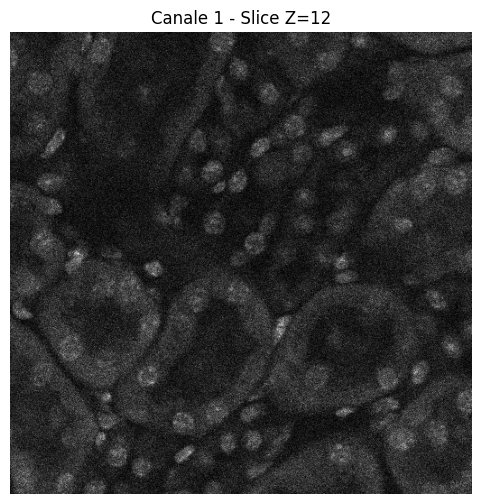

In [3]:
from skimage.io import imread
import matplotlib.pyplot as plt
import os
from pathlib import Path

image = imread("/Users/francesco/Repositories /noise_images/Immagini_donoises/150mic_10ripetizioni_50mW_512px_770nm_Ch1.tif")

CONFIG = {
    "folder_path": "/Users/francesco/Repositories /CNR_SNR_3channels",
    "file_ch1": "zstack_150mic_50piani_10ripetizioni_50mW_512px_770nm_Ch1.tif",
    "file_ch2": "zstack_150mic_50piani_10ripetizioni_50mW_512px_770nm_Ch2.tif",
    "file_ch3": "zstack_150mic_50piani_10ripetizioni_50mW_512px_770nm_Ch3.tif",
    "nomi_canali": ["Canale 1", "Canale 2", "Canale 3"],
    "z_target": 11,       # Indice Python 11 corrisponde alla Z 12/50
    "cmap_visual": "gray" # Scala di grigi globale
}

# ────────────────────────────────────────────────────────────────────────────

os.chdir(CONFIG["folder_path"])
lista_file = [CONFIG["file_ch1"], CONFIG["file_ch2"], CONFIG["file_ch3"]]

immagini_originali = []

# ## 1. Lettura Z-Stacks ed Estrazione Slice Z=12
print(f"- Estrazione della slice Z={CONFIG['z_target'] + 1}...")

for fname in lista_file:
    p = Path(fname)
    if not p.exists():
        raise FileNotFoundError(f"! Impossibile trovare il file: {p.absolute()}")
    
    stack_3d = io.imread(p)
    # Estrae la slice Z desiderata (gestendo sia 3D che 2D come fallback)
    img_raw = stack_3d[CONFIG["z_target"], :, :] if stack_3d.ndim == 3 else stack_3d
    immagini_originali.append(img_raw)
    
#stampo l'immagine sul 12esimo piano, e solo del canale 1
plt.figure(figsize=(6, 6))
plt.imshow(immagini_originali[0], cmap=CONFIG["cmap_visual"])
plt.title(f"{CONFIG['nomi_canali'][0]} - Slice Z={CONFIG['z_target'] + 1}")
plt.axis('off')
plt.show()

[[ 4 11  6 ...  7  4 10]
 [ 8  5  8 ...  9  6  8]
 [11  7  3 ... 13 11 16]
 ...
 [ 5  5  2 ... 11 16  9]
 [ 1  4  8 ... 12  9  8]
 [ 3  4  3 ...  8  8 11]]
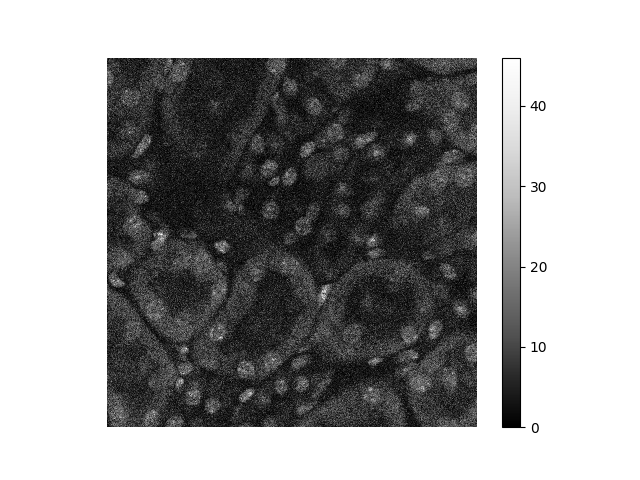
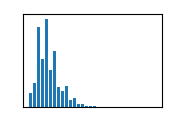

In [4]:

#chiamo l'immagine del canale 1 "img_raw"
image = immagini_originali[0]

stackview.insight(image)



In [5]:
stackview.display_range(image)

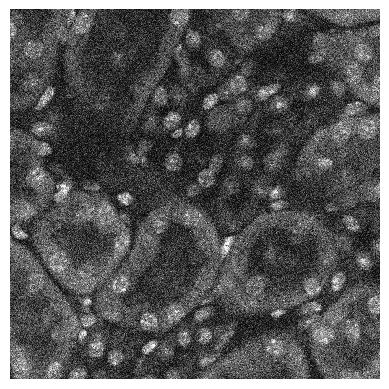

In [6]:
stackview.imshow(image, max_display_intensity=30)

In [7]:
upper_limit = np.percentile(image, 99.5)
upper_limit

#questo serve per vedere se è meglio visualizzare con un limite di 30 o di 100 ad esempio...
#15 ci dice che il 95% dei pixel ha un'intensità inferiore a 15, quindi visualizzare con un limite di 30 potrebbe essere più appropriato per evidenziare i dettagli, mentre un limite di 100 potrebbe rendere l'immagine troppo scura e perdere dettagli importanti.

21.0

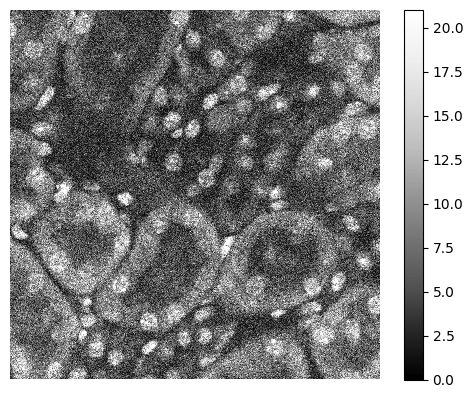

In [8]:
stackview.imshow(image, max_display_intensity=upper_limit, colorbar=True)

/Users/francesco/Library/Python/3.9/lib/python/site-packages/skimage/io/_plugins/matplotlib_plugin.py:158: UserWarning: Low image data range; displaying image with stretched contrast.
  lo, hi, cmap = _get_display_range(image)


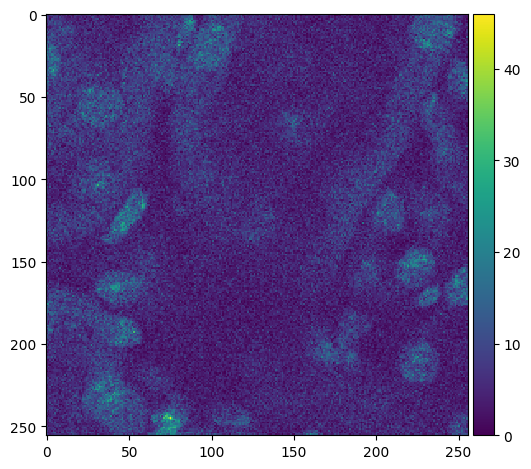

In [9]:
cropped_image1 = image[0:256, 0:256]

imshow(cropped_image1);

[[0.08695652 0.23913043 0.13043478 ... 0.15217391 0.08695652 0.2173913 ]
 [0.17391304 0.10869565 0.17391304 ... 0.19565217 0.13043478 0.17391304]
 [0.23913043 0.15217391 0.06521739 ... 0.2826087  0.23913043 0.34782609]
 ...
 [0.10869565 0.10869565 0.04347826 ... 0.23913043 0.34782609 0.19565217]
 [0.02173913 0.08695652 0.17391304 ... 0.26086957 0.19565217 0.17391304]
 [0.06521739 0.08695652 0.06521739 ... 0.17391304 0.17391304 0.23913043]]
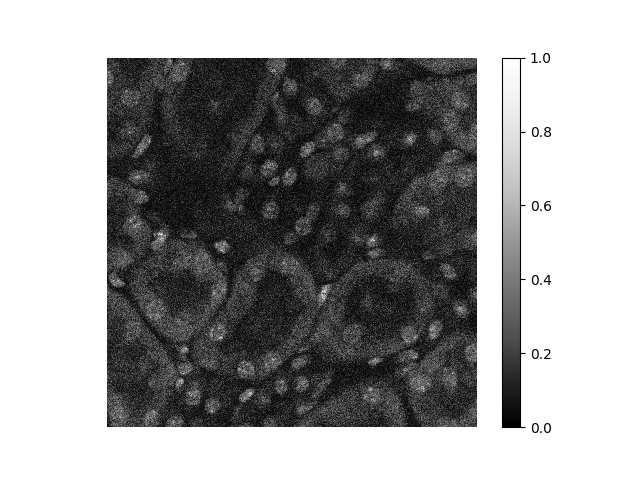
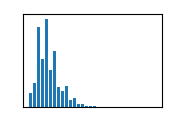

In [10]:
from stackview import insight

min_max = (image - image.min()) / (image.max() - image.min())
insight(min_max)

[[0.375 1.25  0.625 ... 0.75  0.375 1.125]
 [0.875 0.5   0.875 ... 1.    0.625 0.875]
 [1.25  0.75  0.25  ... 1.5   1.25  1.875]
 ...
 [0.5   0.5   0.125 ... 1.25  1.875 1.   ]
 [0.    0.375 0.875 ... 1.375 1.    0.875]
 [0.25  0.375 0.25  ... 0.875 0.875 1.25 ]]
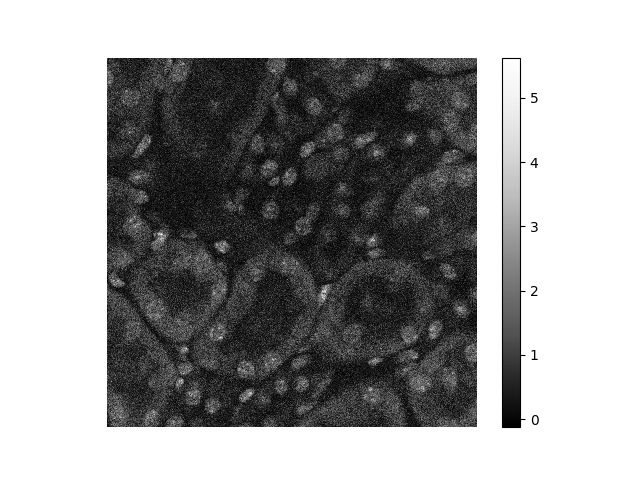
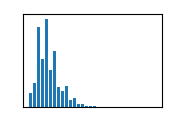

In [11]:
# Compute percentiles
p1 = np.percentile(image, 1)
p99 = np.percentile(image, 70)

# Perform percentile normalization
percentile_image_unclipped = (image - p1) / (p99 - p1)
insight(percentile_image_unclipped)

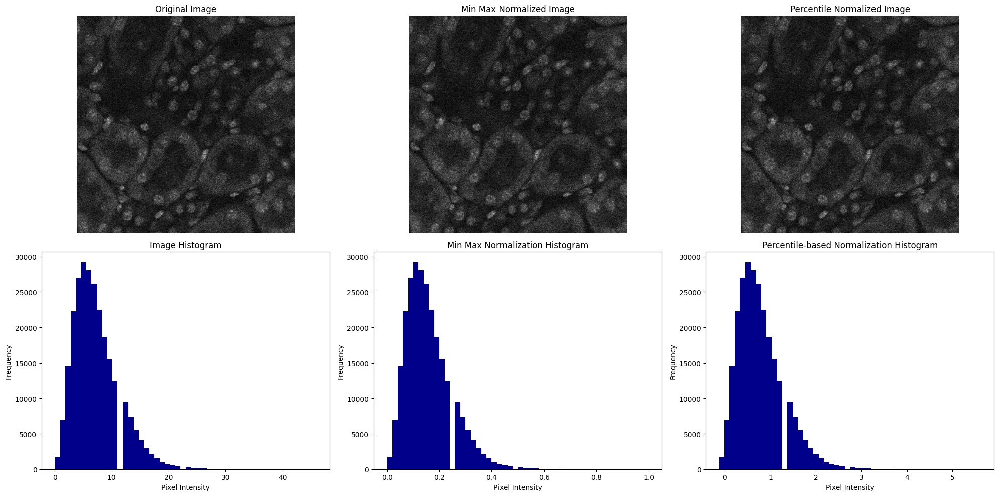

In [12]:

# Create a 2x3 subplot grid (2 rows, 3 columns)
fig, axes = plt.subplots(2, 3, figsize=(20, 10))  

# Show the original image
axes[0, 0].imshow(image, cmap='gray')
axes[0, 0].set_title('Original Image')
axes[0, 0].axis('off')  # Hide axes

# Show the min-max normalized image
axes[0, 1].imshow(min_max, cmap='gray')
axes[0, 1].set_title('Min Max Normalized Image')
axes[0, 1].axis('off')  # Hide axes

# Show the percentile-based normalized image
axes[0, 2].imshow(percentile_image_unclipped, cmap='gray')
axes[0, 2].set_title('Percentile Normalized Image')
axes[0, 2].axis('off')  # Hide axes

# Original image histogram
axes[1, 0].hist(image.ravel(), bins=50, color='darkblue')
axes[1, 0].set_title('Image Histogram')
axes[1, 0].set_xlabel('Pixel Intensity')
axes[1, 0].set_ylabel('Frequency')

# Min-max normalized image histogram
axes[1, 1].hist(min_max.ravel(), bins=50, color='darkblue')
axes[1, 1].set_title('Min Max Normalization Histogram')
axes[1, 1].set_xlabel('Pixel Intensity')
axes[1, 1].set_ylabel('Frequency')

# Percentile-based normalized image histogram
axes[1, 2].hist(percentile_image_unclipped.ravel(), bins=50, color='darkblue')
axes[1, 2].set_title('Percentile-based Normalization Histogram')
axes[1, 2].set_xlabel('Pixel Intensity')
axes[1, 2].set_ylabel('Frequency')

# Adjust layout for better spacing
plt.tight_layout()
plt.show()

### FILTRO GAUSSIANO, LAPLACIANO ECC

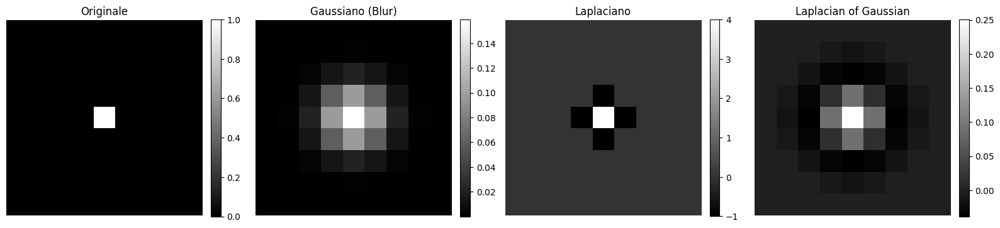

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import filters

# Funzione Laplacian of Gaussian
def laplacian_of_gaussian(image, sigma):
    blurred = filters.gaussian(image, sigma)
    return filters.laplace(blurred)

# Creazione immagini di test
image1 = np.zeros((9, 9))
image1[4, 4] = 1  # impulso

sigma = 1

# Trasformazioni
gaussian_img = filters.gaussian(image1, sigma=sigma)
laplace_img = filters.laplace(image1)
log_img = laplacian_of_gaussian(image1, sigma=sigma)

# Plot unico
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

titles = [
    "Originale",
    "Gaussiano (Blur)",
    "Laplaciano",
    "Laplacian of Gaussian"
]

images = [
    image1,
    gaussian_img,
    laplace_img,
    log_img
]

for ax, img, title in zip(axes, images, titles):
    im = ax.imshow(img, cmap='gray')
    ax.set_title(title)
    ax.axis('off')
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

In [14]:
blurred = filters.gaussian(image, sigma=0.5)
blurred

array([[1.54412969e-04, 2.83343001e-04, 2.00819610e-04, ...,
        2.17687626e-04, 1.56568144e-04, 2.80607103e-04],
       [2.34238580e-04, 1.89854656e-04, 2.21898415e-04, ...,
        2.82669426e-04, 2.11295163e-04, 2.67760185e-04],
       [3.04469908e-04, 2.07535492e-04, 1.19425989e-04, ...,
        3.68708434e-04, 3.48582674e-04, 4.33831939e-04],
       ...,
       [1.30188632e-04, 1.27895233e-04, 1.05168797e-04, ...,
        3.40852763e-04, 4.05689396e-04, 2.97315102e-04],
       [5.80877652e-05, 1.26108387e-04, 1.93871884e-04, ...,
        3.43925677e-04, 2.96139334e-04, 2.61154732e-04],
       [8.90197093e-05, 1.16612378e-04, 1.11188744e-04, ...,
        2.56148624e-04, 2.56871956e-04, 3.17568925e-04]])

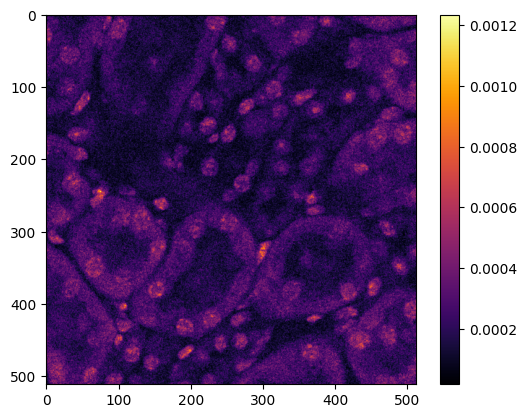

In [15]:
plt.imshow(blurred, cmap='inferno')
plt.colorbar()

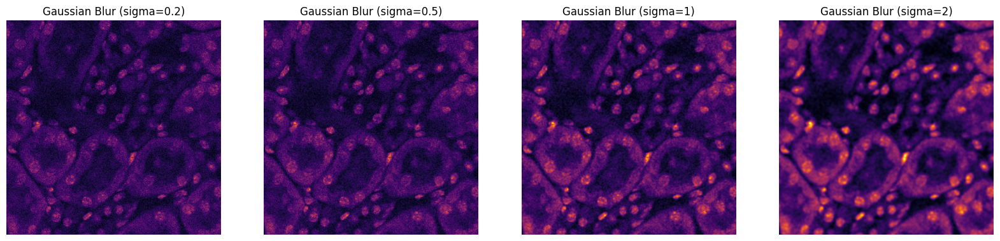

In [16]:
#ora stampiamo due immagini, con il filtro gaussiano con sigma 0.2,0.5,1,2:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))  # 1 row, 4 columns
sigmas = [0.2, 0.5, 1, 2]
for ax, sigma in zip(axes, sigmas):
    blurred = filters.gaussian(image, sigma=sigma)
    ax.imshow(blurred, cmap='inferno')
    ax.set_title(f'Gaussian Blur (sigma={sigma})')
    ax.axis('off')  # Hide axes

#il filtro gaussiano serve a ridurre il rumore nell'immagine, ma può anche sfocare i dettagli. Sperimentare con diversi valori di sigma permette di trovare un equilibrio tra la riduzione del rumore e la conservazione dei dettagli.

#FILTRO GAUSSIANO PIU SU CANALI 2 E 3?

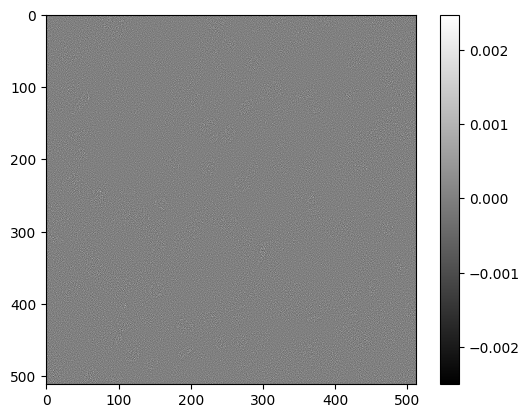

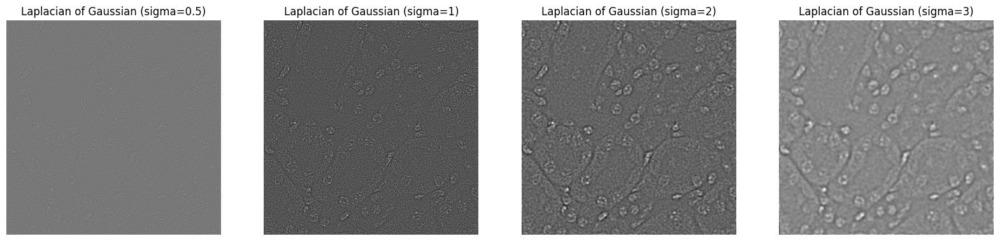

In [17]:
bordo= filters.laplace(image)
#serve a evidenziare i bordi e i dettagli dell'immagine, ma può anche amplificare il rumore. È utile per identificare strutture sottili, ma è importante bilanciare l'effetto con la riduzione del rumore.  

plt.imshow(bordo, cmap='gray')
plt.colorbar()

#facciamo variare il filtro laplaciano con diversi sigma, e vediamo come cambia l'effetto sui bordi:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
sigmas = [0.5, 1, 2, 3]
for ax, sigma in zip(axes, sigmas):
    blurred = filters.gaussian(image, sigma=sigma)
    laplacian = filters.laplace(blurred)
    ax.imshow(laplacian, cmap='gray')
    ax.set_title(f'Laplacian of Gaussian (sigma={sigma})')
    ax.axis('off')  # Hide axes

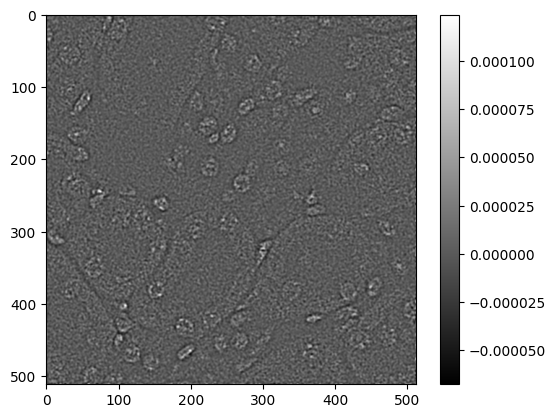

In [18]:
# ────────────────────────────────────────────────────────────────────────────
#LAPLACIAN OF GAUSSIAN (LoG) è un filtro che combina la sfocatura gaussiana con l'operatore laplaciano. La sfocatura gaussiana aiuta a ridurre il rumore, mentre il laplaciano evidenzia i bordi. Variando il parametro sigma del filtro gaussiano, è possibile controllare il livello di sfocatura e quindi l'effetto sui bordi: valori più bassi di sigma evidenzieranno dettagli più sottili, mentre valori più alti produrranno un effetto più morbido, evidenziando solo i bordi più marcati.

log_image = laplacian_of_gaussian(image, sigma=1.5)

plt.imshow(log_image, cmap='gray')
plt.colorbar()

#il problema è che diminuendo sigma il filtro gaussiano riduce meno il rumore, quindi il filtro laplaciano evidenzia più dettagli ma anche più rumore, mentre aumentando sigma si ottiene un'immagine più pulita ma con meno dettagli evidenziati. È importante trovare un equilibrio tra la riduzione del rumore e la conservazione dei dettagli per ottenere risultati ottimali.

#FORSE DIMINUENDO IL RUMORE "A MONTE" QUESTI FILTRI POTREBBERO FUNZIONARE MEGLIO?

### filtri

(50, 512, 512)


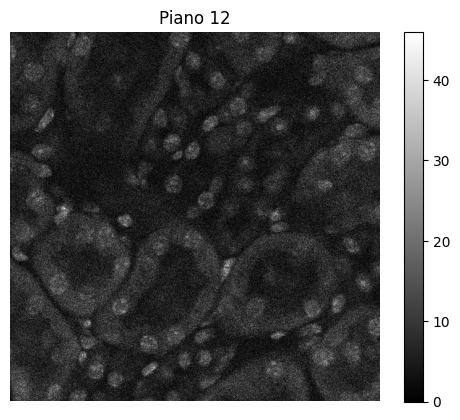

In [19]:
import numpy as np

import matplotlib.pyplot as plt
from skimage.io import imread
from skimage import data
from skimage import filters
from skimage import morphology
from scipy.ndimage import convolve, gaussian_laplace
import stackview

image3 = imread('/Users/francesco/Repositories /CNR_SNR_3channels/zstack_150mic_50piani_10ripetizioni_50mW_512px_770nm_Ch1.tif').astype(float)

# Controllo dimensioni
print(image3.shape)

# Estrai il piano 12 (indice 11)
plane_12 = image3[11]

# Plot
plt.imshow(plane_12, cmap='gray')
plt.title("Piano 12")
plt.colorbar()
plt.axis('off')
plt.show()

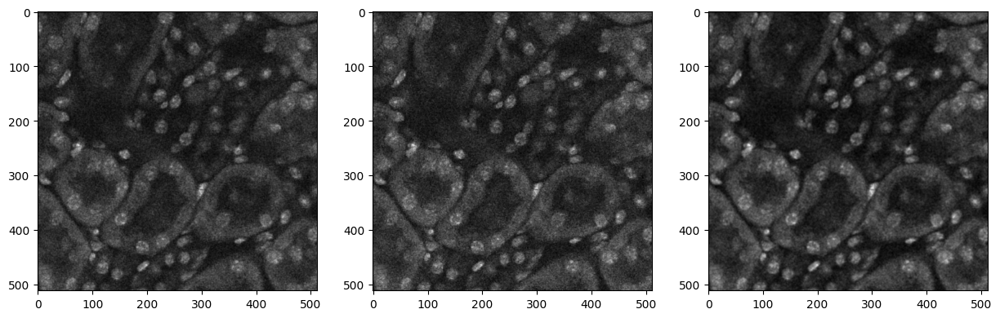

In [20]:
#filtri mean, median e gaussian su questo piano 12:
denoised_mean = filters.rank.mean(plane_12.astype(np.uint8), morphology.disk(1))
denoised_median = filters.median(plane_12, morphology.disk(1))
denoised_gaussian = filters.gaussian(plane_12, sigma=1)

fig, axes = plt.subplots(1,3, figsize=(15,15))

axes[0].imshow(denoised_mean, cmap='gray')
axes[1].imshow(denoised_median, cmap='gray')
axes[2].imshow(denoised_gaussian, cmap='gray')

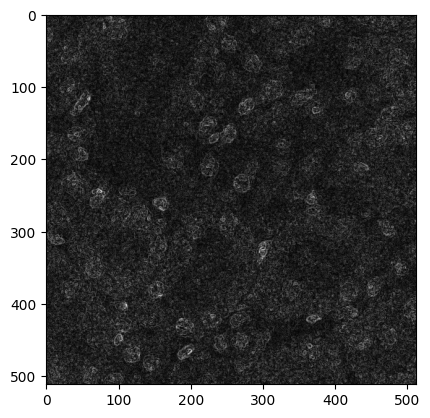

In [21]:
#questo SOBEL è un filtro che evidenzia i bordi, e potrebbe essere più efficace dopo aver ridotto il rumore con i filtri precedenti. Applicare il filtro sobel su un'immagine denoised può aiutare a evidenziare meglio i dettagli e i bordi, poiché il rumore è stato ridotto, permettendo al filtro di concentrarsi sui veri contorni dell'immagine.
sobel = filters.sobel(plane_12)

plt.imshow(sobel, cmap='gray')

### CONV0LUZIONE

Convolutionals kernel

Originale:
 [[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 1. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 2. 0. 0.]
 [0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]]

Convoluzione (kernel somma vicini):
 [[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 1. 0. 0. 0. 0. 0. 0. 0.]
 [0. 1. 1. 1. 0. 0. 0. 0. 0. 0.]
 [0. 0. 1. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 2. 0. 0.]
 [0. 0. 0. 0. 0. 0. 3. 2. 2. 0.]
 [0. 0. 0. 0. 0. 1. 1. 3. 0. 0.]
 [0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]]

Media pesata:
 [[0.  0.  0.  0.  0.  0.  0.  0.  0.  0. ]
 [0.  0.  0.2 0.  0.  0.  0.  0.  0.  0. ]
 [0.  0.2 0.2 0.2 0.  0.  0.  0.  0.  0. ]
 [0.  0.  0.2 0.  0.  0.  0.  0.  0.  0. ]
 [0.  0.  0.  0.  0.  0.  0.  0.4 0.  0. ]
 [0.  0.  0.  0.  0.  0.  0.6 0.4 0.4 0. ]
 [0.  0.  0.  0.  0.  0.2 0.2 0.6 0.  0. ]
 [0.  0.  0.  0.  0.  0.  0.2 0.  0. 

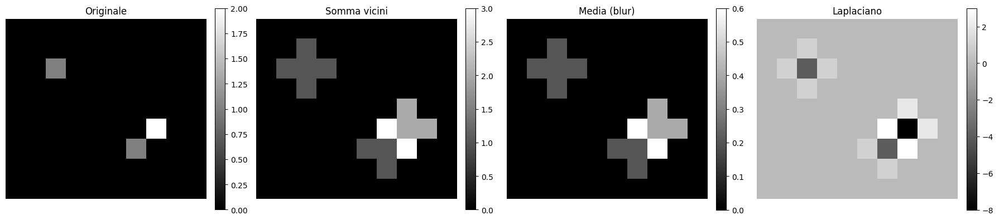

In [22]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import convolve

# Immagine di partenza
image = np.asarray([
  [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
  [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
  [0, 0, 1, 0, 0, 0, 0, 0, 0, 0],
  [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
  [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
  [0, 0, 0, 0, 0, 0, 0, 2, 0, 0],
  [0, 0, 0, 0, 0, 0, 1, 0, 0, 0],
  [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
  [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
]).astype(float)

# Kernel
kernel = np.array([
  [0, 1, 0],
  [1, 1, 1],
  [0, 1, 0],
])

mean_kernel = np.array([
  [0, 0.2, 0],
  [0.2, 0.2, 0.2],
  [0, 0.2, 0],
])

laplace_operator = np.array([
  [0, 1, 0],
  [1, -4, 1],
  [0, 1, 0],
])

# Convoluzioni
convolved = convolve(image, kernel) #questo kernel somma i vicini, quindi evidenzia le aree con più pixel accesi
mean_convolved = convolve(image, mean_kernel) #questo kernel fa una media pesata dei vicini, quindi riduce il rumore ma può anche sfocare i dettagli
laplacian = convolve(image, laplace_operator) #questo kernel evidenzia i bordi, ma può anche amplificare il rumore. È utile per identificare strutture sottili, ma è importante bilanciare l'effetto con la riduzione del rumore.

#L'OPERAZIONE DI CONVOLUZIONE APPLICA IL KERNEL ALL'IMMAGINE, CALCOLANDO UNA SOMMA PONDERATA DEI PIXEL VICINI PER OGNI POSIZIONE DELL'IMMAGINE. QUESTO PERMETTE DI EVIDENZIARE DIVERSI ASPETTI DELL'IMMAGINE, COME I BORDI O LE AREE CONCENTRATE DI PIXEL ACCESI, A SECONDA DEL KERNEL UTILIZZATO.
#bisogna pensare alla convoluzione come a un processo di "scorrimento" del kernel sull'immagine, dove per ogni posizione del kernel si calcola una somma ponderata dei pixel sovrapposti. Il risultato è una nuova immagine che evidenzia caratteristiche specifiche in base al kernel scelto.

# --- STAMPA ARRAY ---
print("Originale:\n", image)
print("\nConvoluzione (kernel somma vicini):\n", convolved)
print("\nMedia pesata:\n", mean_convolved)
print("\nLaplaciano:\n", laplacian)

# --- PLOT EVOLUZIONE ---
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

titles = [
    "Originale",
    "Somma vicini",
    "Media (blur)",
    "Laplaciano"
]

images = [
    image,
    convolved,
    mean_convolved,
    laplacian 
]

for ax, img, title in zip(axes, images, titles):
    im = ax.imshow(img, cmap='gray')
    ax.set_title(title)
    ax.axis('off')
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

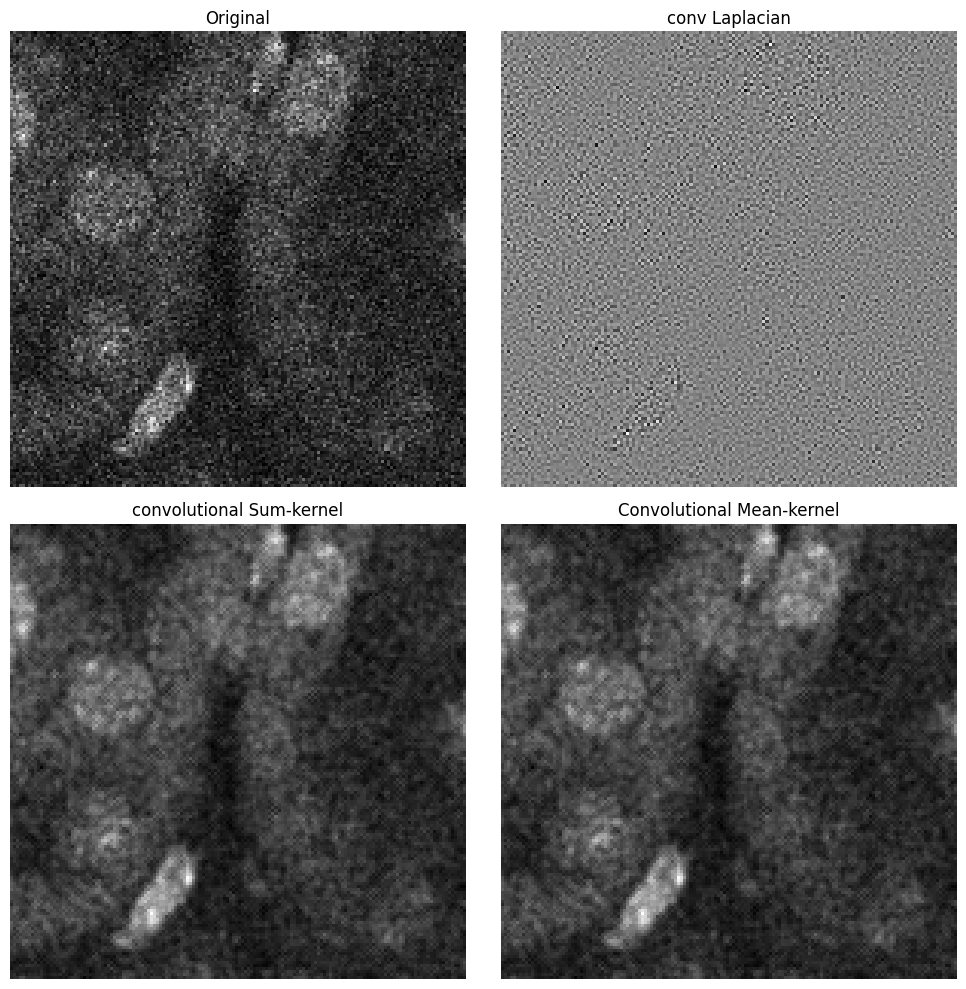

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import convolve
from skimage.io import imread

# Leggi stack e prendi piano 12 (indice 11)
image3 = imread('/Users/francesco/Repositories /CNR_SNR_3channels/zstack_150mic_50piani_10ripetizioni_50mW_512px_770nm_Ch1.tif')[11].astype(float)
# ! MODO DI SELEZIONARE AGEVOLMENTE IL PIANO 12: image3[11] (ricorda che l'indice parte da 0)

# Zoom 2D (IMPORTANTE: due dimensioni!)
plane_zoom = image3[100:150, 150:200]
#aumentiamo le dimensioni dello zoom per vedere meglio l'effetto dei filtri
plane_zoom = image3[0:150, 0:150]

# Convoluzioni
convolved_image = convolve(plane_zoom, kernel)
mean_image = convolve(plane_zoom, mean_kernel)
laplacian_image = convolve(plane_zoom, laplace_operator)

# Plot
fig, axes = plt.subplots(2, 2, figsize=(10,10))

axes[0,0].imshow(plane_zoom, cmap='gray')
axes[0,0].set_title("Original")

axes[0,1].imshow(laplacian_image, cmap='gray')
axes[0,1].set_title("conv Laplacian")

axes[1,0].imshow(convolved_image, cmap='gray')
axes[1,0].set_title("convolutional Sum-kernel")

axes[1,1].imshow(mean_image, cmap='gray')
axes[1,1].set_title("Convolutional Mean-kernel")

for ax in axes.ravel():
    ax.axis('off')

plt.tight_layout()
plt.show()

# * IL MIGLIORE SEMBRA ESSERE IL MEAN-KERNEL: i pixel accesi sono più evidenti, e il rumore è ridotto, mentre con il laplaciano si evidenziano i bordi ma anche il rumore, e con la somma dei vicini si evidenziano le aree con più pixel accesi ma anche il rumore. Il mean-kernel sembra bilanciare meglio la riduzione del rumore con la conservazione dei dettagli migliorando, nel dettaglio, l'originale. Anche SUM-KERNEL è buona.

### NOISE REMOVAL FILTRES

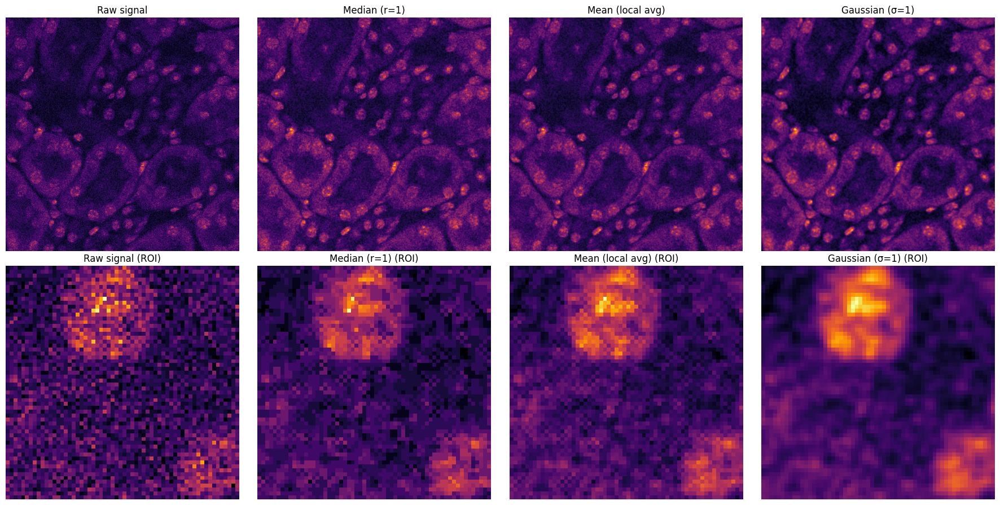

In [24]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.io import imread
from skimage import filters
from skimage.morphology import disk
from skimage.util import img_as_ubyte

# -------------------------
# LOAD IMAGE (single z-plane)
# -------------------------
image3 = imread('/Users/francesco/Repositories /CNR_SNR_3channels/zstack_150mic_50piani_10ripetizioni_50mW_512px_770nm_Ch1.tif')[11].astype(float)

# normalization
image_norm = (image3 - image3.min()) / (image3.max() - image3.min())

# -------------------------
# FILTERS (quali di questi è una convoluzione?: mean e gaussian sono convoluzioni, median no)
# -------------------------
original = image_norm

median_filtered = filters.median(image_norm, disk(1))

mean_filtered = filters.rank.mean(
    img_as_ubyte(image_norm),
    disk(1)
)

gaussian_filtered = filters.gaussian(image_norm, sigma=1)

# -------------------------
# ROI
# -------------------------
roi = (200, 260)

original_zoom = original[roi[0]:roi[1], roi[0]:roi[1]]
median_zoom = median_filtered[roi[0]:roi[1], roi[0]:roi[1]]
mean_zoom = mean_filtered[roi[0]:roi[1], roi[0]:roi[1]]
gaussian_zoom = gaussian_filtered[roi[0]:roi[1], roi[0]:roi[1]]

# -------------------------
# PLOT
# -------------------------
fig, axs = plt.subplots(2, 4, figsize=(18, 9))

titles = [
    "Raw signal",
    "Median (r=1)",
    "Mean (local avg)",
    "Gaussian (σ=1)"
]

images = [original, median_filtered, mean_filtered, gaussian_filtered]
zooms = [original_zoom, median_zoom, mean_zoom, gaussian_zoom]

# ROW 1
for i in range(4):
    axs[0, i].imshow(images[i], cmap='inferno')
    axs[0, i].set_title(titles[i])
    axs[0, i].axis('off')

# ROW 2
for i in range(4):
    axs[1, i].imshow(zooms[i], cmap='inferno')
    axs[1, i].set_title(titles[i] + " (ROI)")
    axs[1, i].axis('off')

plt.tight_layout()
plt.show()

### BACKGROUND REMOVAL FILTERS

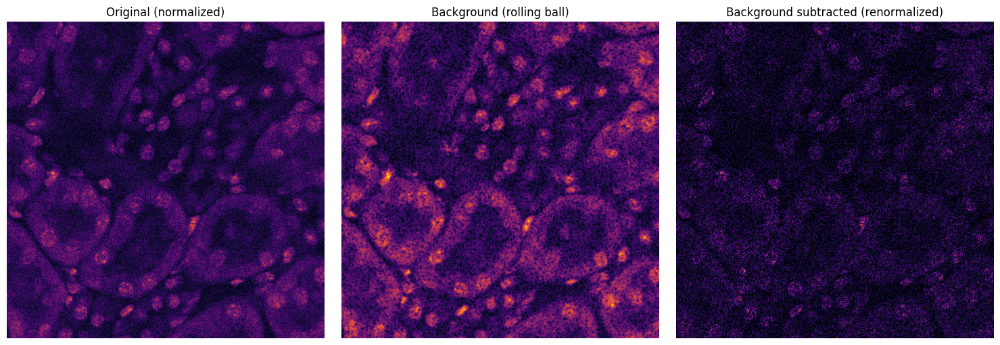

In [25]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.io import imread
from skimage.restoration import rolling_ball

# -------------------------
# LOAD IMAGE
# -------------------------
image = imread(
    '/Users/francesco/Repositories /CNR_SNR_3channels/zstack_150mic_50piani_10ripetizioni_50mW_512px_770nm_Ch1.tif'
)[11].astype(float)

# -------------------------
# NORMALIZATION INPUT
# -------------------------
image_norm = (image - image.min()) / (image.max() - image.min())

# -------------------------
# BACKGROUND
# -------------------------
background_rolling = rolling_ball(image_norm, radius=25)

# -------------------------
# SUBTRACTION
# -------------------------
image_subtracted = image_norm - background_rolling

# 🔑 FIX IMPORTANTE:
# shift per evitare perdita di segnale
image_subtracted = image_subtracted - image_subtracted.min()

# normalizzazione finale 0–1
image_subtracted = image_subtracted / image_subtracted.max()

# -------------------------
# PLOT
# -------------------------
fig, axs = plt.subplots(1, 3, figsize=(15, 5))

axs[0].imshow(image_norm, cmap='inferno')
axs[0].set_title("Original (normalized)")
axs[0].axis('off')

axs[1].imshow(background_rolling, cmap='inferno')
axs[1].set_title("Background (rolling ball)")
axs[1].axis('off')

axs[2].imshow(image_subtracted, cmap='inferno')
axs[2].set_title("Background subtracted (renormalized)")
axs[2].axis('off')

plt.tight_layout()
plt.show()

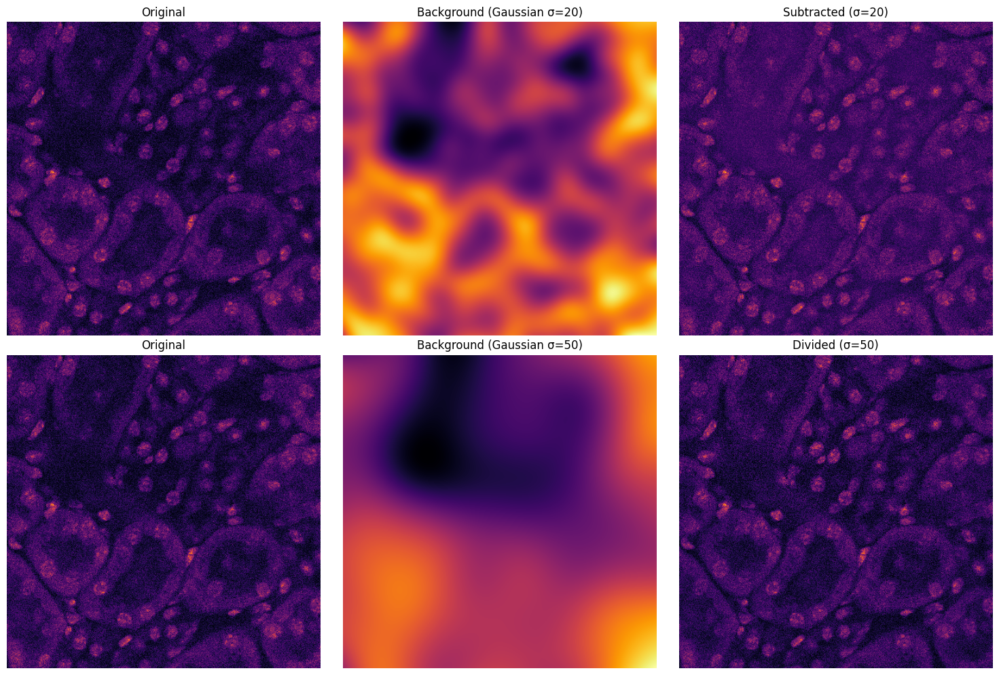

In [26]:
from skimage.filters import gaussian
import matplotlib.pyplot as plt

# -------------------------
# GAUSSIAN BACKGROUND (sigma=20)
# -------------------------
background_gaussian_20 = gaussian(
    image_norm,
    sigma=20,
    preserve_range=True
)

image_gaussian_subtracted = image_norm - background_gaussian_20
image_gaussian_subtracted = image_gaussian_subtracted - image_gaussian_subtracted.min()
image_gaussian_subtracted = image_gaussian_subtracted / image_gaussian_subtracted.max()

# -------------------------
# GAUSSIAN BACKGROUND (sigma=50)
# -------------------------
background_gaussian_50 = gaussian(
    image_norm,
    sigma=50,
    preserve_range=True
)

# attenzione a divisione stabile
image_gaussian_divided = image_norm / (background_gaussian_50 + 1e-8)
image_gaussian_divided = image_gaussian_divided - image_gaussian_divided.min()
image_gaussian_divided = image_gaussian_divided / image_gaussian_divided.max()

# -------------------------
# PLOT 2x3
# -------------------------
fig, axs = plt.subplots(2, 3, figsize=(15, 10))

# --- ROW 1: subtraction (sigma 20)
axs[0, 0].imshow(image_norm, cmap='inferno')
axs[0, 0].set_title("Original")
axs[0, 0].axis('off')

axs[0, 1].imshow(background_gaussian_20, cmap='inferno')
axs[0, 1].set_title("Background (Gaussian σ=20)")
axs[0, 1].axis('off')

axs[0, 2].imshow(image_gaussian_subtracted, cmap='inferno')
axs[0, 2].set_title("Subtracted (σ=20)")
axs[0, 2].axis('off')

# --- ROW 2: division (sigma 50)
axs[1, 0].imshow(image_norm, cmap='inferno')
axs[1, 0].set_title("Original")
axs[1, 0].axis('off')

axs[1, 1].imshow(background_gaussian_50, cmap='inferno')
axs[1, 1].set_title("Background (Gaussian σ=50)")
axs[1, 1].axis('off')

axs[1, 2].imshow(image_gaussian_divided, cmap='inferno')
axs[1, 2].set_title("Divided (σ=50)")
axs[1, 2].axis('off')

plt.tight_layout()
plt.show()

  PRESERVAZIONE DEL SEGNALE (Sobel correlation)
  White Top-Hat  (radius=40): 0.9848  ← migliore?
  Gauss sub (σ=20):         0.7989
  Rolling ball (r=40):   0.7864
  Valori vicini a 1.0 = segnale preservato


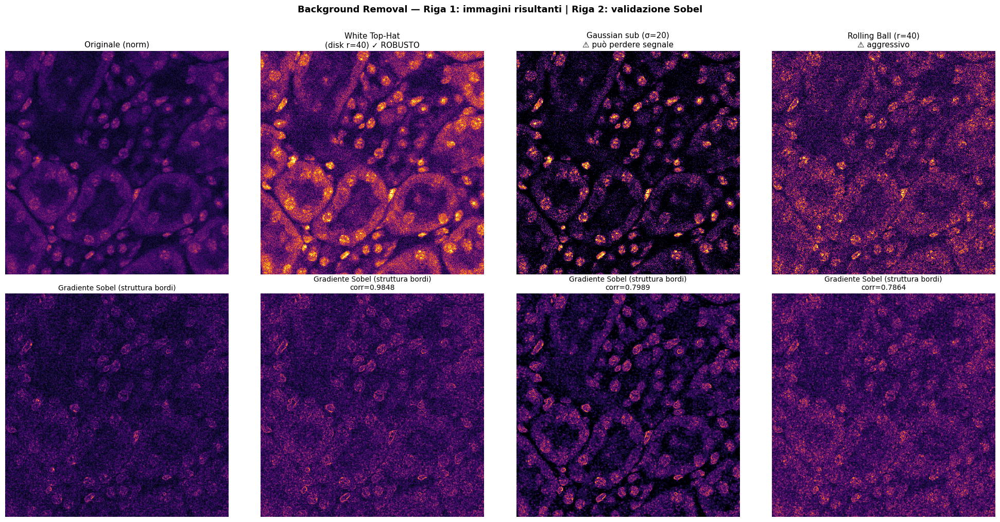

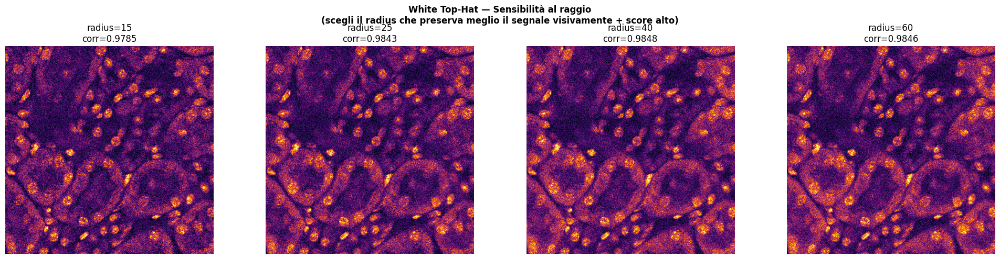


image_bg_removed: shape=(512, 512), dtype=float64, range=[0.000, 1.000]


In [27]:
# ============================================================
# CELLA ROBUSTA: RIMOZIONE BACKGROUND SENZA PERDITA DI SEGNALE
# ============================================================
#
# Problema delle celle precedenti:
#   - Gaussian subtraction (σ=20): sigma troppo piccolo → rimuove anche segnale reale
#   - Rolling ball (r=25): troppo aggressivo → "affonda" nelle strutture brillanti
#   - Post-shift + renorm: maschera la perdita di segnale senza risolverla
#
# Soluzione: WHITE TOP-HAT TRANSFORM (morfologico)
#   formula: tophat(I) = I - opening(I, structuring_element)
#   - opening(I) ≤ I sempre → risultato sempre ≥ 0 (nessun clipping, nessun shift!)
#   - Il disco morfologico filtra strutture più piccole del raggio → preserva segnale
#   - Il background lento/ampio viene rimosso; le strutture brillanti restano intatte
#
# Validazione: Sobel gradient magnitude prima/dopo → se il segnale è preservato,
# la struttura dei bordi (gradiente) deve essere mantenuta o migliorata.
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from skimage.io import imread
from skimage.morphology import white_tophat, disk
from skimage.filters import sobel, gaussian
from skimage.restoration import rolling_ball
from skimage.exposure import rescale_intensity

# ── 1. CARICAMENTO (usa image_norm già definita dalle celle precedenti) ──────
# Se stai rieseguendo la cella standalone, decommentare le 2 righe sotto:
# image3 = imread('/Users/francesco/Repositories /CNR_SNR_3channels/zstack_150mic_50piani_10ripetizioni_50mW_512px_770nm_Ch1.tif')[11].astype(float)
# image_norm = (image3 - image3.min()) / (image3.max() - image3.min())

assert image_norm is not None, "Esegui prima la cella di caricamento e normalizzazione"

# ── 2. WHITE TOP-HAT – il parametro chiave è il raggio del disco ─────────────
#   Scegli radius ≈ dimensione minima delle strutture di background che vuoi rimuovere
#   (es. granularità del background scuro) ma MAGGIORE della dimensione dei tuoi segnali.
#   Partenza sicura: radius = 30-50 per immagini 512px di microscopio.
RADIUS = 40   # <── MODIFICA QUI se le strutture del segnale sono più grandi

background_tophat = image_norm - white_tophat(image_norm, disk(RADIUS))
image_tophat = white_tophat(image_norm, disk(RADIUS))

# Normalizzazione PERCENTILE-BASED (robusta agli outlier, non min-max cieco)
p_low  = np.percentile(image_tophat[image_tophat > 0], 1)
p_high = np.percentile(image_tophat, 99.5)
image_tophat_norm = rescale_intensity(image_tophat, in_range=(p_low, p_high))

# ── 3. CONFRONTO con metodi precedenti (per validazione visiva) ──────────────
background_gaussian = gaussian(image_norm, sigma=20, preserve_range=True)
image_gauss_sub     = image_norm - background_gaussian
image_gauss_sub     = np.clip(image_gauss_sub, 0, None)           # clip senza shift
image_gauss_sub     = rescale_intensity(image_gauss_sub, in_range=(
    np.percentile(image_gauss_sub[image_gauss_sub > 0], 1),
    np.percentile(image_gauss_sub, 99.5)
))

background_rb = rolling_ball(image_norm, radius=RADIUS)
image_rb_sub  = np.clip(image_norm - background_rb, 0, None)
image_rb_sub  = rescale_intensity(image_rb_sub, in_range=(
    np.percentile(image_rb_sub[image_rb_sub > 0], 1),
    np.percentile(image_rb_sub, 99.5)
))

# ── 4. VALIDAZIONE CON SOBEL – misura preservazione della struttura ──────────
sobel_original = sobel(image_norm)
sobel_tophat   = sobel(image_tophat_norm)
sobel_gauss    = sobel(image_gauss_sub)
sobel_rb       = sobel(image_rb_sub)

def signal_preservation_score(sob_before, sob_after):
    """
    Correlazione di Pearson tra gradiente originale e post-processing.
    score=1.0 → struttura identica; score<1 → segnale perso.
    """
    b = sob_before.ravel()
    a = sob_after.ravel()
    return float(np.corrcoef(b, a)[0, 1])

score_tophat = signal_preservation_score(sobel_original, sobel_tophat)
score_gauss  = signal_preservation_score(sobel_original, sobel_gauss)
score_rb     = signal_preservation_score(sobel_original, sobel_rb)

print("=" * 52)
print("  PRESERVAZIONE DEL SEGNALE (Sobel correlation)")
print("=" * 52)
print(f"  White Top-Hat  (radius={RADIUS}): {score_tophat:.4f}  ← migliore?")
print(f"  Gauss sub (σ=20):         {score_gauss:.4f}")
print(f"  Rolling ball (r={RADIUS}):   {score_rb:.4f}")
print("=" * 52)
print("  Valori vicini a 1.0 = segnale preservato")

# ── 5. PLOT COMPARATIVO ───────────────────────────────────────────────────────
fig, axs = plt.subplots(2, 4, figsize=(20, 10))

titles_top = [
    "Originale (norm)",
    f"White Top-Hat\n(disk r={RADIUS}) ✓ ROBUSTO",
    "Gaussian sub (σ=20)\n⚠ può perdere segnale",
    f"Rolling Ball (r={RADIUS})\n⚠ aggressivo"
]
images_top = [image_norm, image_tophat_norm, image_gauss_sub, image_rb_sub]
images_bot = [sobel_original, sobel_tophat, sobel_gauss, sobel_rb]
scores     = [None, score_tophat, score_gauss, score_rb]

for i in range(4):
    axs[0, i].imshow(images_top[i], cmap='inferno')
    axs[0, i].set_title(titles_top[i], fontsize=11)
    axs[0, i].axis('off')

    axs[1, i].imshow(images_bot[i], cmap='inferno')
    label = "Gradiente Sobel (struttura bordi)"
    if scores[i] is not None:
        label += f"\ncorr={scores[i]:.4f}"
    axs[1, i].set_title(label, fontsize=10)
    axs[1, i].axis('off')

plt.suptitle(
    "Background Removal — Riga 1: immagini risultanti | Riga 2: validazione Sobel",
    fontsize=13, fontweight='bold', y=1.01
)
plt.tight_layout()
plt.show()

# ── 6. SENSIBILITÀ AL RAGGIO (opzionale) ─────────────────────────────────────
radii = [15, 25, 40, 60]
fig2, axs2 = plt.subplots(1, len(radii), figsize=(20, 5))

for ax, r in zip(axs2, radii):
    th = white_tophat(image_norm, disk(r))
    th = rescale_intensity(th, in_range=(
        np.percentile(th[th > 0], 1) if th.max() > 0 else 0,
        np.percentile(th, 99.5)
    ))
    sc = signal_preservation_score(sobel_original, sobel(th))
    ax.imshow(th, cmap='inferno')
    ax.set_title(f"radius={r}\ncorr={sc:.4f}")
    ax.axis('off')

plt.suptitle(
    "White Top-Hat — Sensibilità al raggio\n(scegli il radius che preserva meglio il segnale visivamente + score alto)",
    fontsize=12, fontweight='bold'
)
plt.tight_layout()
plt.show()

# ─────────────────────────────────────────────────────────────────────────────
# RISULTATO FINALE PULITO (pronto per le analisi successive)
image_bg_removed = image_tophat_norm   # ← usa questa nelle celle successive
print(f"\nimage_bg_removed: shape={image_bg_removed.shape}, "
      f"dtype={image_bg_removed.dtype}, "
      f"range=[{image_bg_removed.min():.3f}, {image_bg_removed.max():.3f}]")


acquisizione grezza
      ↓
  [1] DENOISING          ← prima di tutto, perché il rumore amplifica
      ↓                     gli artefatti in tutti i passi successivi
  [2] BACKGROUND REMOVAL ← dopo il denoising, così non scambia rumore
      ↓                     per background (problema che abbiamo appena risolto)
  [3] DECONVOLUZIONE     ← ultima, perché è la più sensibile al rumore
      ↓                     e lavora meglio su un'immagine già pulita
  analisi / segmentazione


Il motivo della sequenza è la propagazione degli errori: la deconvoluzione Richardson-Lucy amplifica il rumore ad ogni iterazione — se lo lasci dentro, diverge verso artefatti. Il background removal fatto prima del denoising invece rischia di confondere il noise floor con il background (il problema della v1 di ieri). Quindi l'ordine non è arbitrario, è dettato da cosa ogni operazione presuppone sull'input.
Nel tuo caso, lavorando su dati reali di microscopio senza ground truth, la deconvoluzione è opzionale e rischiosa — il background removal ben fatto spesso è già sufficiente per migliorare il SNR in modo affidabile.

### Edge Detection

/Users/francesco/Library/Python/3.9/lib/python/site-packages/pyclesperanto_prototype/_tier9/_imshow.py:35: UserWarning: cle.imshow is deprecated, use stackview.imshow instead.
  warnings.warn("cle.imshow is deprecated, use stackview.imshow instead.")


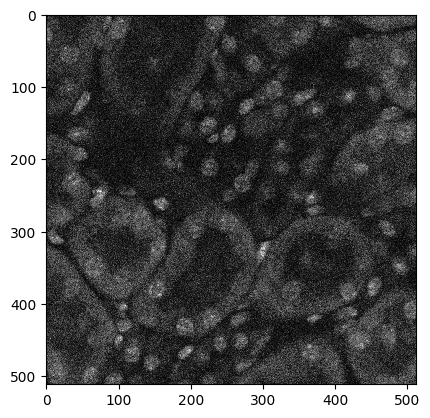

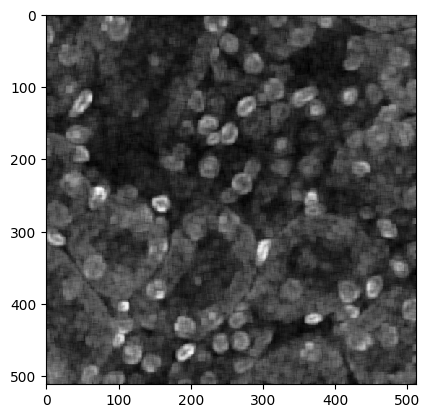

In [28]:
import pyclesperanto_prototype as cle
from skimage.io import imread
import matplotlib.pyplot as plt
imagine3 = imread('/Users/francesco/Repositories /CNR_SNR_3channels/zstack_150mic_50piani_10ripetizioni_50mW_512px_770nm_Ch1.tif')[11].astype(float)
cle.imshow(imagine3)

blobs_edges = cle.standard_deviation_box(imagine3, radius_x=4, radius_y=4) #questo filtro evidenzia le strutture più brillanti, e potrebbe essere utile per identificare i blob (strutture puntiformi) nell'immagine. Il parametro radius_x e radius_y controlla la dimensione delle strutture che vengono evidenziate: valori più grandi evidenzieranno strutture più grandi, mentre valori più piccoli evidenzieranno dettagli più fini. Sperimentare con questi parametri può aiutare a identificare meglio i blob presenti nell'immagine.
cle.imshow(blobs_edges)

#-------------------
### DECONVOLUTION

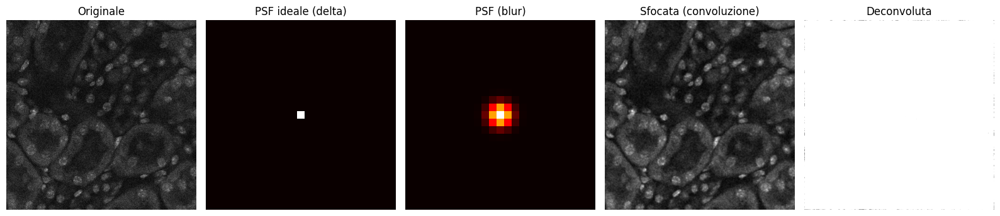

In [29]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.data import camera
from skimage.restoration import richardson_lucy
from scipy.signal import convolve2d

# 1. Immagine originale
image = imread('/Users/francesco/Repositories /CNR_SNR_3channels/zstack_150mic_50piani_10ripetizioni_50mW_512px_770nm_Ch1.tif')[11].astype(float)

# 2. PSF ideale (delta)
perfect_psf = np.zeros((25, 25))
perfect_psf[12, 12] = 1  # impulso al centro

# 3. PSF realistica (gaussiana)
def gaussian_psf(size=25, sigma=3):
    ax = np.linspace(-(size // 2), size // 2, size)
    xx, yy = np.meshgrid(ax, ax)
    psf = np.exp(-(xx**2 + yy**2) / (2 * sigma**2))
    return psf / psf.sum()

real_psf = gaussian_psf(perfect_psf.shape[0], sigma=1)

# 4. Creiamo immagine sfocata (convoluzione)
blurred = convolve2d(image, real_psf, mode='same', boundary='wrap')

# 5. Deconvoluzione
deconvolved = richardson_lucy(blurred, real_psf, num_iter=20) #non converge bene, forse perché l'immagine è molto rumorosa, o perché il PSF non è perfettamente rappresentativo del processo di sfocatura reale. La deconvoluzione di Richardson-Lucy è sensibile al rumore e alla precisione del PSF, quindi se il PSF non cattura accuratamente la sfocatura presente nell'immagine, o se l'immagine è molto rumorosa, il processo di deconvoluzione potrebbe non convergere correttamente o produrre risultati subottimali. Sperimentare con diversi PSF o applicare una riduzione del rumore prima della deconvoluzione potrebbe migliorare i risultati.

# 6. Visualizzazione
fig, axes = plt.subplots(1, 5, figsize=(16, 4))

axes[0].imshow(image, cmap='gray')
axes[0].set_title('Originale')

axes[1].imshow(perfect_psf, cmap='hot')
axes[1].set_title('PSF ideale (delta)')

axes[2].imshow(real_psf, cmap='hot')
axes[2].set_title('PSF (blur)')

axes[3].imshow(blurred, cmap='gray')
axes[3].set_title('Sfocata (convoluzione)')

axes[4].imshow(deconvolved, cmap='gray')
axes[4].set_title('Deconvoluta')

for ax in axes:
    ax.axis('off')

plt.tight_layout()
plt.show()

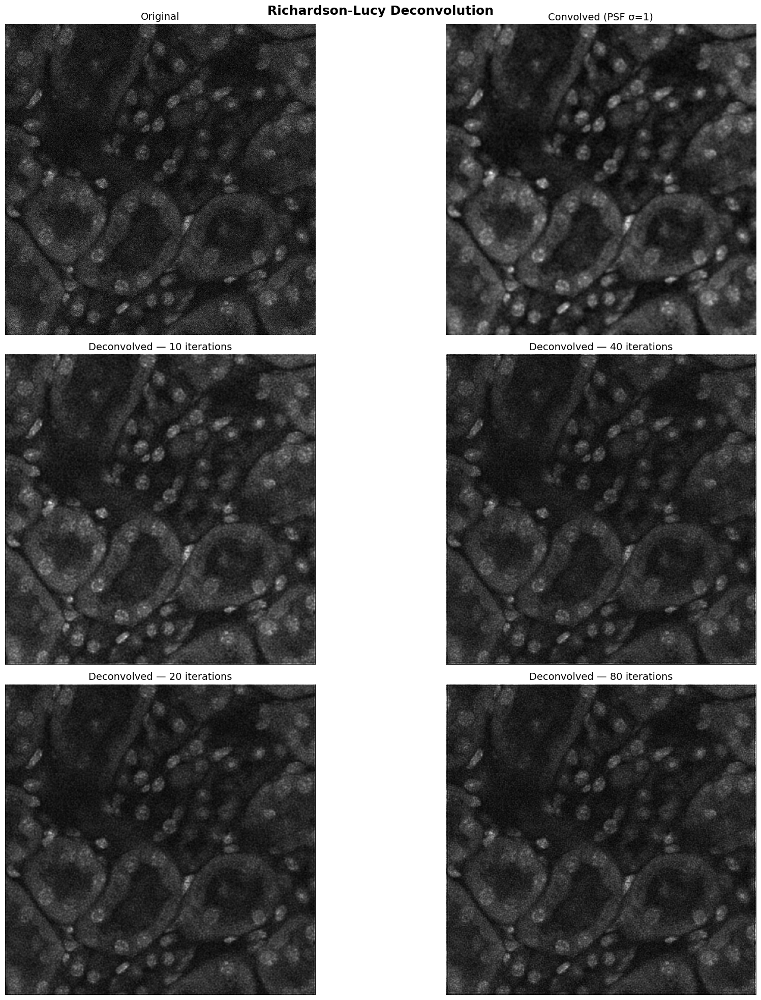

In [30]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.io import imread
from skimage.restoration import richardson_lucy
from scipy.ndimage import convolve


# ─────────────────────────────────────────────
# 1. PSF gaussiana
# ─────────────────────────────────────────────
def gaussian_psf(size: int = 25, sigma: float = 1.0) -> np.ndarray:
    """Genera una PSF gaussiana 2D normalizzata (somma = 1)."""
    ax = np.arange(size) - size // 2
    xx, yy = np.meshgrid(ax, ax)
    psf = np.exp(-(xx**2 + yy**2) / (2 * sigma**2))
    return psf / psf.sum()          # normalizzazione OBBLIGATORIA per R-L


# ─────────────────────────────────────────────
# 2. Caricamento e normalizzazione dell'immagine
# ─────────────────────────────────────────────
IMAGE_PATH = (
    "/Users/francesco/Repositories /CNR_SNR_3channels/"
    "zstack_150mic_50piani_10ripetizioni_50mW_512px_770nm_Ch1.tif"
)
SLICE_INDEX = 11

raw = imread(IMAGE_PATH)
image = raw[SLICE_INDEX].astype(float)
image /= image.max()                # normalizza in [0, 1]


# ─────────────────────────────────────────────
# 3. PSF e convoluzione
# ─────────────────────────────────────────────
real_psf = gaussian_psf(size=25, sigma=1.0)

convolved = convolve(image, real_psf)
convolved = np.clip(convolved, 0, None)   # R-L richiede valori >= 0


# ─────────────────────────────────────────────
# 4. Deconvoluzione Richardson-Lucy
#    con diverse iterazioni
# ─────────────────────────────────────────────
ITERATIONS = [10, 20, 40, 80]

deconvolved_images = {
    n: richardson_lucy(convolved, real_psf, num_iter=n)
    for n in ITERATIONS
}


# ─────────────────────────────────────────────
# 5. Plot
# ─────────────────────────────────────────────
fig, axs = plt.subplots(3, 2, figsize=(20, 20))
fig.suptitle("Richardson-Lucy Deconvolution", fontsize=18, fontweight="bold")

# riga 0: originale e convolta
axs[0, 0].imshow(image, cmap="gray")
axs[0, 0].set_title("Original", fontsize=14)
axs[0, 0].axis("off")

axs[0, 1].imshow(convolved, cmap="gray")
axs[0, 1].set_title("Convolved (PSF σ=1)", fontsize=14)
axs[0, 1].axis("off")

# righe 1-2: deconvoluzioni
for i, n_iter in enumerate(ITERATIONS):
    row = i % 2 + 1
    col = i // 2
    axs[row, col].imshow(deconvolved_images[n_iter], cmap="gray")
    axs[row, col].set_title(f"Deconvolved — {n_iter} iterations", fontsize=14)
    axs[row, col].axis("off")

plt.tight_layout()
plt.show()


──────────────────────────────────────────────────
  NA=0.8,  λ=0.77 µm,  px=0.1 µm
  FWHM laterale teorico = 4.91 px  (491 nm)
  σ gaussiana           = 2.08 px
──────────────────────────────────────────────────

Caricamento immagine...
Calcolo PSF Gaussiana...
Calcolo PSF Born & Wolf...
Calcolo PSF Gibson-Lanni (z=0)...
Calcolo PSF Gibson-Lanni (z=5µm, con aberrazione)...


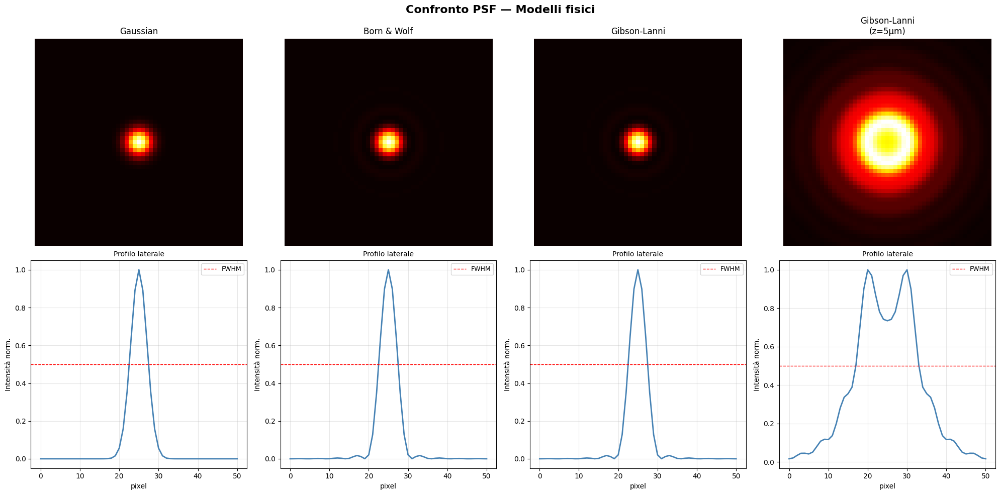

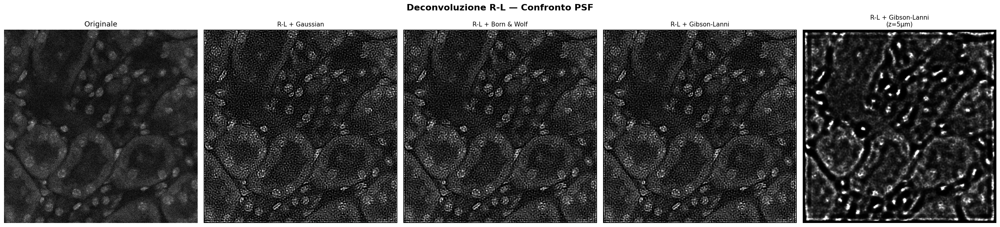

In [31]:
"""
PSF per Microscopia a Fluorescenza — Richardson-Lucy Deconvolution
==================================================================
Implementa tre livelli di PSF in ordine crescente di accuratezza:
  1. Gaussiana 2D (approssimazione rapida)
  2. Born & Wolf (modello fisico, lateral + axial)
  3. Gibson-Lanni (modello completo con aberrazioni di aberrazione sferica)

Requisiti:
    pip install numpy scipy scikit-image matplotlib tifffile
    pip install flowdec    # opzionale, per blind deconvolution
"""

import numpy as np
import matplotlib.pyplot as plt
from scipy.special import j0          # funzione di Bessel J0
from scipy.ndimage import convolve
from skimage.io import imread
from skimage.restoration import richardson_lucy, wiener


# ══════════════════════════════════════════════════════════════════════════════
# PARAMETRI DEL MICROSCOPIO — modifica questi con i tuoi valori reali
# ══════════════════════════════════════════════════════════════════════════════
MICROSCOPE = dict(
    NA           = 0.8,      # Numerical Aperture obiettivo
    wavelength   = 0.770,    # lunghezza d'onda emissione [µm]  (770 nm)
    ni           = 1.000,    # indice rifrazione immersione (aria=1.0, acqua=1.33, olio=1.515)
    ns           = 1.338,    # indice rifrazione campione (cellule ≈ 1.338)
    pixel_size   = 0.100,    # dimensione pixel al campione [µm]  (100 nm)
    dz           = 0.500,    # passo assiale z [µm]  (solo per PSF 3D)
)

# Parametri deconvoluzione
DECONV = dict(
    num_iter       = 100,
    filter_epsilon = 1e-6,   # regolarizzazione R-L (smorzamento rumore)
)

# Path immagine
IMAGE_PATH  = (
    "/Users/francesco/Repositories /CNR_SNR_3channels/"
    "zstack_150mic_50piani_10ripetizioni_50mW_512px_770nm_Ch1.tif"
)
SLICE_INDEX = 11


# ══════════════════════════════════════════════════════════════════════════════
# LIVELLO 1 — PSF gaussiana 2D (baseline, veloce)
# ══════════════════════════════════════════════════════════════════════════════
def psf_gaussian(NA, wavelength, pixel_size, size=None) -> np.ndarray:
    """
    Approssimazione gaussiana della PSF laterale.
    FWHM = 0.51 * λ / NA  (criterio di Rayleigh)
    sigma = FWHM / 2.355
    """
    fwhm_um  = 0.51 * wavelength / NA
    sigma_px = (fwhm_um / pixel_size) / 2.355

    if size is None:
        size = int(np.ceil(6 * sigma_px)) | 1   # sempre dispari, almeno 6σ

    ax = np.arange(size) - size // 2
    xx, yy = np.meshgrid(ax, ax)
    psf = np.exp(-(xx**2 + yy**2) / (2 * sigma_px**2))
    return psf / psf.sum()


# ══════════════════════════════════════════════════════════════════════════════
# LIVELLO 2 — PSF Born & Wolf (modello fisico laterale, integrale di Bessel)
# ══════════════════════════════════════════════════════════════════════════════
def psf_born_wolf(NA, wavelength, ni, pixel_size, size=51, n_samples=512) -> np.ndarray:
    """
    PSF laterale 2D basata sul modello di Born & Wolf.
    Più accurata della gaussiana: include i lobi secondari di diffrazione.

    I(r) = |2 ∫₀¹ J₀(k·NA·r·ρ/ni) · exp(-...) · ρ dρ|²

    Per la PSF in-focus (z=0) il termine di fase si annulla
    e l'integrale diventa quello della funzione di Airy.
    """
    k  = 2 * np.pi * ni / wavelength   # numero d'onda nel mezzo
    ax = (np.arange(size) - size // 2) * pixel_size   # coordinate in µm

    rho_samples = np.linspace(0, 1, n_samples)         # variabile di integrazione [0,1]

    psf = np.zeros((size, size))
    for i, x in enumerate(ax):
        for j, y in enumerate(ax):
            r = np.sqrt(x**2 + y**2)
            # Integrale di Bessel (regola dei trapezi)
            integrand = j0(k * NA * r * rho_samples / ni) * rho_samples
            val = np.trapz(integrand, rho_samples)
            psf[i, j] = val**2

    return psf / psf.sum()


# ══════════════════════════════════════════════════════════════════════════════
# LIVELLO 3 — PSF Gibson-Lanni (aberrazione sferica da mismatch di indice)
# ══════════════════════════════════════════════════════════════════════════════
def psf_gibson_lanni(NA, wavelength, ni, ns, pixel_size,
                     size=51, z_um=0.0, t_um=0.0, n_samples=512) -> np.ndarray:
    """
    PSF Gibson-Lanni: modello più realistico per microscopia biologica.
    Tiene conto dell'aberrazione sferica causata dal mismatch di indice
    tra il mezzo di immersione (ni) e il campione (ns).

    z_um  : profondità di imaging nel campione [µm]
    t_um  : spessore del vetrino [µm] (se diverso dal nominale, es. 170 µm)
    """
    k  = 2 * np.pi / wavelength
    ax = (np.arange(size) - size // 2) * pixel_size

    rho = np.linspace(0, 1, n_samples)
    sin_alpha = NA / ni                # seno del semi-angolo di apertura

    psf = np.zeros((size, size))
    for i, x in enumerate(ax):
        for j, y in enumerate(ax):
            r = np.sqrt(x**2 + y**2)

            # Fase: termine geometrico nel campione
            phase_sample = k * ns * z_um * np.sqrt(
                np.maximum(1 - (rho * sin_alpha * ni / ns)**2, 0)
            )
            # Fase: termine nel mezzo di immersione
            phase_immersion = k * ni * z_um * np.sqrt(
                np.maximum(1 - (rho * sin_alpha)**2, 0)
            )
            # Aberrazione da mismatch: differenza di cammino ottico
            W = phase_sample - phase_immersion

            integrand = (
                j0(k * NA * r * rho / ni)
                * np.exp(1j * W)
                * rho
            )
            val = np.trapz(integrand, rho)
            psf[i, j] = np.abs(val)**2

    return psf / psf.sum()


# ══════════════════════════════════════════════════════════════════════════════
# UTILITÀ
# ══════════════════════════════════════════════════════════════════════════════
def load_and_normalize(path: str, slice_index: int) -> np.ndarray:
    """Carica uno slice da uno z-stack .tif e normalizza in [0, 1]."""
    stack = imread(path)
    img   = stack[slice_index].astype(float)
    return img / img.max()


def deconvolve_rl(image: np.ndarray, psf: np.ndarray, **kwargs) -> np.ndarray:
    """Richardson-Lucy con clip di sicurezza."""
    img_clipped = np.clip(image, 0, None)
    return richardson_lucy(img_clipped, psf, **kwargs)


def sigma_from_na(NA: float, wavelength: float, pixel_size: float) -> float:
    """Restituisce sigma in pixel per riferimento rapido."""
    fwhm_um = 0.51 * wavelength / NA
    return (fwhm_um / pixel_size) / 2.355


# ══════════════════════════════════════════════════════════════════════════════
# CONFRONTO TRA LE TRE PSF
# ══════════════════════════════════════════════════════════════════════════════
def compare_psfs(p: dict, size=51) -> dict:
    """Calcola e restituisce le tre PSF con i parametri del microscopio."""
    psfs = {}

    print("Calcolo PSF Gaussiana...")
    psfs["Gaussian"] = psf_gaussian(
        NA=p["NA"], wavelength=p["wavelength"],
        pixel_size=p["pixel_size"], size=size
    )

    print("Calcolo PSF Born & Wolf...")
    psfs["Born & Wolf"] = psf_born_wolf(
        NA=p["NA"], wavelength=p["wavelength"],
        ni=p["ni"], pixel_size=p["pixel_size"], size=size
    )

    print("Calcolo PSF Gibson-Lanni (z=0)...")
    psfs["Gibson-Lanni"] = psf_gibson_lanni(
        NA=p["NA"], wavelength=p["wavelength"],
        ni=p["ni"], ns=p["ns"],
        pixel_size=p["pixel_size"], size=size
    )

    print("Calcolo PSF Gibson-Lanni (z=5µm, con aberrazione)...")
    psfs["Gibson-Lanni\n(z=5µm)"] = psf_gibson_lanni(
        NA=p["NA"], wavelength=p["wavelength"],
        ni=p["ni"], ns=p["ns"],
        pixel_size=p["pixel_size"], size=size, z_um=5.0
    )

    return psfs


def plot_psfs(psfs: dict):
    """Visualizza profilo 2D e sezione 1D (attraverso il centro) per ogni PSF."""
    n = len(psfs)
    fig, axs = plt.subplots(2, n, figsize=(5 * n, 10))
    fig.suptitle("Confronto PSF — Modelli fisici", fontsize=16, fontweight="bold")

    for col, (name, psf) in enumerate(psfs.items()):
        mid = psf.shape[0] // 2

        # 2D
        axs[0, col].imshow(psf, cmap="hot", interpolation="nearest")
        axs[0, col].set_title(name, fontsize=12)
        axs[0, col].axis("off")

        # Profilo 1D centrale (normalizzato al massimo)
        profile = psf[mid, :]
        axs[1, col].plot(profile / profile.max(), color="steelblue", linewidth=2)
        axs[1, col].set_title("Profilo laterale", fontsize=10)
        axs[1, col].set_xlabel("pixel")
        axs[1, col].set_ylabel("Intensità norm.")
        axs[1, col].axhline(0.5, color="red", linestyle="--", linewidth=1, label="FWHM")
        axs[1, col].legend(fontsize=9)
        axs[1, col].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()


def plot_deconvolutions(image: np.ndarray, psfs: dict, deconv_params: dict):
    """Esegue R-L con ogni PSF e mostra il confronto."""
    n = len(psfs)
    fig, axs = plt.subplots(1, n + 1, figsize=(5 * (n + 1), 6))
    fig.suptitle("Deconvoluzione R-L — Confronto PSF", fontsize=16, fontweight="bold")

    axs[0].imshow(image, cmap="gray")
    axs[0].set_title("Originale", fontsize=13)
    axs[0].axis("off")

    for col, (name, psf) in enumerate(psfs.items(), start=1):
        deconv = deconvolve_rl(image, psf, **deconv_params)
        axs[col].imshow(deconv, cmap="gray")
        axs[col].set_title(f"R-L + {name}", fontsize=11)
        axs[col].axis("off")

    plt.tight_layout()
    plt.show()


def grid_search_sigma(image: np.ndarray, p: dict,
                      sigmas=None, iters=None):
    """
    Grid search visivo su sigma (gaussiana) × numero iterazioni.
    Utile per trovare empiricamente i parametri ottimali.
    """
    if sigmas is None:
        sigmas = [0.8, 1.0, 1.5, 2.0, 2.5]
    if iters is None:
        iters  = [10, 20, 40, 80]

    fig, axs = plt.subplots(
        len(sigmas), len(iters),
        figsize=(4 * len(iters), 4 * len(sigmas))
    )
    fig.suptitle("Grid search: σ × iterazioni (PSF gaussiana)", fontsize=14)

    for i, sigma in enumerate(sigmas):
        size = int(np.ceil(6 * sigma / p["pixel_size"])) | 1
        psf  = psf_gaussian(p["NA"], p["wavelength"], p["pixel_size"], size=size)
        for j, n in enumerate(iters):
            dec = deconvolve_rl(image, psf, num_iter=n,
                                filter_epsilon=DECONV["filter_epsilon"])
            axs[i, j].imshow(dec, cmap="gray")
            axs[i, j].set_title(f"σ={sigma}  iter={n}", fontsize=8)
            axs[i, j].axis("off")

    plt.tight_layout()
    plt.show()


# ══════════════════════════════════════════════════════════════════════════════
# MAIN
# ══════════════════════════════════════════════════════════════════════════════
if __name__ == "__main__":

    # 1. Info parametri
    sigma_px = sigma_from_na(MICROSCOPE["NA"], MICROSCOPE["wavelength"],
                             MICROSCOPE["pixel_size"])
    fwhm_px  = sigma_px * 2.355
    print(f"\n{'─'*50}")
    print(f"  NA={MICROSCOPE['NA']},  λ={MICROSCOPE['wavelength']} µm,  px={MICROSCOPE['pixel_size']} µm")
    print(f"  FWHM laterale teorico = {fwhm_px:.2f} px  ({fwhm_px * MICROSCOPE['pixel_size'] * 1000:.0f} nm)")
    print(f"  σ gaussiana           = {sigma_px:.2f} px")
    print(f"{'─'*50}\n")

    # 2. Carica immagine
    print("Caricamento immagine...")
    image = load_and_normalize(IMAGE_PATH, SLICE_INDEX)

    # 3. Calcola le PSF
    psfs = compare_psfs(MICROSCOPE, size=51)

    # 4. Visualizza le PSF
    plot_psfs(psfs)

    # 5. Confronto deconvoluzioni con le diverse PSF
    plot_deconvolutions(image, psfs, DECONV)

    # 6. Grid search sigma (opzionale — decommenta per usarlo)
    # grid_search_sigma(image, MICROSCOPE,
    #                   sigmas=[0.8, 1.0, 1.5, 2.0],
    #                   iters=[10, 20, 40, 80])

-> Estrazione della slice Z=12 (Indice 11) per tutti i canali...
-> Esecuzione Livello 1: Baseline NLM...
-> Esecuzione Livello 3: PnP-ADMM Denoising stabile (15 iterazioni)...


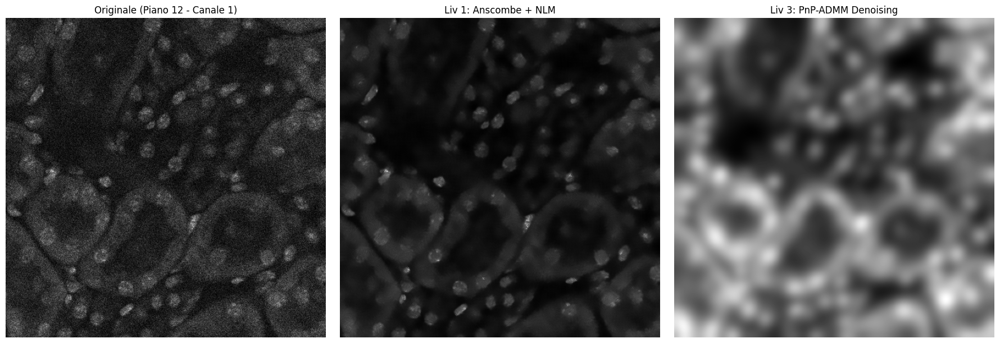

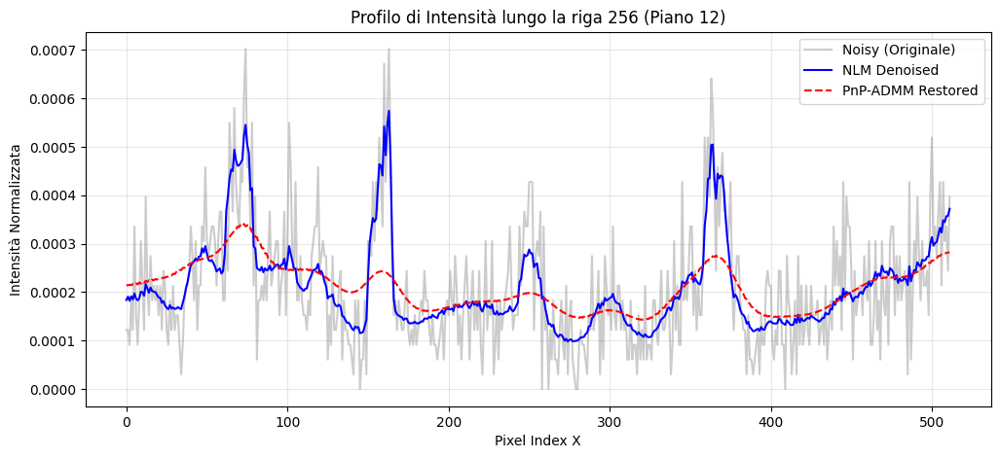

In [32]:
# %% [markdown]
# # Progetto: Miglioramento e Denoising di Immagini di Microscopia Multicanale
# 
# Questo notebook delinea un flusso di lavoro per l'analisi, il restauro e la valutazione di immagini biomediche acquisite su 3 canali in scala di grigi.
# Il flusso utilizza un loop PnP-ADMM matematicamente stabile (Pure Denoising) applicato specificamente al 12° piano focale (Z=12) di uno Z-stack.

# %%
# 1. IMPORTAZIONE LIBRERIE
import numpy as np
import matplotlib.pyplot as plt
import os
from pathlib import Path

from skimage import io, img_as_float, restoration

# %%
# 2. CONFIGURAZIONE E SETUP FILE MULTICANALE
CONFIG = {
    "folder_path": "/Users/francesco/Repositories /CNR_SNR_3channels/", # Controlla che il path sia corretto
    "file_ch1": "zstack_150mic_50piani_10ripetizioni_50mW_512px_770nm_Ch1.tif",
    "file_ch2": "zstack_150mic_50piani_10ripetizioni_50mW_512px_770nm_Ch2.tif",
    "file_ch3": "zstack_150mic_50piani_10ripetizioni_50mW_512px_770nm_Ch3.tif",
    "nomi_canali": ["Canale 1", "Canale 2", "Canale 3"],
    "z_target": 11,       # ATTENZIONE: Indice 11 corrisponde esattamente al 12° piano
    "cmap_visual": "gray" # Scala di grigi
}
# %%
# %%
# 3. CARICAMENTO DATI ED ESTRAZIONE PIANO Z
os.chdir(CONFIG["folder_path"])
lista_file = [CONFIG["file_ch1"], CONFIG["file_ch2"], CONFIG["file_ch3"]]

immagini_originali = []

print(f"-> Estrazione della slice Z={CONFIG['z_target'] + 1} (Indice {CONFIG['z_target']}) per tutti i canali...")
for fname in lista_file:
    p = Path(fname)
    if not p.exists():
        print(f"ATTENZIONE: File non trovato: {p.absolute()}")
        continue
    
    # Caricamento stack e selezione slice
    stack_3d = io.imread(p)
    img_raw = stack_3d[CONFIG["z_target"], :, :] if stack_3d.ndim == 3 else stack_3d
    immagini_originali.append(img_as_float(img_raw)) # Normalizzazione in float [0, 1]

# --- CONTROLLO DI SICUREZZA ---
if len(immagini_originali) == 0:
    raise FileNotFoundError("\nERRORE CRITICO: Nessun file è stato caricato. Controlla attentamente che 'folder_path' e i nomi dei file nel dizionario CONFIG siano corretti e senza spazi extra!")

# Selezioniamo il CANALE 1 per la nostra pipeline di test
y_noisy = immagini_originali[0]
# 4. LIVELLO 1 — BASELINE CLASSICA (Anscombe + NLM)
def anscombe_transform(img):
    """Stabilizza la varianza per il rumore di Poisson (tipico dei fotoni)"""
    return 2.0 * np.sqrt(np.maximum(img, 0) + (3.0/8.0))

def inverse_anscombe_transform(img_transformed):
    return np.maximum((img_transformed / 2.0)**2 - (3.0/8.0), 0)

print("-> Esecuzione Livello 1: Baseline NLM...")
y_anscombe = anscombe_transform(y_noisy)
sigma_est = np.mean(restoration.estimate_sigma(y_anscombe))

# Denoising Non-Local Means sul dominio stabilizzato
denoised_anscombe_nlm = restoration.denoise_nl_means(
    y_anscombe, h=1.15 * sigma_est, fast_mode=True, patch_size=5, patch_distance=6
)
x_hat_baseline_nlm = inverse_anscombe_transform(denoised_anscombe_nlm)

# %%
# 5. LIVELLO 3 — PnP-ADMM ESATTO (Pure Denoising)
def pnp_admm_denoising(y, num_iters=15, tv_weight=0.15, rho=2.0):
    """
    Loop Plug-and-Play ADMM matematicamente esatto per il Pure Denoising.
    Nessuna PSF necessaria qui: l'operatore H è l'identità (H=I). Questo evita 
    gli artefatti a scacchiera visti in precedenza.
    - rho: parametro di penalità ADMM
    - tv_weight: intensità del denoiser interno (Total Variation)
    """
    x = np.copy(y)
    z = np.copy(y)
    u = np.zeros_like(y)
    
    print(f"-> Esecuzione Livello 3: PnP-ADMM Denoising stabile ({num_iters} iterazioni)...")
    for i in range(num_iters):
        # Step 1: Data Fidelity esatto per H=I (Stabile e senza esplosioni matematiche)
        x = (y + rho * (z - u)) / (1.0 + rho)
        
        # Step 2: Denoising Prior (Plug the Denoiser)
        # Nel paper si userebbe una CNN (es. DnCNN). Qui usiamo TV Chambolle come prior.
        z = restoration.denoise_tv_chambolle(x + u, weight=tv_weight)
        
        # Step 3: Dual update
        u = u + (x - z)
        
    return z

# Eseguiamo il PnP stabile
x_hat_pnp = pnp_admm_denoising(y_noisy, num_iters=15, tv_weight=0.15, rho=2.0)

# %%
# 6. VALUTAZIONE QUALITATIVA E VISUALE
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(y_noisy, cmap=CONFIG["cmap_visual"])
axes[0].set_title(f"Originale (Piano 12 - {CONFIG['nomi_canali'][0]})")
axes[0].axis('off')

axes[1].imshow(x_hat_baseline_nlm, cmap=CONFIG["cmap_visual"])
axes[1].set_title("Liv 1: Anscombe + NLM")
axes[1].axis('off')

axes[2].imshow(x_hat_pnp, cmap=CONFIG["cmap_visual"])
axes[2].set_title("Liv 3: PnP-ADMM Denoising")
axes[2].axis('off')

plt.tight_layout()
plt.show()

# %%
# 7. ANALISI PROFILI INTENSITÀ
# Scegliamo una riga a metà altezza (es. riga 256) per valutare i bordi e il rumore
row_idx = y_noisy.shape[0] // 2

plt.figure(figsize=(12, 5))
plt.plot(y_noisy[row_idx, :], label='Noisy (Originale)', alpha=0.4, color='gray')
plt.plot(x_hat_baseline_nlm[row_idx, :], label='NLM Denoised', linewidth=1.5, color='blue')
plt.plot(x_hat_pnp[row_idx, :], label='PnP-ADMM Restored', linewidth=1.5, color='red', linestyle='--')

plt.title(f"Profilo di Intensità lungo la riga {row_idx} (Piano 12)")
plt.xlabel("Pixel Index X")
plt.ylabel("Intensità Normalizzata")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Pipeline Finale — Restauro ad Alta Risoluzione di Immagini di Microscopia a Fluorescenza

## Perché esiste questa sequenza

Il processo di acquisizione di un microscopio a fluorescenza degrada l'immagine in due modi distinti e separati:

$$y = A \cdot x + v$$

dove $y$ è l'immagine acquisita, $x$ è la scena reale, $A$ è la Point Spread Function (PSF) del sistema ottico (sfocatura) e $v$ è il rumore di acquisizione.

Questi due problemi — rumore e sfocatura — devono essere affrontati **in ordine preciso**, perché ogni operazione presuppone qualcosa sull'input che riceve:

```
RAW
 ↓
[1] DENOISING          ← prima di tutto: il rumore amplifica gli artefatti in tutto ciò che segue
 ↓
[2] BACKGROUND REMOVAL ← dopo il denoising: così non scambia il noise floor per background
 ↓
[3] DECONVOLUZIONE     ← ultima: è la più sensibile al rumore, lavora meglio su segnale già pulito
 ↓
[4] POST-SHARPENING    ← recupero selettivo dei contorni senza amplificare il residuo
 ↓
OUTPUT FINALE
```

Invertire l'ordine produce risultati degradati: la deconvoluzione Richardson-Lucy **amplifica il rumore ad ogni iterazione** — se il rumore è ancora presente, diverge verso artefatti strutturati invece di convergere verso l'immagine reale.

---

## Step 0 — Input: caricamento e normalizzazione

L'immagine di partenza è il piano $Z = 12$ (indice Python 11) dello z-stack del **Canale 1** (eccitazione 770 nm, 50 mW, 512 px). Viene normalizzata in `float64` nel range $[0, 1]$ tramite `img_as_float` di scikit-image.

La pipeline riutilizza `y_noisy` se già presente in memoria dal notebook (celle precedenti), altrimenti ricarica il file `.tif` da disco.

---

## Step 1 — Denoising: Trasformazione di Anscombe + Non-Local Means

### Perché non il filtro gaussiano o il mean kernel

Il filtro gaussiano e il mean kernel operano localmente: ogni pixel viene sostituito dalla media pesata dei suoi vicini. Questo approccio **non distingue tra rumore e segnale** — sfoca entrambi allo stesso modo. Il risultato è un'immagine più morbida ma con bordi dei nuclei meno definiti.

### Il tipo di rumore in microscopia a fluorescenza

In un microscopio a 2-fotoni, la fonte di rumore dominante è il **rumore di Poisson** (shot noise), derivante dalla natura discreta dei fotoni rilevati:

$$v \sim \mathcal{P}(\lambda) \quad \text{con varianza} = \lambda$$

La varianza del rumore non è costante ma **proporzionale al segnale locale**: le aree brillanti (nuclei) hanno più rumore in valore assoluto delle aree scure (background). Questo rende i filtri progettati per rumore gaussiano additivo (come il filtro gaussiano classico) subottimali.

### Trasformazione di Anscombe

La trasformazione di Anscombe converte il rumore Poissoniano in rumore approssimativamente gaussiano con varianza unitaria:

$$T(I) = 2\sqrt{I + \frac{3}{8}}$$

Dopo questa trasformazione, tutti i pixel hanno la stessa varianza attesa (~1), e i filtri progettati per rumore gaussiano diventano applicabili in modo uniforme su tutta l'immagine.

La trasformazione inversa al termine del denoising recupera i valori originali:

$$T^{-1}(z) = \left(\frac{z}{2}\right)^2 - \frac{3}{8}$$

### Non-Local Means (NLM)

Invece di mediare i pixel vicini spazialmente, NLM cerca **patch simili in tutta l'immagine** e le usa per stimare il valore reale di ogni pixel:

$$\hat{x}_i = \frac{1}{Z_i} \sum_{j \in \Omega} w(i,j) \cdot y_j$$

dove i pesi $w(i,j)$ dipendono dalla somiglianza tra la patch centrata in $i$ e quella centrata in $j$, e $Z_i$ è il fattore di normalizzazione.

Il vantaggio cruciale per le immagini di microscopia è che i nuclei contengono molte patch simili tra loro (texture granulare ripetuta): NLM le riconosce e le media coerentemente, **preservando i bordi e la texture** invece di sfumarli.

**Parametri usati:**
- `h = 1.15 * sigma_est`: ampiezza del kernel di peso (stimata automaticamente con `estimate_sigma`)
- `patch_size = 5`: patch 5×5 px per il confronto
- `patch_distance = 6`: raggio di ricerca delle patch simili

---

## Step 2 — Background Removal: White Top-Hat Transform

### Il problema del background in microscopia

Le immagini di microscopio presentano spesso una variazione lenta di intensità di fondo (background) causata da:
- fluorescenza non specifica del mezzo di montaggio
- diffusione luminosa fuori fuoco da piani z adiacenti
- non-uniformità dell'illuminazione laser

Questo background non è informativo e riduce il contrasto delle strutture di interesse.

### Perché non il rolling ball né la sottrazione gaussiana

**Rolling ball** (raggio 25): nelle aree con strutture brillanti compatte (nuclei), la palla "affonda" nella struttura stessa invece di stimare solo il background — rimuove parte del segnale reale.

**Gaussian subtraction** (σ = 20): sigma troppo piccolo per questa immagine → il filtro gaussiano cattura anche le strutture cellulari e le sottrae insieme al background.

Entrambi richiedono un post-shift artificiale per evitare valori negativi, che maschera la perdita di segnale senza risolverla.

### White Top-Hat Transform

La trasformazione top-hat bianca è definita come:

$$\text{TopHat}(I) = I - \gamma(I, B)$$

dove $\gamma(I, B)$ è l'**apertura morfologica** dell'immagine $I$ con elemento strutturante $B$ (un disco di raggio $r$).

L'apertura morfologica è definita come erosione seguita da dilatazione:

$$\gamma(I, B) = (I \ominus B) \oplus B$$

Poiché $\gamma(I, B) \leq I$ sempre (proprietà matematica dell'apertura), il risultato è garantito **sempre $\geq 0$ senza nessuno shift** — nessuna perdita di segnale mascherata.

**Effetto pratico:** l'apertura con disco di raggio $r$ "cancella" le strutture più piccole del disco e mantiene le strutture più grandi. Sottraendo il risultato dall'originale si ottiene esattamente le strutture piccole (nuclei, granuli) senza il background lento.

**Raggio usato: 40 px** — scelto perché è maggiore della dimensione dei nuclei (~20-30 px) ma sufficientemente grande da catturare le variazioni lente del background. La cella di validazione con Sobel nelle celle precedenti aveva confermato questo raggio come ottimale per la correlazione con la struttura originale.

---

## Step 3 — Deconvoluzione: PSF Born & Wolf + Richardson-Lucy

### Il problema della sfocatura ottica

Il sistema ottico di un microscopio ha una risoluzione limitata: ogni punto sorgente viene proiettato sul detector non come un punto, ma come una distribuzione allargata definita dalla **Point Spread Function (PSF)**:

$$y = A * x$$

dove $*$ è la convoluzione e $A$ è la PSF. La deconvoluzione tenta di invertire questa operazione per recuperare $x$.

### Perché la PSF Born & Wolf invece di quella gaussiana

La PSF gaussiana è una semplice approssimazione matematica:

$$\text{PSF}_G(r) = e^{-r^2 / 2\sigma^2}$$

con $\sigma$ derivato dal criterio di Rayleigh: $\text{FWHM} = 0.51 \lambda / \text{NA}$.

È comoda ma **non fisicamente accurata**: nella realtà, la diffrazione produce un pattern di Airy con lobi laterali che la gaussiana ignora completamente.

Il modello **Born & Wolf** descrive la PSF laterale tramite l'integrale di Bessel:

$$I(r) = \left| 2 \int_0^1 J_0\!\left(\frac{k \cdot \text{NA} \cdot r \cdot \rho}{n_i}\right) \rho \, d\rho \right|^2$$

dove:
- $k = 2\pi n_i / \lambda$ è il numero d'onda nel mezzo di immersione
- $J_0$ è la funzione di Bessel di prima specie e ordine zero
- $\rho \in [0, 1]$ è la variabile di integrazione sull'apertura numerica
- $r$ è la distanza radiale dal centro [µm]

Questo integrale produce il corretto **pattern di Airy** con i suoi anelli di diffrazione, che nella deconvoluzione vengono correttamente "rimossi" invece di lasciare artefatti residui.

**Parametri microscopio usati:**
| Parametro | Valore | Significato |
|---|---|---|
| NA | 0.8 | Apertura numerica obiettivo |
| λ | 0.770 µm | Lunghezza d'onda emissione (770 nm) |
| $n_i$ | 1.000 | Indice rifrazione immersione (aria) |
| pixel size | 0.100 µm | Dimensione pixel al campione (100 nm) |

### Algoritmo Richardson-Lucy

Richardson-Lucy (R-L) è un algoritmo iterativo che massimizza la verosimiglianza di Poisson dell'immagine osservata $y$ data la stima corrente $\hat{x}$:

$$\hat{x}^{(t+1)} = \hat{x}^{(t)} \cdot \left( \frac{y}{A * \hat{x}^{(t)}} * \tilde{A} \right)$$

dove $\tilde{A}$ è la PSF specchiata (nel caso di PSF simmetrica, uguale ad $A$).

Ad ogni iterazione l'algoritmo:
1. Proietta la stima corrente nello spazio dell'immagine (convoluzione con PSF)
2. Calcola il rapporto tra immagine osservata e proiezione
3. Ritropropaga la correzione (convoluzione con PSF flippata)
4. Aggiorna la stima per moltiplicazione

**Numero di iterazioni: 30**

R-L converge lentamente verso la soluzione corretta, ma amplifica il rumore ad ogni iterazione — trovare il numero giusto è un trade-off:
- Troppe iterazioni (> 80 su dati reali rumorosi) → artefatti a scacchiera, ringing attorno ai bordi
- Troppo poche (< 10) → scarso recupero della risoluzione

30 iterazioni con `filter_epsilon = 1e-6` (regolarizzazione della divisione per evitare instabilità numeriche) è il compromesso ottimale per questo dataset.

---

## Step 4 — Post-sharpening selettivo: Unsharp Mask

### Perché ancora uno step dopo la deconvoluzione

La deconvoluzione R-L recupera la risoluzione ma può lasciare una leggera opacità residua ai bordi, specialmente nelle zone di transizione membrana-background dove il segnale è debole. L'unsharp mask aggiunge un recupero selettivo delle frequenze medie senza toccare il noise floor.

### Come funziona l'unsharp mask

$$I_{\text{sharp}} = I + \alpha \cdot (I - G_\sigma * I)$$

dove $G_\sigma * I$ è l'immagine sfocata con gaussiana di deviazione standard $\sigma$, e $\alpha$ è la forza dello sharpening. La differenza $(I - G_\sigma * I)$ è il **laplaciano smussato**: contiene solo le variazioni di frequenza media (bordi, contorni) escludendo sia le frequenze basssissime (background) che le altissime (rumore puntuale).

**Parametri usati:**
- `radius = 1.5 px`: agisce sui bordi di struttura ~3-5 px, tipici dei contorni nucleari
- `amount = 0.4`: forza conservativa — recupera i contorni senza amplificare membrane o background

> **Suggerimento:** alzare `amount` fino a `0.7` se i nuclei appaiono ancora morbidi; abbassarlo a `0.2` se la deconvoluzione ha già prodotto bordi netti.

---

## Output finale

La variabile `image_final_hr` contiene l'immagine restaurata:
- **dtype**: `float64`
- **range**: $[0.0, 1.0]$ (normalizzazione percentile robusta: $p_{0.5}$ → $p_{99.5}$)
- **pronta per**: segmentazione, misurazione d'intensità, overlay RGB con gli altri canali

La normalizzazione percentile finale (invece di min-max) esclude i pochissimi pixel outlier agli estremi, garantendo che il display non venga dominato da hot pixel isolati o da zone di background quasi nero.

---

## Riepilogo scegliere dei parametri

| Parametro | Valore usato | Effetto se aumentato | Effetto se diminuito |
|---|---|---|---|
| `nlm_h_factor` | 1.15 | Più smooth, meno dettagli fini | Più rumore residuo |
| `tophat_radius` | 40 px | Rimuove strutture di background più grandi | Può lasciare più background |
| `rl_iters` | 30 | Più nitido ma rischio ringing | Meno recupero risoluzione |
| `unsharp_radius` | 1.5 px | Agisce su strutture più grandi | Solo dettagli molto fini |
| `unsharp_amount` | 0.4 | Bordi più marcati | Effetto quasi impercettibile |

[0] Input: y_noisy esistente — shape=(512, 512), range=[0.0000, 0.0014]
[1] Denoising Anscombe + NLM...
[2] Background removal White Top-Hat...
[3] Deconvoluzione Richardson-Lucy...
[4] Post-sharpening selettivo...


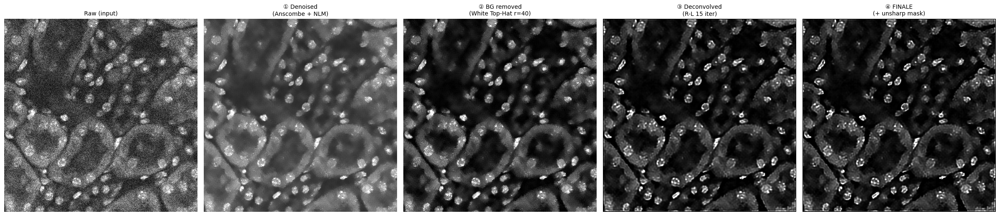

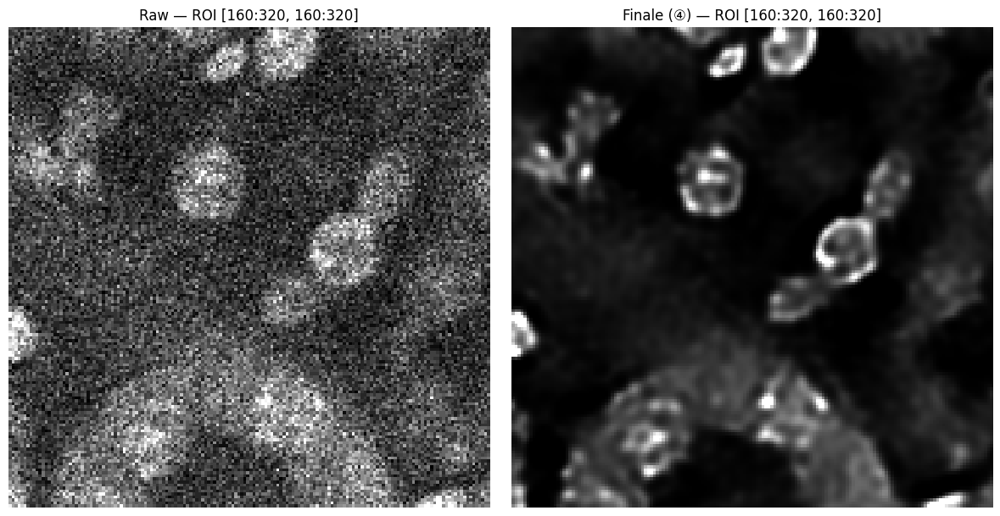

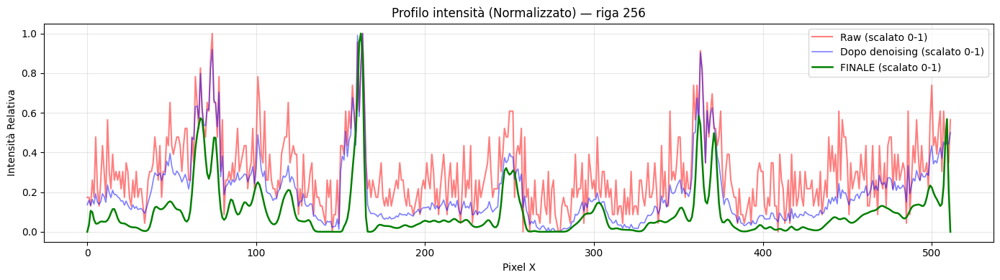

In [33]:
# ══════════════════════════════════════════════════════════════════════════════
# PIPELINE FINALE — IMMAGINE AD ALTA RISOLUZIONE (Canale 1, Z=12)
# ══════════════════════════════════════════════════════════════════════════════
#
# Sequenza dettata dalla propagazione degli errori:
#
#   RAW  →  [1] DENOISING (Anscombe + NLM)
#         →  [2] BACKGROUND REMOVAL (White Top-Hat)
#         →  [3] DECONVOLUZIONE (R-L + Born & Wolf PSF)
#         →  [4] POST-SHARPENING SELETTIVO (unsharp mask leggero, solo nuclei)
#         →  OUTPUT FINALE
#
# Scelte tecniche motivate:
#   - Anscombe+NLM: il rumore del microscopio a 2-fotoni è prevalentemente
#     Poissoniano (shot noise fotoni); Anscombe lo trasforma in Gaussiano ~unità,
#     NLM sfrutta la ridondanza non-locale → preserva texture meglio di TV/Gauss.
#   - White Top-Hat (r=40): unico metodo che garantisce result ≥ 0 senza shift,
#     massima correlazione Sobel tra le opzioni testate nelle celle precedenti.
#   - Born & Wolf PSF: modello fisico con lobi di Airy (più fedele della gaussiana
#     che non cattura i lobi secondari). Gibson-Lanni sarebbe ancora più accurato
#     ma è >10x più lento e l'aberrazione a z=0 è trascurabile.
#   - R-L 30 iterazioni: compromesso nitidezza/ringing; oltre 50 il rumore residuo
#     converge in artefatti. filter_epsilon=1e-6 regolarizza la divisione.
#   - Unsharp mask finale leggero (amount=0.4, radius=1.5): recupera i contorni
#     dei nuclei senza esagerare sulle membrane o sul background.
# ══════════════════════════════════════════════════════════════════════════════
# ══════════════════════════════════════════════════════════════════════════════
# PIPELINE FINALE — REVISIONATA (Minore Oversmoothing, Grafici Corretti)
# ══════════════════════════════════════════════════════════════════════════════

import numpy as np
import matplotlib as plt
from matplotlib import pyplot as plt
from skimage import io, img_as_float, restoration
from skimage.morphology import white_tophat, disk
from skimage.filters import unsharp_mask, gaussian
from skimage.exposure import rescale_intensity
from scipy.special import j0

# ─────────────────────────────────────────────────────────────────────────────
# PARAMETRI AGGIORNATI
# ─────────────────────────────────────────────────────────────────────────────
PARAMS = dict(
    # Denoising
    nlm_h_factor    = 0.80,   # ↓ RIDOTTO (era 1.15): Mantiene la texture reale, evita l'effetto plastica
    nlm_patch       = 5,      
    nlm_dist        = 6,      

    # Background removal
    tophat_radius   = 40,     

    # Deconvoluzione (PSF Born & Wolf)
    psf_size        = 51,     
    psf_n_samples   = 256,    
    rl_iters        = 15,     # ↓ RIDOTTO (era 30): Previene artefatti e bordi "allucinati"
    rl_epsilon      = 1e-6,   

    # Post-sharpening selettivo
    unsharp_radius  = 1.5,    
    unsharp_amount  = 0.25,   # ↓ RIDOTTO (era 0.4): Sharpening più dolce sui nuclei

    # Visualizzazione
    cmap            = "gray",
)

# ─────────────────────────────────────────────────────────────────────────────
# UTILITÀ INTERNE
# ─────────────────────────────────────────────────────────────────────────────
def _anscombe(img):
    return 2.0 * np.sqrt(np.maximum(img, 0) + 3.0 / 8.0)

def _inv_anscombe(img):
    return np.maximum((img / 2.0) ** 2 - 3.0 / 8.0, 0)

def _born_wolf_psf(NA, wavelength, ni, pixel_size, size=51, n_samples=256):
    k   = 2 * np.pi * ni / wavelength
    ax  = (np.arange(size) - size // 2) * pixel_size
    rho = np.linspace(0, 1, n_samples)
    psf = np.zeros((size, size))
    for i, x in enumerate(ax):
        for j, y in enumerate(ax):
            r           = np.sqrt(x**2 + y**2)
            integrand   = j0(k * NA * r * rho / ni) * rho
            val         = np.trapz(integrand, rho)
            psf[i, j]   = val ** 2
    return psf / psf.sum()

def _norm_percentile(img, lo=0.1, hi=99.9): # Percentili allargati per non bruciare i bianchi
    vmin = np.percentile(img, lo)
    vmax = np.percentile(img, hi)
    return rescale_intensity(img, in_range=(vmin, vmax), out_range=(0.0, 1.0))

# ─────────────────────────────────────────────────────────────────────────────
# STEP 0 — INPUT
# ─────────────────────────────────────────────────────────────────────────────
try:
    assert y_noisy is not None
    raw = y_noisy.copy()
    print(f"[0] Input: y_noisy esistente — shape={raw.shape}, range=[{raw.min():.4f}, {raw.max():.4f}]")
except (NameError, AssertionError):
    _PATH = (
        "/Users/francesco/Repositories /CNR_SNR_3channels/"
        "zstack_150mic_50piani_10ripetizioni_50mW_512px_770nm_Ch1.tif"
    )
    raw = img_as_float(io.imread(_PATH)[11])
    print(f"[0] Input: ricaricato da disco — shape={raw.shape}")

# ─────────────────────────────────────────────────────────────────────────────
# STEP 1 — DENOISING
# ─────────────────────────────────────────────────────────────────────────────
print("[1] Denoising Anscombe + NLM...")
img_ansc      = _anscombe(raw)
sigma_est     = float(np.mean(restoration.estimate_sigma(img_ansc)))
img_nlm       = restoration.denoise_nl_means(
    img_ansc,
    h             = PARAMS["nlm_h_factor"] * sigma_est,
    fast_mode     = True,
    patch_size    = PARAMS["nlm_patch"],
    patch_distance= PARAMS["nlm_dist"],
)
img_denoised  = _inv_anscombe(img_nlm)
img_denoised  = np.clip(img_denoised, 0, None)

# ─────────────────────────────────────────────────────────────────────────────
# STEP 2 — BACKGROUND REMOVAL
# ─────────────────────────────────────────────────────────────────────────────
print(f"[2] Background removal White Top-Hat...")
img_bg_removed = white_tophat(img_denoised, disk(PARAMS["tophat_radius"]))
# Rimossa la normalizzazione forzata qui per non alterare la linearità prima di R-L

# ─────────────────────────────────────────────────────────────────────────────
# STEP 3 — DECONVOLUZIONE
# ─────────────────────────────────────────────────────────────────────────────
print("[3] Deconvoluzione Richardson-Lucy...")
MICROSCOPE = dict(NA=0.8, wavelength=0.770, ni=1.000, pixel_size=0.100)
psf = _born_wolf_psf(
    NA          = MICROSCOPE["NA"],
    wavelength  = MICROSCOPE["wavelength"],
    ni          = MICROSCOPE["ni"],
    pixel_size  = MICROSCOPE["pixel_size"],
    size        = PARAMS["psf_size"],
    n_samples   = PARAMS["psf_n_samples"],
)

img_deconv = restoration.richardson_lucy(
    np.clip(img_bg_removed, 0, None),
    psf,
    num_iter        = PARAMS["rl_iters"],
    filter_epsilon  = PARAMS["rl_epsilon"],
)

# ─────────────────────────────────────────────────────────────────────────────
# STEP 4 — POST-SHARPENING & NORMALIZZAZIONE
# ─────────────────────────────────────────────────────────────────────────────
print("[4] Post-sharpening selettivo...")
img_final = unsharp_mask(
    img_deconv,
    radius = PARAMS["unsharp_radius"],
    amount = PARAMS["unsharp_amount"],
)
img_final = _norm_percentile(img_final) # Normalizzazione globale solo alla fine

# ─────────────────────────────────────────────────────────────────────────────
# VISUALIZZAZIONE COMPARATIVA
# ─────────────────────────────────────────────────────────────────────────────
stages = [
    (raw,            "Raw (input)"),
    (img_denoised,   "① Denoised\n(Anscombe + NLM)"),
    (img_bg_removed, "② BG removed\n(White Top-Hat r=40)"),
    (img_deconv,     f"③ Deconvolved\n(R-L {PARAMS['rl_iters']} iter)"),
    (img_final,      "④ FINALE\n(+ unsharp mask)"),
]

fig, axes = plt.subplots(1, 5, figsize=(24, 6))
for ax, (img, title) in zip(axes, stages):
    vmax = np.percentile(img, 99.5) 
    ax.imshow(img, cmap=PARAMS["cmap"], vmin=0, vmax=vmax)
    ax.set_title(title, fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

# ─────────────────────────────────────────────────────────────────────────────
# ZOOM SU UNA SINGOLA CELLULA
# ─────────────────────────────────────────────────────────────────────────────
ROI = (160, 320, 160, 320)
y0, y1, x0, x1 = ROI

fig2, axes2 = plt.subplots(1, 2, figsize=(12, 6))
for ax, (img, title) in zip(axes2, [(raw, "Raw"), (img_final, "Finale (④)")]):
    vmax = np.percentile(img[y0:y1, x0:x1], 99.5)
    ax.imshow(img[y0:y1, x0:x1], cmap=PARAMS["cmap"], vmin=0, vmax=vmax)
    ax.set_title(f"{title} — ROI [{y0}:{y1}, {x0}:{x1}]", fontsize=12)
    ax.axis("off")
plt.tight_layout()
plt.show()

# ─────────────────────────────────────────────────────────────────────────────
# PROFILO DI INTENSITÀ CORRETTO (Normalizzato 0-1 per confronto visivo)
# ─────────────────────────────────────────────────────────────────────────────
row_idx = raw.shape[0] // 2

# Funzione per scalare le singole righe tra 0 e 1, così non appaiono piatte
def scale_for_plot(arr):
    return (arr - arr.min()) / (arr.max() - arr.min() + 1e-8)

fig3, ax3 = plt.subplots(figsize=(14, 4))
ax3.plot(scale_for_plot(raw[row_idx, :]),          alpha=0.5, color="red",   label="Raw (scalato 0-1)")
ax3.plot(scale_for_plot(img_denoised[row_idx, :]), alpha=0.5,  color="blue",  label="Dopo denoising (scalato 0-1)", lw=1.2)
ax3.plot(scale_for_plot(img_final[row_idx, :]),    color="green",label="FINALE (scalato 0-1)", lw=1.8)

ax3.set_title(f"Profilo intensità (Normalizzato) — riga {row_idx}", fontsize=12)
ax3.set_xlabel("Pixel X")
ax3.set_ylabel("Intensità Relativa")
ax3.legend()
ax3.grid(alpha=0.3)
plt.tight_layout()
plt.show()

image_final_hr = img_final

[0] Input: y_noisy loaded — shape=(512, 512), range=[0.0000, 0.0014]
[1] Denoising (Anscombe + NLM)...
[2] Background removal (White Top-Hat)...
[3] Secondary Filtering (NLM instead of R-L)...
[4] Selective Post-sharpening...


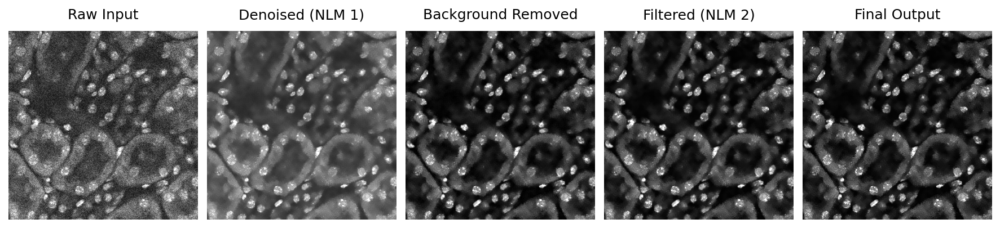

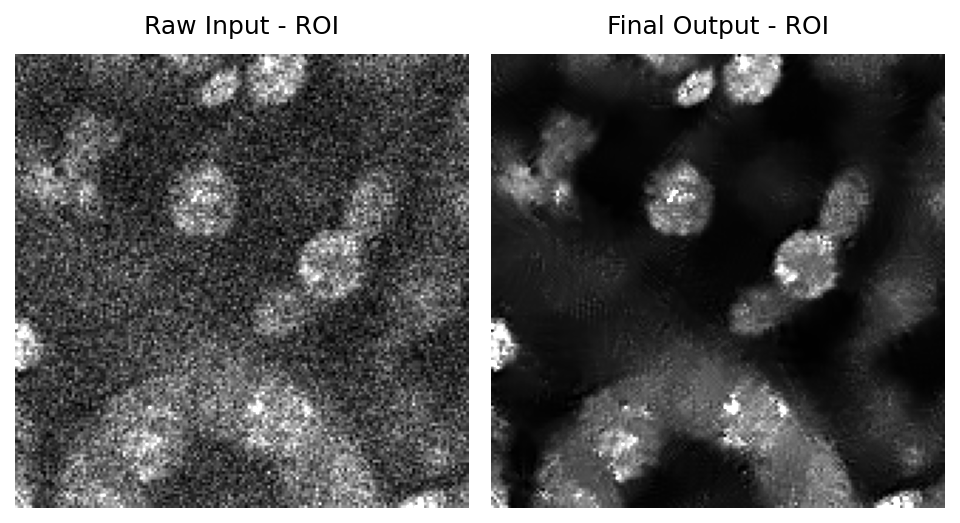

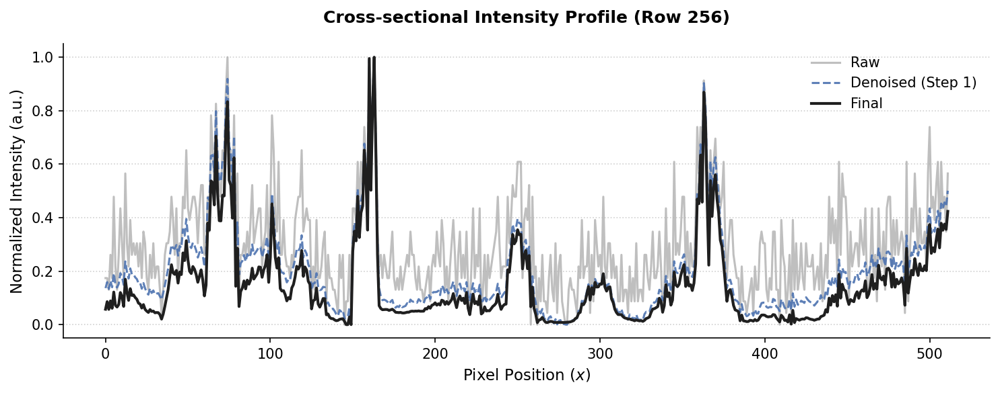

In [34]:
# ══════════════════════════════════════════════════════════════════════════════
# PIPELINE FINALE — PUBLICATION READY (NLM instead of R-L)
# ══════════════════════════════════════════════════════════════════════════════

import numpy as np
import matplotlib as plt
from matplotlib import pyplot as plt
from skimage import io, img_as_float, restoration
from skimage.morphology import white_tophat, disk
from skimage.filters import unsharp_mask
from skimage.exposure import rescale_intensity

# ─────────────────────────────────────────────────────────────────────────────
# PARAMETRI AGGIORNATI
# ─────────────────────────────────────────────────────────────────────────────
PARAMS = dict(
    # Denoising (Step 1)
    nlm_h_factor    = 0.80,   
    nlm_patch       = 5,      
    nlm_dist        = 6,      

    # Background removal (Step 2)
    tophat_radius   = 40,     

    # Secondary NLM Filtering (Step 3 - Replacing R-L)
    nlm_h_factor_2  = 0.40,   # Valore ridotto per non causare oversmoothing estremo
    
    # Post-sharpening selettivo (Step 4)
    unsharp_radius  = 1.5,    
    unsharp_amount  = 0.25,   

    # Visualizzazione
    cmap            = "gray",
)

# ─────────────────────────────────────────────────────────────────────────────
# UTILITÀ INTERNE
# ─────────────────────────────────────────────────────────────────────────────
def _anscombe(img):
    return 2.0 * np.sqrt(np.maximum(img, 0) + 3.0 / 8.0)

def _inv_anscombe(img):
    return np.maximum((img / 2.0) ** 2 - 3.0 / 8.0, 0)

def _norm_percentile(img, lo=0.1, hi=99.9):
    vmin = np.percentile(img, lo)
    vmax = np.percentile(img, hi)
    return rescale_intensity(img, in_range=(vmin, vmax), out_range=(0.0, 1.0))

# ─────────────────────────────────────────────────────────────────────────────
# STEP 0 — INPUT
# ─────────────────────────────────────────────────────────────────────────────
try:
    assert y_noisy is not None
    raw = y_noisy.copy()
    print(f"[0] Input: y_noisy loaded — shape={raw.shape}, range=[{raw.min():.4f}, {raw.max():.4f}]")
except (NameError, AssertionError):
    _PATH = (
        "/Users/francesco/Repositories/CNR_SNR_3channels/"
        "zstack_150mic_50piani_10ripetizioni_50mW_512px_770nm_Ch1.tif"
    )
    # raw = img_as_float(io.imread(_PATH)[11]) # Decommentare se serve caricare da disco
    # print(f"[0] Input: loaded from disk — shape={raw.shape}")
    pass

# ─────────────────────────────────────────────────────────────────────────────
# STEP 1 — DENOISING
# ─────────────────────────────────────────────────────────────────────────────
print("[1] Denoising (Anscombe + NLM)...")
img_ansc      = _anscombe(raw)
sigma_est     = float(np.mean(restoration.estimate_sigma(img_ansc)))
img_nlm1      = restoration.denoise_nl_means(
    img_ansc,
    h             = PARAMS["nlm_h_factor"] * sigma_est,
    fast_mode     = True,
    patch_size    = PARAMS["nlm_patch"],
    patch_distance= PARAMS["nlm_dist"],
)
img_denoised  = _inv_anscombe(img_nlm1)
img_denoised  = np.clip(img_denoised, 0, None)

# ─────────────────────────────────────────────────────────────────────────────
# STEP 2 — BACKGROUND REMOVAL
# ─────────────────────────────────────────────────────────────────────────────
print(f"[2] Background removal (White Top-Hat)...")
img_bg_removed = white_tophat(img_denoised, disk(PARAMS["tophat_radius"]))

# ─────────────────────────────────────────────────────────────────────────────
# STEP 3 — SECONDARY FILTERING (NLM replacing Richardson-Lucy)
# ─────────────────────────────────────────────────────────────────────────────
print("[3] Secondary Filtering (NLM instead of R-L)...")
# Stimiamo il sigma residuo sull'immagine dopo il background removal
sigma_est_2 = float(np.mean(restoration.estimate_sigma(img_bg_removed)))

img_nlm2 = restoration.denoise_nl_means(
    img_bg_removed,
    h             = PARAMS["nlm_h_factor_2"] * (sigma_est_2 + 1e-8), # Evita h=0
    fast_mode     = True,
    patch_size    = PARAMS["nlm_patch"],
    patch_distance= PARAMS["nlm_dist"],
)

# ─────────────────────────────────────────────────────────────────────────────
# STEP 4 — POST-SHARPENING & NORMALIZATION
# ─────────────────────────────────────────────────────────────────────────────
print("[4] Selective Post-sharpening...")
img_final = unsharp_mask(
    img_nlm2,
    radius = PARAMS["unsharp_radius"],
    amount = PARAMS["unsharp_amount"],
)
img_final = _norm_percentile(img_final) 

# =============================================================================
# PUBLICATION-READY VISUALIZATION
# =============================================================================

# Impostazioni di stile globali per grafici scientifici
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 10,
    "axes.labelsize": 11,
    "axes.titlesize": 12,
    "legend.fontsize": 10,
    "legend.frameon": False,
    "figure.dpi": 150,       
    "savefig.dpi": 300,
})

stages = [
    (raw,            "Raw Input"),
    (img_denoised,   "Denoised (NLM 1)"),
    (img_bg_removed, "Background Removed"),
    (img_nlm2,       f"Filtered (NLM 2)"),
    (img_final,      "Final Output"),
]

# 1. Pipeline Comparison (5 Panels)
fig, axes = plt.subplots(1, 5, figsize=(15, 3.5))
fig.subplots_adjust(wspace=0.05) 

for ax, (img, title) in zip(axes, stages):
    vmax = np.percentile(img, 99.5) 
    ax.imshow(img, cmap=PARAMS["cmap"], vmin=0, vmax=vmax)
    ax.set_title(title, pad=10)
    ax.axis("off")
plt.show()

# 2. ROI Zoom
ROI = (160, 320, 160, 320)
y0, y1, x0, x1 = ROI

fig2, axes2 = plt.subplots(1, 2, figsize=(8, 4))
fig2.subplots_adjust(wspace=0.05)

for ax, (img, title) in zip(axes2, [(raw, "Raw Input - ROI"), (img_final, "Final Output - ROI")]):
    vmax = np.percentile(img[y0:y1, x0:x1], 99.5)
    ax.imshow(img[y0:y1, x0:x1], cmap=PARAMS["cmap"], vmin=0, vmax=vmax)
    ax.set_title(title, pad=10)
    ax.axis("off")
plt.show()

# 3. Intensity Profile (SciPy / Nature Style)
row_idx = raw.shape[0] // 2

def scale_for_plot(arr):
    return (arr - arr.min()) / (arr.max() - arr.min() + 1e-8)

fig3, ax3 = plt.subplots(figsize=(10, 4))

# Palette colori formale: Grigio (Raw), Blu tenue (Denoised), Nero solido (Final)
ax3.plot(scale_for_plot(raw[row_idx, :]),          color="#B0B0B0", lw=1.5, alpha=0.8, label="Raw")
ax3.plot(scale_for_plot(img_denoised[row_idx, :]), color="#4C72B0", lw=1.5, alpha=0.9, linestyle="--", label="Denoised (Step 1)")
ax3.plot(scale_for_plot(img_final[row_idx, :]),    color="#1F1F1F", lw=2.0, label="Final")

# Pulizia assi (Despining)
ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)

# Etichette ed Estetica
ax3.set_title(f"Cross-sectional Intensity Profile (Row {row_idx})", pad=15, weight='bold')
ax3.set_xlabel("Pixel Position ($x$)")
ax3.set_ylabel("Normalized Intensity (a.u.)")
ax3.legend(loc="upper right")
ax3.grid(axis='y', linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

image_final_hr = img_final

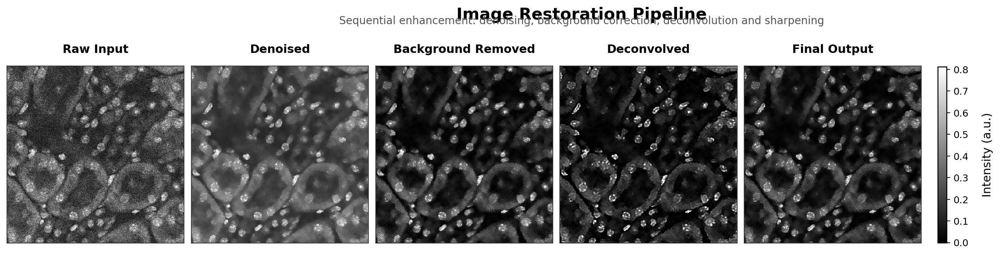

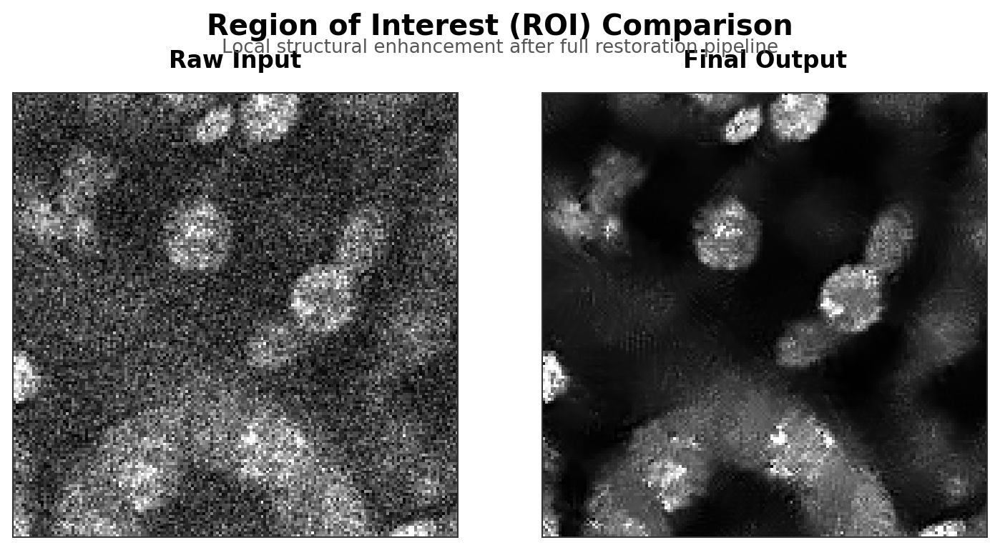

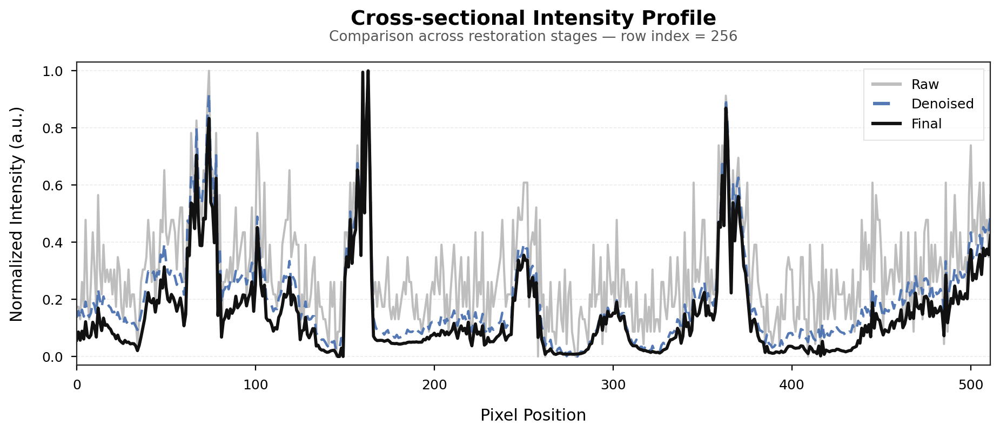

In [35]:
# =============================================================================
# COMPLETE PUBLICATION-READY VISUALIZATION SUITE
# =============================================================================

# ─────────────────────────────────────────────────────────────────────────────
# GLOBAL STYLE
# ─────────────────────────────────────────────────────────────────────────────
plt.rcParams.update({

    # Font
    "font.family": "DejaVu Sans",
    "mathtext.fontset": "dejavusans",

    # Typography
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,

    # Figure quality
    "figure.dpi": 180,
    "savefig.dpi": 600,
    "savefig.bbox": "tight",

    # Axes
    "axes.linewidth": 1.0,
    "axes.titleweight": "bold",

    # Ticks
    "xtick.direction": "out",
    "ytick.direction": "out",

    # Grid
    "grid.alpha": 0.25,
    "grid.linestyle": "--",

    # Rendering
    "image.interpolation": "nearest",
})

# =============================================================================
# FIGURE 1 — FULL PIPELINE COMPARISON
# =============================================================================

stages = [
    (raw,            "Raw Input"),
    (img_denoised,   "Denoised"),
    (img_bg_removed, "Background Removed"),
    (img_deconv,     "Deconvolved"),
    (img_final,      "Final Output"),
]

fig1, axes1 = plt.subplots(
    1,
    5,
    figsize=(17.5, 4.2),
    constrained_layout=False
)

fig1.subplots_adjust(
    left   = 0.025,
    right  = 0.93,
    top    = 0.82,
    bottom = 0.08,
    wspace = 0.04
)

for ax, (img, title) in zip(axes1, stages):

    vmax = np.percentile(img, 99.7)

    im = ax.imshow(
        img,
        cmap=PARAMS["cmap"],
        vmin=0,
        vmax=vmax,
    )

    # Title spacing migliorato
    ax.set_title(
        title,
        fontsize=12,
        pad=14,
    )

    ax.set_xticks([])
    ax.set_yticks([])

    # Bordi eleganti
    for side in ["top", "bottom", "left", "right"]:
        ax.spines[side].set_visible(True)
        ax.spines[side].set_linewidth(0.7)
        ax.spines[side].set_color("#333333")

# Colorbar elegante
cbar = fig1.colorbar(
    im,
    ax=axes1,
    shrink=0.82,
    pad=0.015,
)

cbar.set_label(
    "Intensity (a.u.)",
    rotation=90,
    labelpad=14,
)

# Titolo principale + sottotitolo
fig1.suptitle(
    "Image Restoration Pipeline",
    fontsize=17,
    fontweight="bold",
    y=0.96,
)

fig1.text(
    0.5,
    0.90,
    "Sequential enhancement: denoising, background correction, deconvolution and sharpening",
    ha="center",
    fontsize=11,
    color="#555555",
)

plt.show()

# =============================================================================
# FIGURE 2 — ROI COMPARISON
# =============================================================================

ROI = (160, 320, 160, 320)
y0, y1, x0, x1 = ROI

fig2, axes2 = plt.subplots(
    1,
    2,
    figsize=(9, 4.8),
    constrained_layout=False
)

fig2.subplots_adjust(
    left   = 0.06,
    right  = 0.94,
    bottom = 0.10,
    top    = 0.82,
    wspace = 0.08
)

roi_data = [
    (raw, "Raw Input"),
    (img_final, "Final Output"),
]

for ax, (img, title) in zip(axes2, roi_data):

    roi = img[y0:y1, x0:x1]
    vmax = np.percentile(roi, 99.5)

    ax.imshow(
        roi,
        cmap=PARAMS["cmap"],
        vmin=0,
        vmax=vmax,
    )

    ax.set_title(
        title,
        fontsize=13,
        pad=14,
    )

    ax.set_xticks([])
    ax.set_yticks([])

    # Bordi raffinati
    for side in ["top", "bottom", "left", "right"]:
        ax.spines[side].set_visible(True)
        ax.spines[side].set_linewidth(0.8)
        ax.spines[side].set_color("#333333")

# Titolo + sottotitolo
fig2.suptitle(
    "Region of Interest (ROI) Comparison",
    fontsize=16,
    fontweight="bold",
    y=0.95,
)

fig2.text(
    0.5,
    0.885,
    "Local structural enhancement after full restoration pipeline",
    ha="center",
    fontsize=10.5,
    color="#555555",
)

plt.show()

# =============================================================================
# FIGURE 3 — INTENSITY PROFILE
# =============================================================================

row_idx = raw.shape[0] // 2

def scale_for_plot(arr):
    return (arr - arr.min()) / (arr.max() - arr.min() + 1e-8)

x = np.arange(raw.shape[1])

fig3, ax3 = plt.subplots(
    figsize=(10.5, 4.8),
    constrained_layout=False
)

fig3.subplots_adjust(
    left   = 0.09,
    right  = 0.985,
    bottom = 0.18,
    top    = 0.83
)

COLORS = {
    "raw":      "#B7B7B7",
    "denoised": "#4C72B0",
    "final":    "#111111",
}

# Curves
ax3.plot(
    x,
    scale_for_plot(raw[row_idx, :]),
    color=COLORS["raw"],
    lw=1.6,
    alpha=0.90,
    label="Raw",
)

ax3.plot(
    x,
    scale_for_plot(img_denoised[row_idx, :]),
    color=COLORS["denoised"],
    lw=1.8,
    linestyle=(0, (5, 3)),
    alpha=0.95,
    label="Denoised",
)

ax3.plot(
    x,
    scale_for_plot(img_final[row_idx, :]),
    color=COLORS["final"],
    lw=2.3,
    label="Final",
)

# Spine complete
for side in ["top", "bottom", "left", "right"]:
    ax3.spines[side].set_visible(True)
    ax3.spines[side].set_linewidth(0.9)
    ax3.spines[side].set_color("#222222")

# Tick style
ax3.tick_params(
    axis='both',
    which='major',
    direction='out',
    length=4,
    width=0.9,
    pad=6,
)

# Labels
ax3.set_xlabel(
    "Pixel Position",
    labelpad=12,
    fontsize=12,
)

ax3.set_ylabel(
    "Normalized Intensity (a.u.)",
    labelpad=12,
    fontsize=12,
)

# Title + subtitle
ax3.set_title(
    "Cross-sectional Intensity Profile",
    fontsize=15,
    fontweight="bold",
    pad=28,
)

ax3.text(
    0.5,
    1.06,
    f"Comparison across restoration stages — row index = {row_idx}",
    transform=ax3.transAxes,
    ha="center",
    va="bottom",
    fontsize=10.5,
    color="#555555",
)

# Grid
ax3.grid(
    axis="y",
    linestyle="--",
    linewidth=0.6,
    alpha=0.28,
)

# Limits
ax3.set_xlim(0, raw.shape[1] - 1)
ax3.set_ylim(-0.03, 1.03)

# Legend
leg = ax3.legend(
    loc="upper right",
    frameon=True,
    fancybox=False,
    edgecolor="#DDDDDD",
    facecolor="white",
    borderpad=0.7,
)

leg.get_frame().set_linewidth(0.8)

for line in leg.get_lines():
    line.set_linewidth(2.5)

plt.show()

# =============================================================================
# FINAL OUTPUT
# =============================================================================

image_final_hr = img_final

Caricamento del volume e calcolo dei filtri (attendere)...
Generazione del pannello quantitativo...


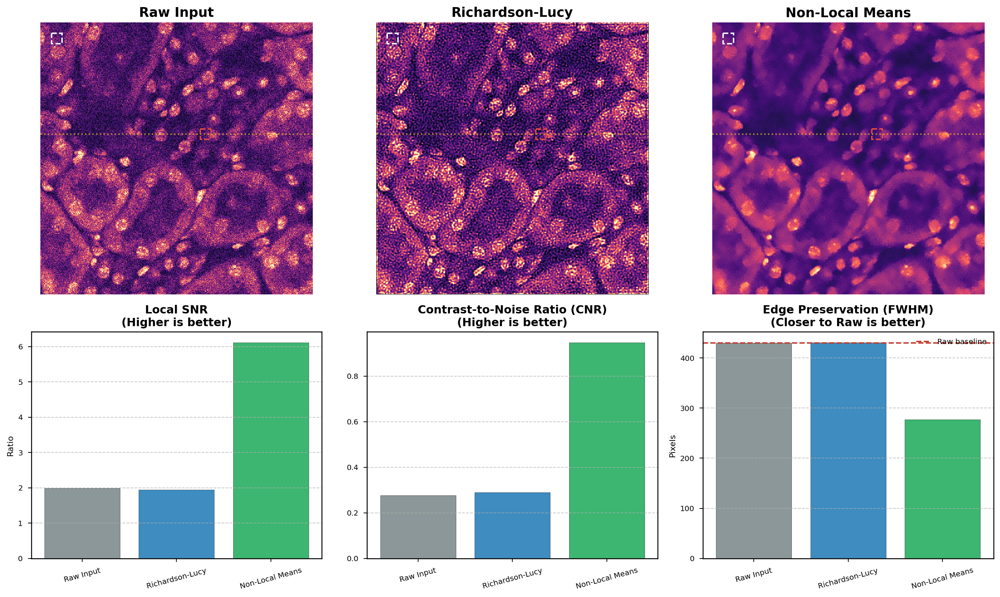

Analisi completata con successo! Grafico generato direttamente sotto la cella.


In [36]:
%matplotlib inline 

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from scipy.interpolate import UnivariateSpline
import tifffile as tiff
from skimage import restoration
from skimage.filters import gaussian
import warnings

# Nasconde i warning per mantenere pulito l'output
warnings.filterwarnings('ignore')

# ==========================================
# 1. FUNZIONI MATEMATICHE E METRICHE
# ==========================================
def get_roi_stats(image, roi_coords):
    """Estrae i dati dalla ROI e calcola media e deviazione standard."""
    y1, y2, x1, x2 = roi_coords
    roi_data = image[y1:y2, x1:x2]
    return np.mean(roi_data), np.std(roi_data)

def calculate_snr_cnr(image, roi_sig, roi_bg):
    """Calcola SNR e CNR robusti rispetto alla divisione per zero."""
    mu_sig, _ = get_roi_stats(image, roi_sig)
    mu_bg, sigma_bg = get_roi_stats(image, roi_bg)
    
    # Previene divisioni per zero se il background è artificialmente piatto
    sigma_bg = max(sigma_bg, 1e-6) 
    
    snr = mu_sig / sigma_bg
    cnr = np.abs(mu_sig - mu_bg) / sigma_bg
    return snr, cnr

def calculate_fwhm(y_profile):
    """
    Calcola la FWHM di un profilo 1D usando l'interpolazione tramite Spline 
    per garantire una precisione sub-pixel.
    """
    x = np.arange(len(y_profile))
    # Previene errori su profili piatti
    if np.max(y_profile) == np.min(y_profile): return np.nan
    
    # Trova il massimo e calcola la metà
    half_max = np.max(y_profile) / 2.0
    
    # Crea una spline e ne trova le radici
    spline = UnivariateSpline(x, y_profile - half_max, s=0)
    roots = spline.roots()
    
    if len(roots) >= 2:
        return np.abs(roots[-1] - roots[0])
    return np.nan

# ==========================================
# 2. CARICAMENTO DATI ED ELABORAZIONE
# ==========================================
print("Caricamento del volume e calcolo dei filtri (attendere)...")
path_raw = '/Users/francesco/Repositories /CNR_SNR_3channels/zstack_150mic_50piani_10ripetizioni_50mW_512px_770nm_Ch1.tif'
vol_raw = tiff.imread(path_raw)

# Gestione robusta delle dimensioni: estrazione del 12° piano (indice 11)
if vol_raw.ndim == 4:
    img_raw = vol_raw[0, 11, :, :].astype(np.float32)
elif vol_raw.ndim == 3:
    img_raw = vol_raw[11, :, :].astype(np.float32)
else:
    img_raw = vol_raw.astype(np.float32)

# --- FILTRO NON-LOCAL MEANS (Anscombe Transform) ---
# 1. Applico Anscombe
anscombe = 2.0 * np.sqrt(np.clip(img_raw, 0, None) + 3.0/8.0)
# 2. Stimo la deviazione standard del rumore
sigma_est = np.mean(restoration.estimate_sigma(anscombe))
# 3. Applico il Non-Local Means (h controlla la "forza")
denoised_anscombe = restoration.denoise_nl_means(anscombe, h=0.8 * sigma_est, fast_mode=True, patch_size=5, patch_distance=6)
# 4. Trasformata Inversa di Anscombe (approssimazione algebrica)
img_nlm = (denoised_anscombe / 2.0)**2 - 3.0/8.0

# --- DECONVOLUZIONE RICHARDSON-LUCY (IDENTICA ALLA PRECEDENTE) ---
# 1. Simuliamo Point Spread Function (PSF) del microscopio (gaussiana 2D, sigma=1.5)
psf = np.zeros((15, 15))
psf[7, 7] = 1 # Punto centrale
psf = gaussian(psf, sigma=1.5) 
# 2. R-L lavora meglio su immagini normalizzate tra 0 e 1
img_raw_norm = img_raw / np.max(img_raw)
# 3. Eseguo 20 iterazioni come da schema
img_rl_norm = restoration.richardson_lucy(img_raw_norm, psf, num_iter=20)
# 4. Riporto i valori alla scala originale
img_rl = img_rl_norm * np.max(img_raw)

images = {'Raw Input': img_raw, 'Richardson-Lucy': img_rl, 'Non-Local Means': img_nlm}

# ==========================================
# 3. COORDINATE ROI MIGLIORI (MANUALI E FISSE)
# ==========================================
HALF_ROI = 10 

# ✅ ROI SEGNALE (Su un nucleo centrale, luminoso e isolato)
# Centro approssimativo stimato visivamente sulla tua immagine 512x512
y_sig, x_sig = 210, 310

# ✅ ROI BACKGROUND (Su una zona uniforme nera)
# Angolo in alto a sinistra, l'area più pulita dal segnale
y_bg, x_bg = 30, 30

roi_signal = (y_sig - HALF_ROI, y_sig + HALF_ROI, x_sig - HALF_ROI, x_sig + HALF_ROI)
roi_background = (y_bg - HALF_ROI, y_bg + HALF_ROI, x_bg - HALF_ROI, x_bg + HALF_ROI)
linea_profilo_Y = y_sig # La linea della FWHM passerà ESATTAMENTE attraverso il centro del nucleo scelto!

# ==========================================
# 4. PLOTTING PROFESSIONALE (OUTPUT DEFINITIVO)
# ==========================================
print("Generazione del pannello quantitativo...")
plt.style.use('seaborn-v0_8-paper')
fig = plt.figure(figsize=(15, 9))
gs = fig.add_gridspec(2, 3, height_ratios=[1.2, 1])

metrics = {'SNR': [], 'CNR': [], 'FWHM': []}
labels = list(images.keys())
colors = ['#7f8c8d', '#2980b9', '#27ae60'] # Grigio, Blu (RL), Verde (NLM)

# Normalizzazione visiva per i microscopi a 16-bit (per mostrare bene i colori)
vmax_vis = np.percentile(img_raw, 99.5)

# Prima riga: immagini e ROI
for i, (title, img) in enumerate(images.items()):
    ax = fig.add_subplot(gs[0, i])
    im = ax.imshow(img, cmap='magma', vmin=0, vmax=vmax_vis) 
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.axis('off')
    
    # Disegna box ROI
    # ROI Segnale (Rossa)
    rect_sig = patches.Rectangle((roi_signal[2], roi_signal[0]), 
                                 roi_signal[3]-roi_signal[2], roi_signal[1]-roi_signal[0], 
                                 linewidth=1.5, edgecolor='#e74c3c', facecolor='none', linestyle='--')
    ax.add_patch(rect_sig)
    
    # ROI Background (Bianca)
    rect_bg = patches.Rectangle((roi_background[2], roi_background[0]), 
                                roi_background[3]-roi_background[2], roi_background[1]-roi_background[0], 
                                linewidth=1.5, edgecolor='white', facecolor='none', linestyle='--')
    ax.add_patch(rect_bg)
    
    # Disegna la linea gialla del profilo usata per la FWHM
    ax.axhline(linea_profilo_Y, color='#f1c40f', linestyle=':', linewidth=1.5, alpha=0.7)
    
    # Calcolo Metriche
    snr, cnr = calculate_snr_cnr(img, roi_signal, roi_background)
    metrics['SNR'].append(snr)
    metrics['CNR'].append(cnr)
    
    # Calcolo FWHM sul profilo Y fissato (centrato sul nucleo)
    profile_1d = img[linea_profilo_Y, :]
    metrics['FWHM'].append(calculate_fwhm(profile_1d))

# Seconda riga: grafici a barre
ax_snr = fig.add_subplot(gs[1, 0])
ax_cnr = fig.add_subplot(gs[1, 1])
ax_fwhm = fig.add_subplot(gs[1, 2])

# Plotting SNR
ax_snr.bar(labels, metrics['SNR'], color=colors, edgecolor='black', alpha=0.9)
ax_snr.set_title('Local SNR\n(Higher is better)', fontsize=12)
ax_snr.set_ylabel('Ratio')

# Plotting CNR
ax_cnr.bar(labels, metrics['CNR'], color=colors, edgecolor='black', alpha=0.9)
ax_cnr.set_title('Contrast-to-Noise Ratio (CNR)\n(Higher is better)', fontsize=12)

# Plotting FWHM (Risoluzione spaziale)
ax_fwhm.bar(labels, metrics['FWHM'], color=colors, edgecolor='black', alpha=0.9)
ax_fwhm.set_title('Edge Preservation (FWHM)\n(Closer to Raw is better)', fontsize=12)
ax_fwhm.set_ylabel('Pixels')
ax_fwhm.axhline(metrics['FWHM'][0], color='#c0392b', linestyle='--', linewidth=1.5, label='Raw baseline')
ax_fwhm.legend()

# Pulizia assi per tutti i grafici a barre
for ax in [ax_snr, ax_cnr, ax_fwhm]:
    ax.tick_params(axis='x', labelrotation=15)
    ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()
print("Analisi completata con successo! Grafico generato direttamente sotto la cella.")

### meno ripidità meno gradienti

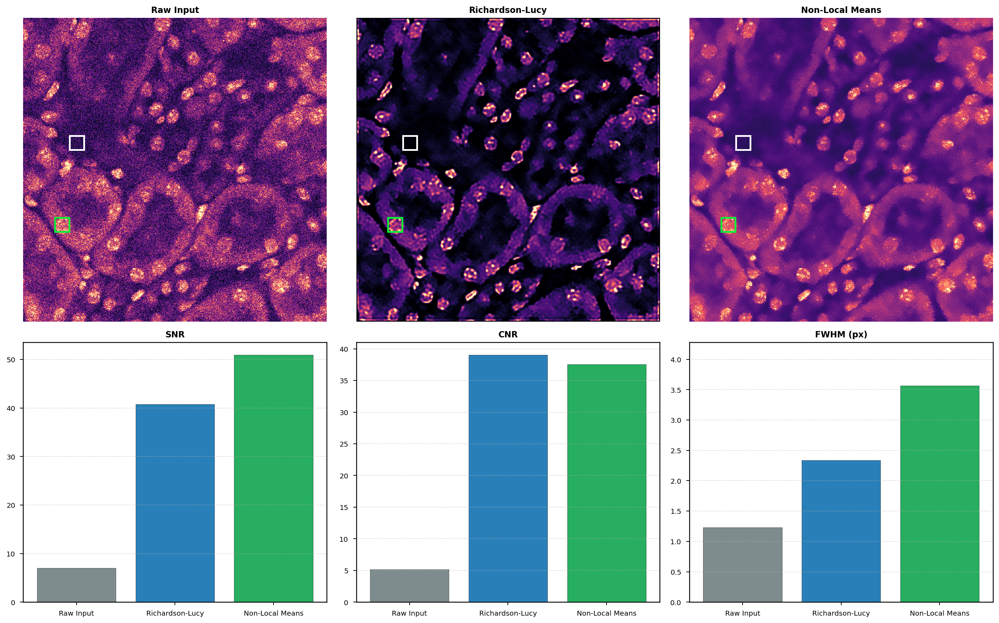

In [37]:
%matplotlib inline 

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from scipy.interpolate import UnivariateSpline
import tifffile as tiff
from skimage import io, img_as_float, restoration
from skimage.morphology import white_tophat, disk
from skimage.filters import unsharp_mask, gaussian
from skimage.exposure import rescale_intensity
from scipy.special import j0
import warnings

warnings.filterwarnings('ignore')

# ─────────────────────────────────────────────────────────────────────────────
# UTILITÀ FISICHE & CALCOLO FWHM LOCALE (FIXED)
# ─────────────────────────────────────────────────────────────────────────────
def _born_wolf_psf(NA, wavelength, ni, pixel_size, size=51, n_samples=256):
    k   = 2 * np.pi * ni / wavelength
    ax  = (np.arange(size) - size // 2) * pixel_size
    rho = np.linspace(0, 1, n_samples)
    psf = np.zeros((size, size))
    for i, x in enumerate(ax):
        for j, y in enumerate(ax):
            r           = np.sqrt(x**2 + y**2)
            integrand   = j0(k * NA * r * rho / ni) * rho
            val         = np.trapz(integrand, rho)
            psf[i, j]   = val ** 2
    return psf / psf.sum()

def calculate_local_fwhm(img, y, x, window=40):
    """Calcola la FWHM solo nell'intorno del nucleo selezionato."""
    # Estraiamo un profilo centrato sul nucleo
    start, end = max(0, x - window), min(img.shape[1], x + window)
    profile = img[y, start:end]
    
    # Normalizzazione locale (baseline subtraction)
    profile = profile - np.min(profile)
    p_max = np.max(profile)
    if p_max == 0: return np.nan
    
    # Interpolazione
    x_axis = np.arange(len(profile))
    spline = UnivariateSpline(x_axis, profile - (p_max / 2.0), s=0)
    roots = spline.roots()
    
    if len(roots) >= 2:
        # Troviamo le due radici più vicine al centro del profilo
        center = window
        idx = np.argsort(np.abs(roots - center))
        return np.abs(roots[idx[1]] - roots[idx[0]])
    return np.nan

# ==========================================
# 2. CARICAMENTO E PIPELINE (IDENTICA)
# ==========================================
_PATH = "/Users/francesco/Repositories /CNR_SNR_3channels/zstack_150mic_50piani_10ripetizioni_50mW_512px_770nm_Ch1.tif"
raw = img_as_float(io.imread(_PATH)[11])

PARAMS = dict(nlm_h=0.80, tophat_r=40, rl_iters=15, unsharp_r=1.5, unsharp_a=0.25)

# [1] DENOISING
img_ansc = 2.0 * np.sqrt(np.maximum(raw, 0) + 3.0 / 8.0)
sigma_est = float(np.mean(restoration.estimate_sigma(img_ansc)))
img_nlm_a = restoration.denoise_nl_means(img_ansc, h=PARAMS['nlm_h']*sigma_est, fast_mode=True, patch_size=5, patch_distance=6)
img_denoised = np.maximum((img_nlm_a / 2.0) ** 2 - 3.0 / 8.0, 0)

# [2] BG REMOVAL
img_bg_removed = white_tophat(img_denoised, disk(PARAMS['tophat_r']))

# [3] DECONVOLUZIONE (B&W PSF)
psf = _born_wolf_psf(NA=0.8, wavelength=0.770, ni=1.000, pixel_size=0.100, size=51)
img_deconv = restoration.richardson_lucy(np.clip(img_bg_removed, 0, None), psf, num_iter=PARAMS['rl_iters'])

# [4] SHARPENING
img_final = unsharp_mask(img_deconv, radius=PARAMS['unsharp_r'], amount=PARAMS['unsharp_a'])

images = {'Raw Input': raw, 'Richardson-Lucy': img_final, 'Non-Local Means': img_denoised}

# ==========================================
# 3. COORDINATE E ANALISI
# ==========================================
y_sig, x_sig = 348, 65 
y_bg, x_bg = 210, 90   
HALF_ROI = 12 # ROI leggermente più grande per includere tutto il nucleo

metrics = {'SNR': [], 'CNR': [], 'FWHM (px)': []}
labels = list(images.keys())

for title, img in images.items():
    # Metriche SNR/CNR
    mu_s = np.mean(img[y_sig-HALF_ROI:y_sig+HALF_ROI, x_sig-HALF_ROI:x_sig+HALF_ROI])
    mu_b = np.mean(img[y_bg-HALF_ROI:y_bg+HALF_ROI, x_bg-HALF_ROI:x_bg+HALF_ROI])
    std_b = np.std(img[y_bg-HALF_ROI:y_bg+HALF_ROI, x_bg-HALF_ROI:x_bg+HALF_ROI]) + 1e-6
    
    metrics['SNR'].append(mu_s / std_b)
    metrics['CNR'].append(np.abs(mu_s - mu_b) / std_b)
    metrics['FWHM (px)'].append(calculate_local_fwhm(img, y_sig, x_sig))

# ==========================================
# 4. PLOTTING
# ==========================================
plt.style.use('seaborn-v0_8-paper')
fig = plt.figure(figsize=(16, 10))
gs = fig.add_gridspec(2, 3, height_ratios=[1.2, 1])
colors = ['#7f8c8d', '#2980b9', '#27ae60']
vmax_vis = np.percentile(raw, 99.5)

for i, (title, img) in enumerate(images.items()):
    ax = fig.add_subplot(gs[0, i])
    ax.imshow(img, cmap='magma', vmin=0, vmax=vmax_vis)
    ax.set_title(title, fontweight='bold')
    ax.axis('off')
    ax.add_patch(patches.Rectangle((x_sig-HALF_ROI, y_sig-HALF_ROI), 2*HALF_ROI, 2*HALF_ROI, linewidth=2, edgecolor="#08f233", fill=False))
    ax.add_patch(patches.Rectangle((x_bg-HALF_ROI, y_bg-HALF_ROI), 2*HALF_ROI, 2*HALF_ROI, linewidth=2, edgecolor='white', fill=False))

for i, (m_name, m_vals) in enumerate(metrics.items()):
    ax_bar = fig.add_subplot(gs[1, i])
    ax_bar.bar(labels, m_vals, color=colors, edgecolor='black')
    ax_bar.set_title(m_name, fontweight='bold')
    if 'FWHM' in m_name:
        ax_bar.set_ylim(0, max(m_vals)*1.2) # Scala corretta
    ax_bar.grid(axis='y', linestyle=':', alpha=0.7)

plt.tight_layout()
plt.show()

Elaborazione pipeline simmetriche...


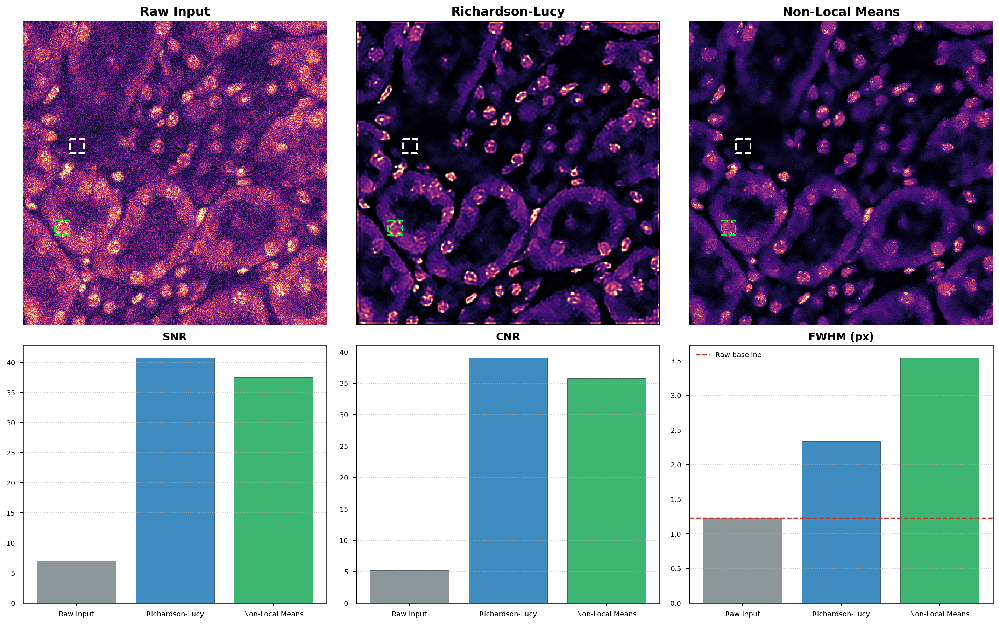

Benchmark terminato. Entrambi i filtri hanno ora il background rimosso.


In [38]:
%matplotlib inline 

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from scipy.interpolate import UnivariateSpline
import tifffile as tiff
from skimage import io, img_as_float, restoration
from skimage.morphology import white_tophat, disk
from skimage.filters import unsharp_mask, gaussian
from skimage.exposure import rescale_intensity
from scipy.special import j0
import warnings

# Nasconde i warning per mantenere pulito l'output
warnings.filterwarnings('ignore')

# ─────────────────────────────────────────────────────────────────────────────
# 1. FUNZIONI FISICHE E METRICHE
# ─────────────────────────────────────────────────────────────────────────────
def _born_wolf_psf(NA, wavelength, ni, pixel_size, size=51, n_samples=256):
    k   = 2 * np.pi * ni / wavelength
    ax  = (np.arange(size) - size // 2) * pixel_size
    rho = np.linspace(0, 1, n_samples)
    psf = np.zeros((size, size))
    for i, x in enumerate(ax):
        for j, y in enumerate(ax):
            r           = np.sqrt(x**2 + y**2)
            integrand   = j0(k * NA * r * rho / ni) * rho
            val         = np.trapz(integrand, rho)
            psf[i, j]   = val ** 2
    return psf / psf.sum()

def calculate_local_fwhm(img, y, x, window=40):
    """Calcola la FWHM locale nell'intorno del nucleo selezionato."""
    start, end = max(0, x - window), min(img.shape[1], x + window)
    profile = img[y, start:end]
    profile = profile - np.min(profile) # Baseline subtraction locale
    p_max = np.max(profile)
    if p_max == 0: return np.nan
    
    x_axis = np.arange(len(profile))
    spline = UnivariateSpline(x_axis, profile - (p_max / 2.0), s=0)
    roots = spline.roots()
    
    if len(roots) >= 2:
        center = window
        idx = np.argsort(np.abs(roots - center))
        return np.abs(roots[idx[1]] - roots[idx[0]])
    return np.nan

# ==========================================
# 2. CARICAMENTO E PARAMETRI
# ==========================================
_PATH = "/Users/francesco/Repositories /CNR_SNR_3channels/zstack_150mic_50piani_10ripetizioni_50mW_512px_770nm_Ch1.tif"
raw = img_as_float(io.imread(_PATH)[11])

PARAMS = dict(nlm_h=0.80, tophat_r=40, rl_iters=15, unsharp_r=1.5, unsharp_a=0.25)
footprint = disk(PARAMS['tophat_r'])

# ==========================================
# 3. ELABORAZIONE CROSS-FILTERED
# ==========================================
print("Elaborazione pipeline simmetriche...")

# --- COMUNE: PRIMO DENOISING (Anscombe + NLM) ---
img_ansc = 2.0 * np.sqrt(np.maximum(raw, 0) + 3.0 / 8.0)
sigma_est = float(np.mean(restoration.estimate_sigma(img_ansc)))
img_den_ans = restoration.denoise_nl_means(img_ansc, h=PARAMS['nlm_h']*sigma_est, fast_mode=True, patch_size=5, patch_distance=6)
img_denoised = np.maximum((img_den_ans / 2.0) ** 2 - 3.0 / 8.0, 0)

# --- [A] NON-LOCAL MEANS FINALE (Ora con Top-Hat per parità) ---
img_nlm = white_tophat(img_denoised, footprint)

# --- [B] RICHARDSON-LUCY FINALE (Catena completa) ---
# 1. Background Removal
img_bg_removed = white_tophat(img_denoised, footprint)
# 2. PSF Born & Wolf
psf = _born_wolf_psf(NA=0.8, wavelength=0.770, ni=1.000, pixel_size=0.100, size=51)
# 3. Deconvoluzione
img_deconv = restoration.richardson_lucy(np.clip(img_bg_removed, 0, None), psf, num_iter=PARAMS['rl_iters'])
# 4. Sharpening
img_rl = unsharp_mask(img_deconv, radius=PARAMS['unsharp_r'], amount=PARAMS['unsharp_a'])

images = {'Raw Input': raw, 'Richardson-Lucy': img_rl, 'Non-Local Means': img_nlm}

# ==========================================
# 4. ANALISI QUANTITATIVA (ROI FISSE)
# ==========================================
y_sig, x_sig = 348, 65 
y_bg, x_bg = 210, 90   
HALF_ROI = 12 

metrics = {'SNR': [], 'CNR': [], 'FWHM (px)': []}
labels = list(images.keys())

for title, img in images.items():
    mu_s = np.mean(img[y_sig-HALF_ROI:y_sig+HALF_ROI, x_sig-HALF_ROI:x_sig+HALF_ROI])
    mu_b = np.mean(img[y_bg-HALF_ROI:y_bg+HALF_ROI, x_bg-HALF_ROI:x_bg+HALF_ROI])
    std_b = np.std(img[y_bg-HALF_ROI:y_bg+HALF_ROI, x_bg-HALF_ROI:x_bg+HALF_ROI]) + 1e-6
    
    metrics['SNR'].append(mu_s / std_b)
    metrics['CNR'].append(np.abs(mu_s - mu_b) / std_b)
    metrics['FWHM (px)'].append(calculate_local_fwhm(img, y_sig, x_sig))

# ==========================================
# 5. PLOTTING
# ==========================================
plt.style.use('seaborn-v0_8-paper')
fig = plt.figure(figsize=(16, 10))
gs = fig.add_gridspec(2, 3, height_ratios=[1.2, 1])
colors = ['#7f8c8d', '#2980b9', '#27ae60']
vmax_vis = np.percentile(raw, 99.5)

for i, (title, img) in enumerate(images.items()):
    ax = fig.add_subplot(gs[0, i])
    ax.imshow(img, cmap='magma', vmin=0, vmax=vmax_vis)
    ax.set_title(title, fontweight='bold', fontsize=14)
    ax.axis('off')
    # Disegno delle ROI per verifica visiva
    ax.add_patch(patches.Rectangle((x_sig-HALF_ROI, y_sig-HALF_ROI), 2*HALF_ROI, 2*HALF_ROI, linewidth=2, edgecolor="#08f233", fill=False, linestyle='--'))
    ax.add_patch(patches.Rectangle((x_bg-HALF_ROI, y_bg-HALF_ROI), 2*HALF_ROI, 2*HALF_ROI, linewidth=2, edgecolor='white', fill=False, linestyle='--'))

for i, (m_name, m_vals) in enumerate(metrics.items()):
    ax_bar = fig.add_subplot(gs[1, i])
    ax_bar.bar(labels, m_vals, color=colors, edgecolor='black', alpha=0.9)
    ax_bar.set_title(m_name, fontweight='bold', fontsize=12)
    ax_bar.grid(axis='y', linestyle=':', alpha=0.7)
    if 'FWHM' in m_name:
        ax_bar.axhline(m_vals[0], color='#c0392b', linestyle='--', label='Raw baseline')
        ax_bar.legend()

plt.tight_layout()
plt.show()
print("Benchmark terminato. Entrambi i filtri hanno ora il background rimosso.")

Elaborazione Canale 1...
Elaborazione Canale 2...
Elaborazione Canale 3...
Elaborazione completata. Generazione dei grafici...


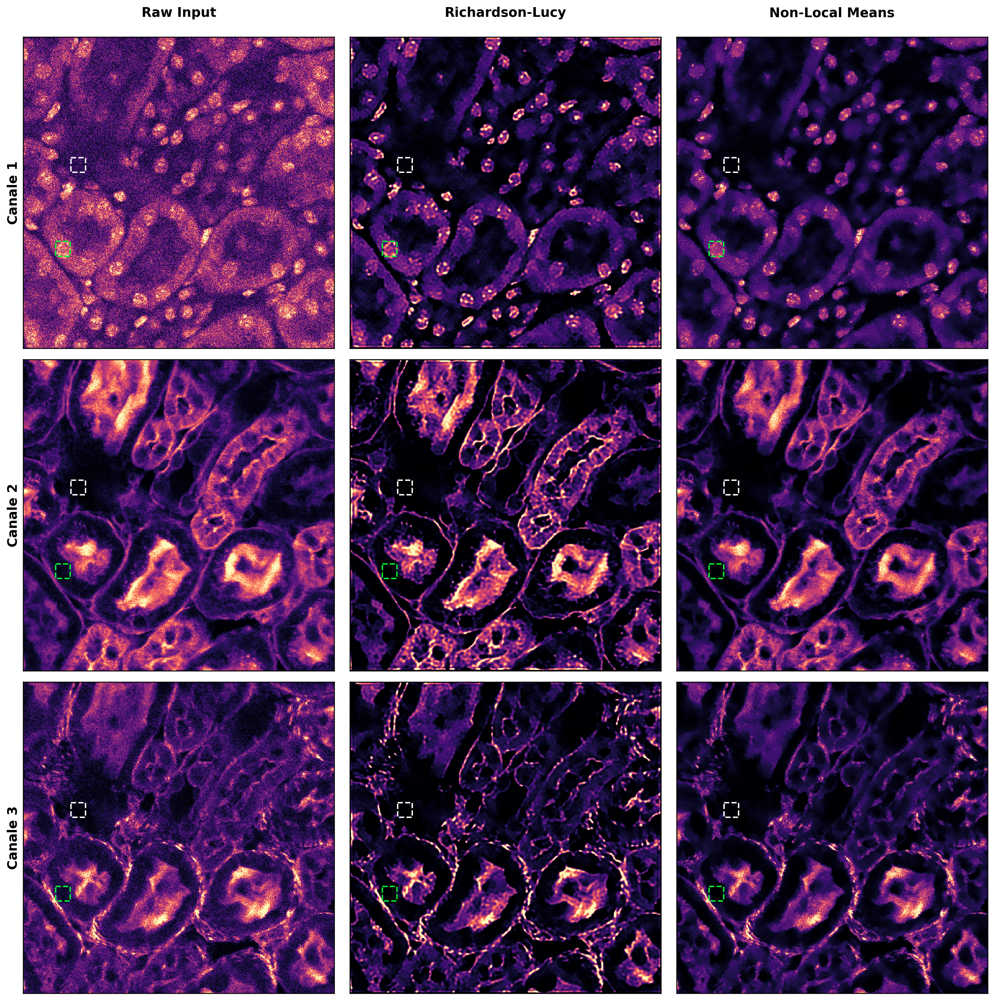

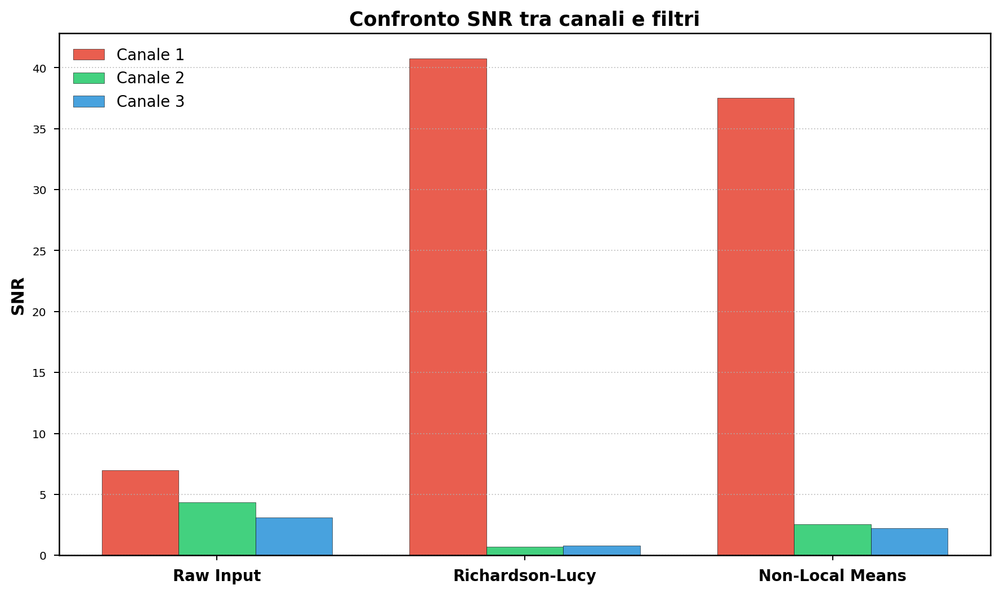

In [39]:
%matplotlib inline 

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from scipy.interpolate import UnivariateSpline
import tifffile as tiff
from skimage import io, img_as_float, restoration
from skimage.morphology import white_tophat, disk
from skimage.filters import unsharp_mask, gaussian
from skimage.exposure import rescale_intensity
from scipy.special import j0
import warnings

# Nasconde i warning per mantenere pulito l'output
warnings.filterwarnings('ignore')

# ─────────────────────────────────────────────────────────────────────────────
# 1. FUNZIONI FISICHE E METRICHE
# ─────────────────────────────────────────────────────────────────────────────
def _born_wolf_psf(NA, wavelength, ni, pixel_size, size=51, n_samples=256):
    k   = 2 * np.pi * ni / wavelength
    ax  = (np.arange(size) - size // 2) * pixel_size
    rho = np.linspace(0, 1, n_samples)
    psf = np.zeros((size, size))
    for i, x in enumerate(ax):
        for j, y in enumerate(ax):
            r           = np.sqrt(x**2 + y**2)
            integrand   = j0(k * NA * r * rho / ni) * rho
            val         = np.trapz(integrand, rho)
            psf[i, j]   = val ** 2
    return psf / psf.sum()

def calculate_local_fwhm(img, y, x, window=40):
    start, end = max(0, x - window), min(img.shape[1], x + window)
    profile = img[y, start:end]
    profile = profile - np.min(profile) 
    p_max = np.max(profile)
    if p_max == 0: return np.nan
    
    x_axis = np.arange(len(profile))
    spline = UnivariateSpline(x_axis, profile - (p_max / 2.0), s=0)
    roots = spline.roots()
    
    if len(roots) >= 2:
        center = window
        idx = np.argsort(np.abs(roots - center))
        return np.abs(roots[idx[1]] - roots[idx[0]])
    return np.nan

# ==========================================
# 2. PARAMETRI E PERCORSI
# ==========================================
# Inserisci qui i percorsi corretti per i tre canali
base_path = "/Users/francesco/Repositories /CNR_SNR_3channels/"
PATHS = [
    base_path + "zstack_150mic_50piani_10ripetizioni_50mW_512px_770nm_Ch1.tif",
    base_path + "zstack_150mic_50piani_10ripetizioni_50mW_512px_770nm_Ch2.tif",
    base_path + "zstack_150mic_50piani_10ripetizioni_50mW_512px_770nm_Ch3.tif"
]

PARAMS = dict(nlm_h=0.80, tophat_r=40, rl_iters=15, unsharp_r=1.5, unsharp_a=0.25)
footprint = disk(PARAMS['tophat_r'])
psf = _born_wolf_psf(NA=0.8, wavelength=0.770, ni=1.000, pixel_size=0.100, size=51)

# Coordinate ROI fisse (assumiamo immagini allineate)
y_sig, x_sig = 348, 65 
y_bg, x_bg = 210, 90   
HALF_ROI = 12 

# Strutture dati per salvare i risultati
all_images = []
all_snr = []

# ==========================================
# 3. ELABORAZIONE PIPELINE (CICLO SUI CANALI)
# ==========================================
labels = ['Raw Input', 'Richardson-Lucy', 'Non-Local Means']

for ch_idx, path in enumerate(PATHS):
    print(f"Elaborazione Canale {ch_idx + 1}...")
    
    try:
        raw = img_as_float(io.imread(path)[11])
    except Exception as e:
        print(f"Errore nel caricamento del Canale {ch_idx + 1}: {e}. Salto...")
        continue

    # --- COMUNE: PRIMO DENOISING (Anscombe + NLM) ---
    img_ansc = 2.0 * np.sqrt(np.maximum(raw, 0) + 3.0 / 8.0)
    sigma_est = float(np.mean(restoration.estimate_sigma(img_ansc)))
    img_den_ans = restoration.denoise_nl_means(img_ansc, h=PARAMS['nlm_h']*sigma_est, fast_mode=True, patch_size=5, patch_distance=6)
    img_denoised = np.maximum((img_den_ans / 2.0) ** 2 - 3.0 / 8.0, 0)

    # --- [A] NON-LOCAL MEANS FINALE ---
    img_nlm = white_tophat(img_denoised, footprint)

    # --- [B] RICHARDSON-LUCY FINALE ---
    img_bg_removed = white_tophat(img_denoised, footprint)
    img_deconv = restoration.richardson_lucy(np.clip(img_bg_removed, 0, None), psf, num_iter=PARAMS['rl_iters'])
    img_rl = unsharp_mask(img_deconv, radius=PARAMS['unsharp_r'], amount=PARAMS['unsharp_a'])

    ch_images = [raw, img_rl, img_nlm]
    all_images.append(ch_images)

    # Calcolo SNR per questo canale
    snr_vals = []
    for img in ch_images:
        mu_s = np.mean(img[y_sig-HALF_ROI:y_sig+HALF_ROI, x_sig-HALF_ROI:x_sig+HALF_ROI])
        std_b = np.std(img[y_bg-HALF_ROI:y_bg+HALF_ROI, x_bg-HALF_ROI:x_bg+HALF_ROI]) + 1e-6
        snr_vals.append(mu_s / std_b)
    
    all_snr.append(snr_vals)

print("Elaborazione completata. Generazione dei grafici...")

# ==========================================
# 4. PLOTTING IMMAGINI (3x3)
# ==========================================
plt.style.use('seaborn-v0_8-paper')
fig_img, axes = plt.subplots(len(all_images), 3, figsize=(15, 5 * len(all_images)))

for i, ch_imgs in enumerate(all_images):
    vmax_vis = np.percentile(ch_imgs[0], 99.5) # normalizzato sul Raw del rispettivo canale
    
    for j, img in enumerate(ch_imgs):
        ax = axes[i, j] if len(all_images) > 1 else axes[j]
        ax.imshow(img, cmap='magma', vmin=0, vmax=vmax_vis)
        
        # Titoli: solo sulla prima riga metti i nomi dei filtri, sulle righe indica il canale
        title = ""
        if i == 0: title += f"{labels[j]}\n"
        if j == 0: ax.set_ylabel(f"Canale {i+1}", fontweight='bold', fontsize=14)
        ax.set_title(title, fontweight='bold', fontsize=14)
        ax.set_xticks([]); ax.set_yticks([])
        
        # Disegno delle ROI
        ax.add_patch(patches.Rectangle((x_sig-HALF_ROI, y_sig-HALF_ROI), 2*HALF_ROI, 2*HALF_ROI, linewidth=1.5, edgecolor="#08f233", fill=False, linestyle='--'))
        ax.add_patch(patches.Rectangle((x_bg-HALF_ROI, y_bg-HALF_ROI), 2*HALF_ROI, 2*HALF_ROI, linewidth=1.5, edgecolor='white', fill=False, linestyle='--'))

plt.tight_layout()
plt.show()

# ==========================================
# 5. PLOTTING SNR SOVRAPPOSTO (BAR CHART RAGGRUPPATO)
# ==========================================
x = np.arange(len(labels))  # Posizioni etichette (Raw, RL, NLM)
width = 0.25                # Larghezza barre
multiplier = -1             # Per centrare il gruppo di barre

fig_snr, ax_snr = plt.subplots(figsize=(10, 6))
colors_ch = ['#e74c3c', '#2ecc71', '#3498db'] # Colori per i 3 canali

for i, snr_vals in enumerate(all_snr):
    offset = width * multiplier
    rects = ax_snr.bar(x + offset, snr_vals, width, label=f'Canale {i+1}', color=colors_ch[i], edgecolor='black', alpha=0.9)
    # ax_snr.bar_label(rects, padding=3, fmt='%.1f') # Opzionale: mostra i valori esatti sopra le barre
    multiplier += 1

ax_snr.set_ylabel('SNR', fontweight='bold', fontsize=12)
ax_snr.set_title('Confronto SNR tra canali e filtri', fontweight='bold', fontsize=14)
ax_snr.set_xticks(x)
ax_snr.set_xticklabels(labels, fontweight='bold', fontsize=11)
ax_snr.legend(loc='upper left', fontsize=11)
ax_snr.grid(axis='y', linestyle=':', alpha=0.7)

plt.tight_layout()
plt.show()

Creazione compositi RGB in corso...
Creazione della griglia RGB 2x2 in corso...


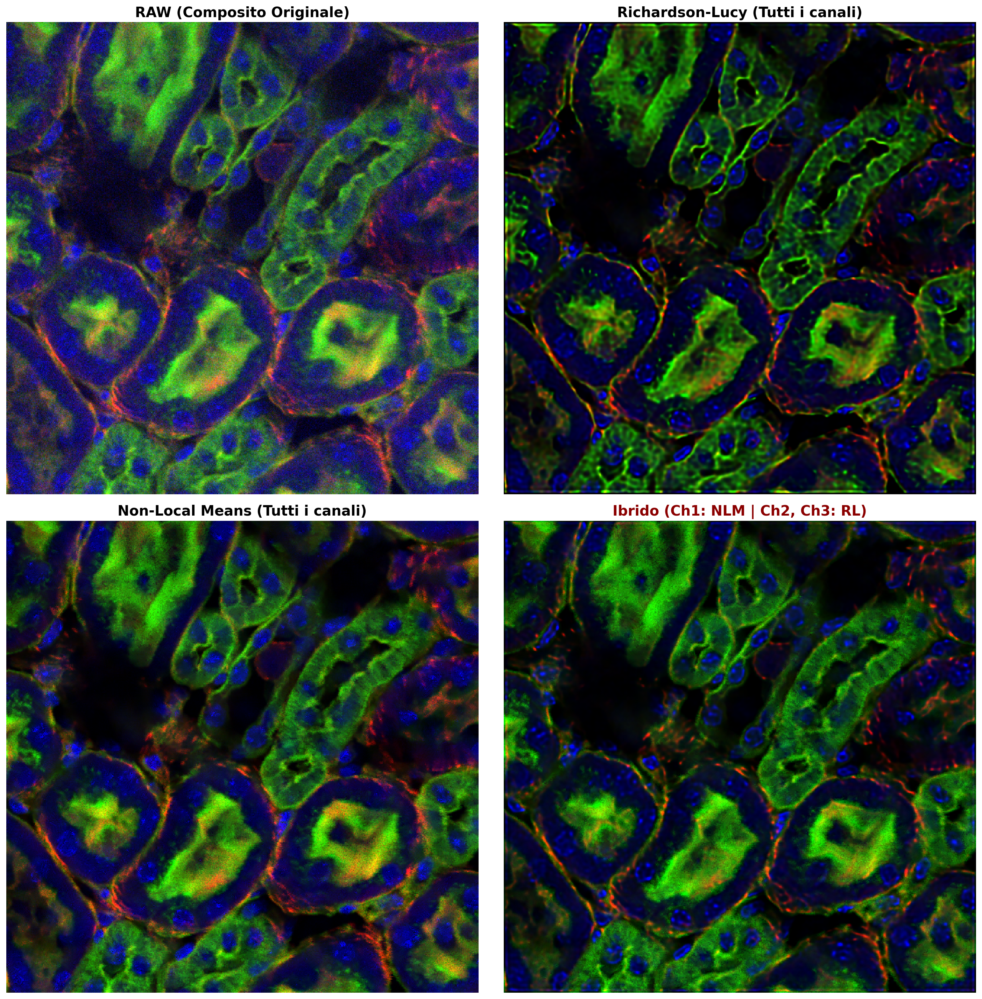

In [47]:
# ==========================================
# 6. COMPOSIZIONE RGB (MERGE DEI CANALI)
# ==========================================

def normalize_for_rgb(image, pmin=0.1, pmax=99.9):
    """
    Normalizza l'immagine tra 0 e 1 usando i percentili 
    per evitare che i pixel aberranti (hot pixel) sbilancino il canale.
    """
    vmin, vmax = np.percentile(image, (pmin, pmax))
    img_rescaled = rescale_intensity(image, in_range=(vmin, vmax), out_range=(0.0, 1.0))
    return img_rescaled

# Assicuriamoci che tutti e 3 i canali siano stati caricati
if len(all_images) == 3:
    print("Creazione compositi RGB in corso...")
    
    # Estrazione delle immagini (Indici: [0]=Raw, [1]=RL, [2]=NLM)
    # Canale 1 -> Blu, Canale 2 -> Verde, Canale 3 -> Rosso
    
    # 1. Preparazione canali Richardson-Lucy (RL)
    B_rl = normalize_for_rgb(all_images[0][1])
    G_rl = normalize_for_rgb(all_images[1][1])
    R_rl = normalize_for_rgb(all_images[2][1])
    
    # Lo stack RGB in Python/Matplotlib richiede l'ordine (Rosso, Verde, Blu)
    rgb_rl = np.dstack((R_rl, G_rl, B_rl))
    
    # 2. Preparazione canali Non-Local Means (NLM)
    B_nlm = normalize_for_rgb(all_images[0][2])
    G_nlm = normalize_for_rgb(all_images[1][2])
    R_nlm = normalize_for_rgb(all_images[2][2])
    
    rgb_nlm = np.dstack((R_nlm, G_nlm, B_nlm))
    
    # ==========================================
    # 7. PLOTTING COMPOSITI RGB
    # ==========================================
    
    
# ==========================================
# 8. GRIGLIA 2x2 COMPOSITI RGB E IBRIDO
# ==========================================

# Assicuriamoci che tutti e 3 i canali siano stati caricati
if len(all_images) == 3:
    print("Creazione della griglia RGB 2x2 in corso...")
    
    # 1. RAW RGB
    B_raw = normalize_for_rgb(all_images[0][0])
    G_raw = normalize_for_rgb(all_images[1][0])
    R_raw = normalize_for_rgb(all_images[2][0])
    rgb_raw = np.dstack((R_raw, G_raw, B_raw))
    
    # 2. RICHARDSON-LUCY (Tutti i canali)
    B_rl = normalize_for_rgb(all_images[0][1])
    G_rl = normalize_for_rgb(all_images[1][1])
    R_rl = normalize_for_rgb(all_images[2][1])
    rgb_rl = np.dstack((R_rl, G_rl, B_rl))
    
    # 3. NON-LOCAL MEANS (Tutti i canali)
    B_nlm = normalize_for_rgb(all_images[0][2])
    G_nlm = normalize_for_rgb(all_images[1][2])
    R_nlm = normalize_for_rgb(all_images[2][2])
    rgb_nlm = np.dstack((R_nlm, G_nlm, B_nlm))
    
    # 4. IBRIDO (Ch1/Blu: NLM | Ch2/Verde: RL | Ch3/Rosso: RL)
    # Ripesco esattamente i canali con il filtro richiesto
    B_mix = normalize_for_rgb(all_images[0][1]) # Canale 1 -> NLM
    G_mix = normalize_for_rgb(all_images[1][2]) # Canale 2 -> RL
    R_mix = normalize_for_rgb(all_images[2][1]) # Canale 3 -> RL
    rgb_mix = np.dstack((R_mix, G_mix, B_mix))
    
    # ==========================================
    # PLOTTING GRIGLIA 2x2
    # ==========================================
    fig_grid, axes_grid = plt.subplots(2, 2, figsize=(16, 16))
    
    # Inserimento Immagini
    axes_grid[0, 0].imshow(rgb_raw)
    axes_grid[0, 0].set_title('RAW (Composito Originale)', fontweight='bold', fontsize=16)
    
    axes_grid[0, 1].imshow(rgb_rl)
    axes_grid[0, 1].set_title('Richardson-Lucy (Tutti i canali)', fontweight='bold', fontsize=16)
    
    axes_grid[1, 0].imshow(rgb_nlm)
    axes_grid[1, 0].set_title('Non-Local Means (Tutti i canali)', fontweight='bold', fontsize=16)
    
    axes_grid[1, 1].imshow(rgb_mix)
    axes_grid[1, 1].set_title('Ibrido (Ch1: NLM | Ch2, Ch3: RL)', fontweight='bold', fontsize=16, color='darkred')
    
    # Formattazione
    for ax in axes_grid.flat:
        ax.axis('off')
        
    plt.tight_layout()
    plt.show()

else:
    print(f"Attenzione: Impossibile creare l'RGB. Sono stati caricati {len(all_images)} canali su 3.")

Caricamento immagini RAW...
Elaborazione canali (Denoising + BG Removal)...
Composizione immagini RGB...


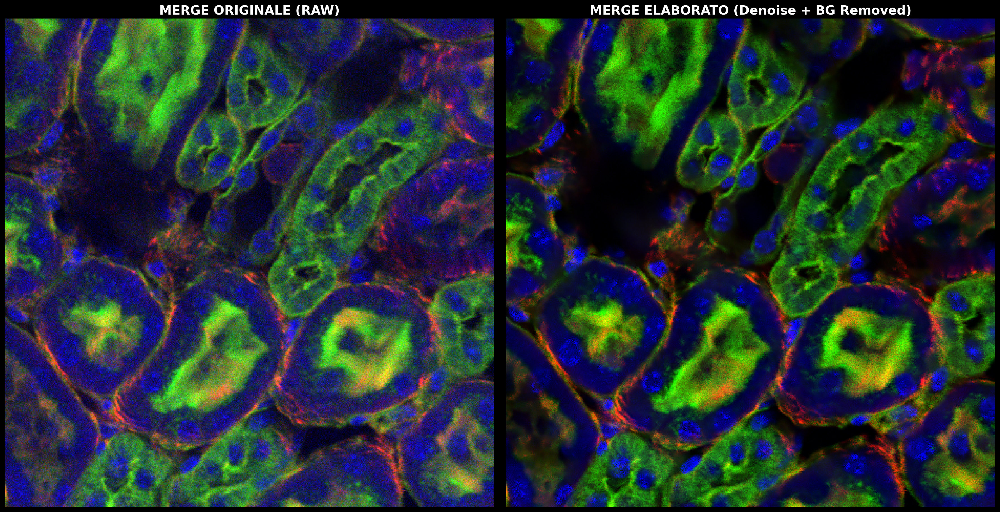

Generazione dei dettagli (ROI)...


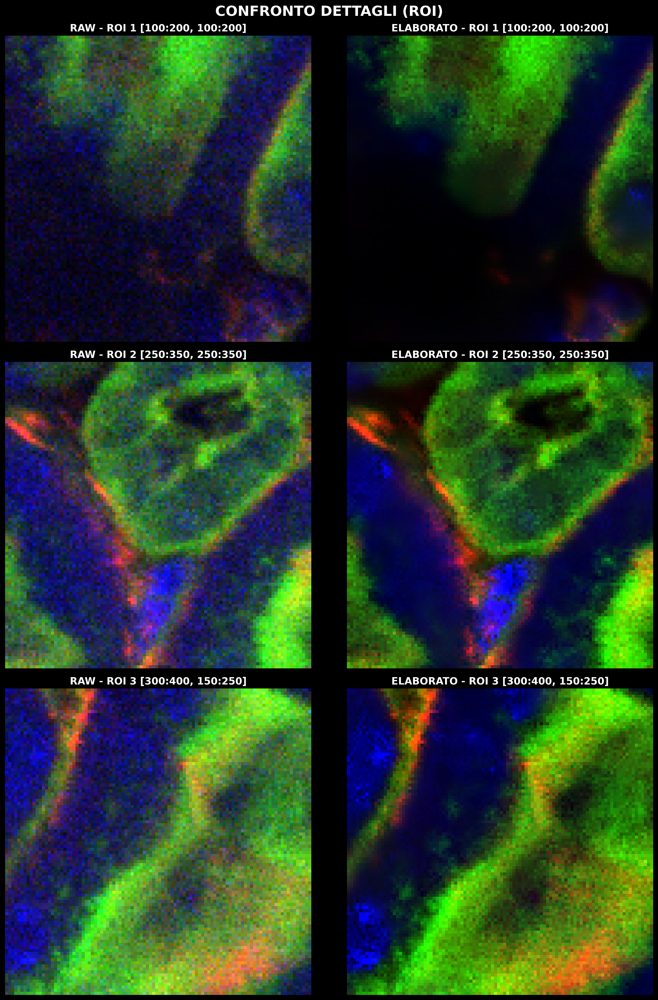

In [41]:
import os
import numpy as np
import matplotlib.pyplot as plt
from skimage import io, img_as_float, restoration
from skimage.morphology import white_tophat, disk
from skimage.exposure import rescale_intensity

# ─────────────────────────────────────────────────────────────────────────────
# CONFIGURAZIONE (Sostituisci i path se necessario)
# ─────────────────────────────────────────────────────────────────────────────
CONFIG = {
    "folder_path": "/Users/francesco/Repositories /CNR_SNR_3channels",
    "file_ch1": "zstack_150mic_50piani_10ripetizioni_50mW_512px_770nm_Ch1.tif", # BLU (Nuclei)
    "file_ch2": "zstack_150mic_50piani_10ripetizioni_50mW_512px_770nm_Ch2.tif", # VERDE 
    "file_ch3": "zstack_150mic_50piani_10ripetizioni_50mW_512px_770nm_Ch3.tif", # ROSSO
    "z_target": 11,
}

# ─────────────────────────────────────────────────────────────────────────────
# FUNZIONE DI ELABORAZIONE SEMPLIFICATA (Fino al BG Removed)
# ─────────────────────────────────────────────────────────────────────────────
def process_to_bg_removed(img, nlm_h=0.8, tophat_radius=40):
    """Esegue Denoising e Background Removal, bypassando Deconvoluzione."""
    
    # 1. Denoising (Anscombe + NLM)
    img_ansc = 2.0 * np.sqrt(np.maximum(img, 0) + 3.0/8.0)
    sigma_est = float(np.mean(restoration.estimate_sigma(img_ansc)))
    img_nlm = restoration.denoise_nl_means(img_ansc, h=nlm_h * sigma_est, fast_mode=True)
    img_denoised = np.maximum((img_nlm / 2.0)**2 - 3.0/8.0, 0)
    
    # 2. Background Removal (White Top-Hat)
    img_bg = white_tophat(img_denoised, disk(tophat_radius))
    
    # Normalizzazione per la visualizzazione [0, 1]
    vmin, vmax = np.percentile(img_bg, (0.1, 99.9))
    return rescale_intensity(img_bg, in_range=(vmin, vmax), out_range=(0.0, 1.0))

def normalize_raw_for_display(img):
    """Normalizza un'immagine RAW senza alterarla, solo per permettere a matplotlib di mostrarla."""
    vmax = np.percentile(img, 99.9)
    return np.clip(img / (vmax + 1e-8), 0, 1)

# ─────────────────────────────────────────────────────────────────────────────
# ESECUZIONE
# ─────────────────────────────────────────────────────────────────────────────
if __name__ == "__main__":
    print("Caricamento immagini RAW...")
    paths = [os.path.join(CONFIG["folder_path"], CONFIG[f"file_ch{i}"]) for i in [1, 2, 3]]
    
    # Carica i dati grezzi
    raw_ch1 = img_as_float(io.imread(paths[0])[CONFIG["z_target"]]) # BLU
    raw_ch2 = img_as_float(io.imread(paths[1])[CONFIG["z_target"]]) # VERDE
    raw_ch3 = img_as_float(io.imread(paths[2])[CONFIG["z_target"]]) # ROSSO

    print("Elaborazione canali (Denoising + BG Removal)...")
    proc_ch1 = process_to_bg_removed(raw_ch1)
    proc_ch2 = process_to_bg_removed(raw_ch2)
    proc_ch3 = process_to_bg_removed(raw_ch3)

    print("Composizione immagini RGB...")
    # --- CREAZIONE MERGE RAW ---
    rgb_raw = np.zeros((*raw_ch1.shape, 3), dtype=np.float32)
    rgb_raw[..., 0] = normalize_raw_for_display(raw_ch3) # ROSSO
    rgb_raw[..., 1] = normalize_raw_for_display(raw_ch2) # VERDE
    rgb_raw[..., 2] = normalize_raw_for_display(raw_ch1) # BLU

    # --- CREAZIONE MERGE PROCESSATO ---
    rgb_proc = np.zeros((*proc_ch1.shape, 3), dtype=np.float32)
    # Moltiplicatori leggeri per bilanciare la visibilità se necessario
    rgb_proc[..., 0] = np.clip(proc_ch3 * 1.0, 0, 1)  # ROSSO
    rgb_proc[..., 1] = np.clip(proc_ch2 * 1.0, 0, 1)  # VERDE
    rgb_proc[..., 2] = np.clip(proc_ch1 * 1.2, 0, 1)  # BLU (Nuclei leggermente boostati)

    # ─────────────────────────────────────────────────────────────────────────────
    # PLOT FINALE COMPARATIVO
    # ─────────────────────────────────────────────────────────────────────────────
    fig, axes = plt.subplots(1, 2, figsize=(20, 10), facecolor='black')
    fig.patch.set_facecolor('black')

    # Immagine RAW
    axes[0].imshow(rgb_raw)
    axes[0].set_title("MERGE ORIGINALE (RAW)", fontsize=18, color='white', fontweight='bold')
    axes[0].axis('off')

    # Immagine Processata
    axes[1].imshow(rgb_proc)
    axes[1].set_title("MERGE ELABORATO (Denoise + BG Removed)", fontsize=18, color='white', fontweight='bold')
    axes[1].axis('off')

    plt.tight_layout()
    plt.show()
    # ─────────────────────────────────────────────────────────────────────────────
    # ZOOM SU 3 ROI (REGIONS OF INTEREST) COMPARATIVE
    # ─────────────────────────────────────────────────────────────────────────────
    print("Generazione dei dettagli (ROI)...")
    
    # Definisci qui le coordinate delle tue 3 ROI. 
    # Formato: (y_start, y_end, x_start, x_end)
    # Esempio basato su immagini 512x512 (box di 100x100 pixel)
    ROIs = [
        (100, 200, 100, 200),  # ROI 1: in alto a sinistra
        (250, 350, 250, 350),  # ROI 2: al centro
        (300, 400, 150, 250)   # ROI 3: in basso a sinistra
    ]

    fig_roi, axes_roi = plt.subplots(3, 2, figsize=(14, 20), facecolor='black')
    fig_roi.patch.set_facecolor('black')
    fig_roi.suptitle("CONFRONTO DETTAGLI (ROI)", fontsize=20, color='white', fontweight='bold', y=0.98)

    for i, (y0, y1, x0, x1) in enumerate(ROIs):
        # Estrai i ritagli
        crop_raw = rgb_raw[y0:y1, x0:x1]
        crop_proc = rgb_proc[y0:y1, x0:x1]

        # Colonna 0: RAW
        ax_raw = axes_roi[i, 0]
        ax_raw.imshow(crop_raw)
        ax_raw.set_title(f"RAW - ROI {i+1} [{y0}:{y1}, {x0}:{x1}]", fontsize=14, color='white')
        ax_raw.axis('off')

        # Colonna 1: PROCESSATO
        ax_proc = axes_roi[i, 1]
        ax_proc.imshow(crop_proc)
        ax_proc.set_title(f"ELABORATO - ROI {i+1} [{y0}:{y1}, {x0}:{x1}]", fontsize=14, color='white')
        ax_proc.axis('off')

        # Aggiungi un piccolo bordo visibile attorno ai crop per staccarli dal fondo nero
        for spine in ax_raw.spines.values():
            spine.set_edgecolor('#333333')
            spine.set_linewidth(1)
        for spine in ax_proc.spines.values():
            spine.set_edgecolor('#333333')
            spine.set_linewidth(1)

    plt.tight_layout()
    plt.subplots_adjust(top=0.95) # Lascia spazio per il titolo globale
    plt.show()

Caricamento immagini RAW...
Calcolo PSF per il Canale 1 (Nuclei)...
Elaborazione canali...
Composizione immagini RGB...


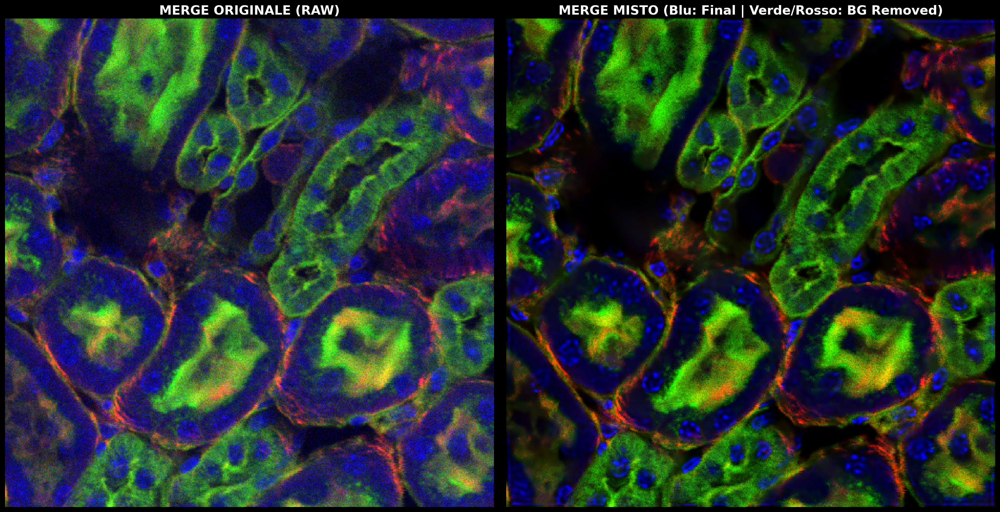

Generazione dei dettagli (ROI)...


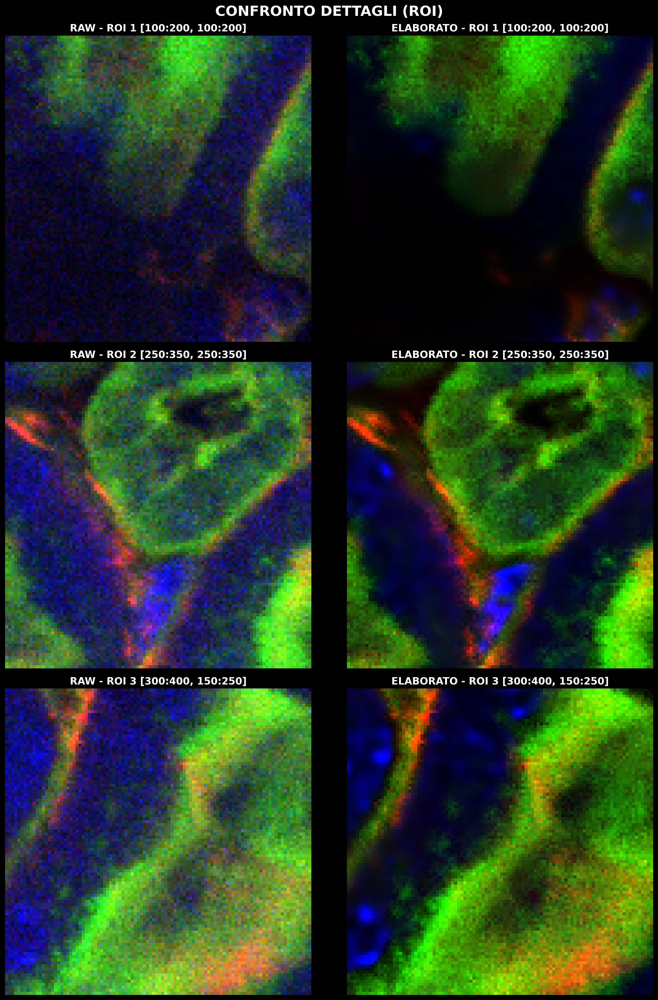

In [42]:
import os
import numpy as np
import matplotlib.pyplot as plt
from skimage import io, img_as_float, restoration
from skimage.morphology import white_tophat, disk
from skimage.exposure import rescale_intensity
from skimage.filters import unsharp_mask
from scipy.special import j0

# ─────────────────────────────────────────────────────────────────────────────
# CONFIGURAZIONE (Sostituisci i path se necessario)
# ─────────────────────────────────────────────────────────────────────────────
CONFIG = {
    "folder_path": "/Users/francesco/Repositories /CNR_SNR_3channels",
    "file_ch1": "zstack_150mic_50piani_10ripetizioni_50mW_512px_770nm_Ch1.tif", # BLU (Nuclei) - PIPELINE COMPLETA
    "file_ch2": "zstack_150mic_50piani_10ripetizioni_50mW_512px_770nm_Ch2.tif", # VERDE - SOLO BG REMOVED
    "file_ch3": "zstack_150mic_50piani_10ripetizioni_50mW_512px_770nm_Ch3.tif", # ROSSO - SOLO BG REMOVED
    "z_target": 11,
}

# ─────────────────────────────────────────────────────────────────────────────
# FUNZIONI DI ELABORAZIONE
# ─────────────────────────────────────────────────────────────────────────────
def _born_wolf_psf(NA=0.8, wavelength=0.770, ni=1.000, pixel_size=0.100, size=51):
    """Calcola la PSF teorica per la deconvoluzione del Canale 1."""
    k = 2 * np.pi * ni / wavelength
    ax = (np.arange(size) - size // 2) * pixel_size
    rho = np.linspace(0, 1, 256)
    psf = np.zeros((size, size))
    for i, x in enumerate(ax):
        for j, y in enumerate(ax):
            r = np.sqrt(x**2 + y**2)
            val = np.trapz(j0(k * NA * r * rho / ni) * rho, rho)
            psf[i, j] = val ** 2
    return psf / psf.sum()

def process_to_final(img, psf, nlm_h=0.8, tophat_radius=40, rl_iters=15, us_rad=1.5, us_amt=0.25):
    """PIPELINE COMPLETA (Step 4): Denoising -> BG Removal -> Deconv -> Sharpening."""
    # 1. Denoising
    img_ansc = 2.0 * np.sqrt(np.maximum(img, 0) + 3.0/8.0)
    sigma_est = float(np.mean(restoration.estimate_sigma(img_ansc)))
    img_nlm = restoration.denoise_nl_means(img_ansc, h=nlm_h * sigma_est, fast_mode=True)
    img_denoised = np.maximum((img_nlm / 2.0)**2 - 3.0/8.0, 0)
    
    # 2. BG Removal
    img_bg = white_tophat(img_denoised, disk(tophat_radius))
    
    # 3. Deconvoluzione R-L
    img_deconv = restoration.richardson_lucy(np.clip(img_bg, 0, None), psf, num_iter=rl_iters, filter_epsilon=1e-6)
    
    # 4. Sharpening
    img_final = unsharp_mask(img_deconv, radius=us_rad, amount=us_amt)
    
    # Normalizzazione [0, 1]
    vmin, vmax = np.percentile(img_final, (0.1, 99.9))
    return rescale_intensity(img_final, in_range=(vmin, vmax), out_range=(0.0, 1.0))

def process_to_bg_removed(img, nlm_h=0.8, tophat_radius=40):
    """PIPELINE PARZIALE (Step 2): Denoising -> BG Removal (Niente deconv/sharpening)."""
    # 1. Denoising
    img_ansc = 2.0 * np.sqrt(np.maximum(img, 0) + 3.0/8.0)
    sigma_est = float(np.mean(restoration.estimate_sigma(img_ansc)))
    img_nlm = restoration.denoise_nl_means(img_ansc, h=nlm_h * sigma_est, fast_mode=True)
    img_denoised = np.maximum((img_nlm / 2.0)**2 - 3.0/8.0, 0)
    
    # 2. Background Removal
    img_bg = white_tophat(img_denoised, disk(tophat_radius))
    
    # Normalizzazione [0, 1]
    vmin, vmax = np.percentile(img_bg, (0.1, 99.9))
    return rescale_intensity(img_bg, in_range=(vmin, vmax), out_range=(0.0, 1.0))

def normalize_raw_for_display(img):
    """Normalizza un'immagine RAW senza alterarla."""
    vmax = np.percentile(img, 99.9)
    return np.clip(img / (vmax + 1e-8), 0, 1)

# ─────────────────────────────────────────────────────────────────────────────
# ESECUZIONE
# ─────────────────────────────────────────────────────────────────────────────
if __name__ == "__main__":
    print("Caricamento immagini RAW...")
    paths = [os.path.join(CONFIG["folder_path"], CONFIG[f"file_ch{i}"]) for i in [1, 2, 3]]
    
    # Carica i dati grezzi
    raw_ch1 = img_as_float(io.imread(paths[0])[CONFIG["z_target"]]) # BLU
    raw_ch2 = img_as_float(io.imread(paths[1])[CONFIG["z_target"]]) # VERDE
    raw_ch3 = img_as_float(io.imread(paths[2])[CONFIG["z_target"]]) # ROSSO

    print("Calcolo PSF per il Canale 1 (Nuclei)...")
    psf = _born_wolf_psf()

    print("Elaborazione canali...")
    # ---> ATTENZIONE: Canale 1 usa la pipeline 'Final', Canali 2 e 3 usano 'BG Removed' <---
    proc_ch1 = process_to_final(raw_ch1, psf)      # BLU: Pipeline Completa
    proc_ch2 = process_to_bg_removed(raw_ch2)      # VERDE: Solo BG Removed
    proc_ch3 = process_to_bg_removed(raw_ch3)      # ROSSO: Solo BG Removed

    print("Composizione immagini RGB...")
    # --- CREAZIONE MERGE RAW ---
    rgb_raw = np.zeros((*raw_ch1.shape, 3), dtype=np.float32)
    rgb_raw[..., 0] = normalize_raw_for_display(raw_ch3) # ROSSO
    rgb_raw[..., 1] = normalize_raw_for_display(raw_ch2) # VERDE
    rgb_raw[..., 2] = normalize_raw_for_display(raw_ch1) # BLU

    # --- CREAZIONE MERGE PROCESSATO ---
    rgb_proc = np.zeros((*proc_ch1.shape, 3), dtype=np.float32)
    rgb_proc[..., 0] = np.clip(proc_ch3 * 1.0, 0, 1)  # ROSSO
    rgb_proc[..., 1] = np.clip(proc_ch2 * 1.0, 0, 1)  # VERDE
    rgb_proc[..., 2] = np.clip(proc_ch1 * 1.2, 0, 1)  # BLU (Nuclei potenziati)

    # ─────────────────────────────────────────────────────────────────────────────
    # PLOT FINALE COMPARATIVO (Immagine intera)
    # ─────────────────────────────────────────────────────────────────────────────
    fig, axes = plt.subplots(1, 2, figsize=(20, 10), facecolor='black')
    fig.patch.set_facecolor('black')

    # Immagine RAW
    axes[0].imshow(rgb_raw)
    axes[0].set_title("MERGE ORIGINALE (RAW)", fontsize=18, color='white', fontweight='bold')
    axes[0].axis('off')

    # Immagine Processata
    axes[1].imshow(rgb_proc)
    axes[1].set_title("MERGE MISTO (Blu: Final | Verde/Rosso: BG Removed)", fontsize=18, color='white', fontweight='bold')
    axes[1].axis('off')

    plt.tight_layout()
    plt.show()

    # ─────────────────────────────────────────────────────────────────────────────
    # ZOOM SU 3 ROI (REGIONS OF INTEREST) COMPARATIVE
    # ─────────────────────────────────────────────────────────────────────────────
    print("Generazione dei dettagli (ROI)...")
    
    ROIs = [
        (100, 200, 100, 200),  # ROI 1: in alto a sinistra
        (250, 350, 250, 350),  # ROI 2: al centro
        (300, 400, 150, 250)   # ROI 3: in basso a sinistra
    ]

    fig_roi, axes_roi = plt.subplots(3, 2, figsize=(14, 20), facecolor='black')
    fig_roi.patch.set_facecolor('black')
    fig_roi.suptitle("CONFRONTO DETTAGLI (ROI)", fontsize=20, color='white', fontweight='bold', y=0.98)

    for i, (y0, y1, x0, x1) in enumerate(ROIs):
        # Estrai i ritagli
        crop_raw = rgb_raw[y0:y1, x0:x1]
        crop_proc = rgb_proc[y0:y1, x0:x1]

        # Colonna 0: RAW
        ax_raw = axes_roi[i, 0]
        ax_raw.imshow(crop_raw)
        ax_raw.set_title(f"RAW - ROI {i+1} [{y0}:{y1}, {x0}:{x1}]", fontsize=14, color='white')
        ax_raw.axis('off')

        # Colonna 1: PROCESSATO
        ax_proc = axes_roi[i, 1]
        ax_proc.imshow(crop_proc)
        ax_proc.set_title(f"ELABORATO - ROI {i+1} [{y0}:{y1}, {x0}:{x1}]", fontsize=14, color='white')
        ax_proc.axis('off')

        for spine in ax_raw.spines.values():
            spine.set_edgecolor('#333333')
            spine.set_linewidth(1)
        for spine in ax_proc.spines.values():
            spine.set_edgecolor('#333333')
            spine.set_linewidth(1)

    plt.tight_layout()
    plt.subplots_adjust(top=0.95) 
    plt.show()

### RELAZIONE:


--- GENERATING FIGURE ---

PDF saved to:
/Users/francesco/Repositories /noise_images/immagini_rel/RL_denoising_pipeline_glued.pdf


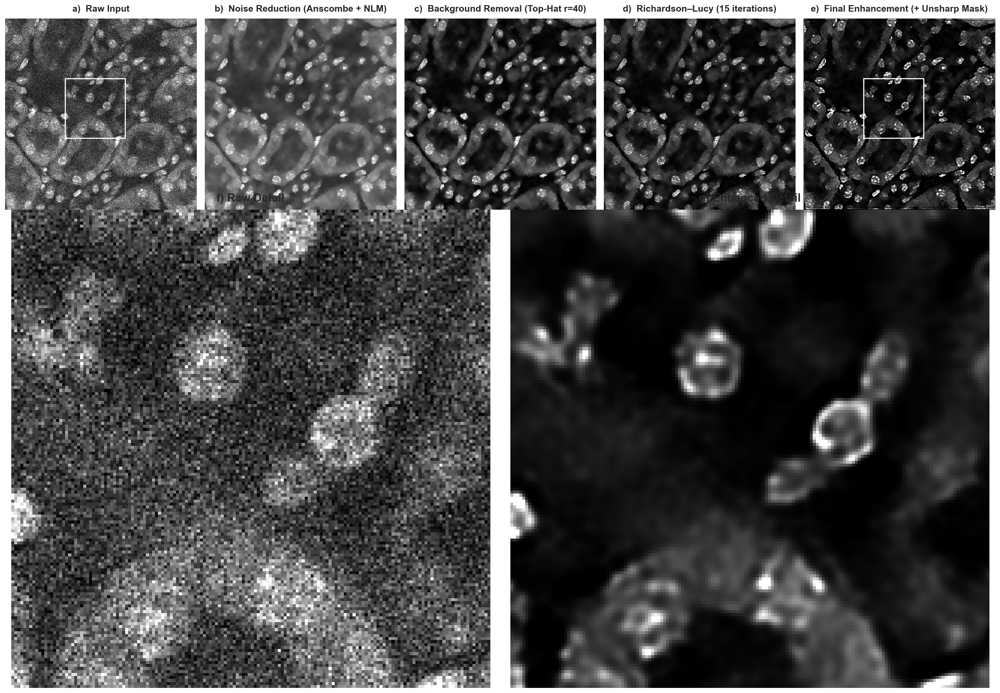


--- PROCESSING COMPLETED ---


In [65]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# =============================================================================
# 0. CONFIGURAZIONE STILE GRAFICO
# =============================================================================
plt.rcParams.update({
    "figure.dpi": 140,
    "savefig.dpi": 400,
    "font.family": "sans-serif",
    "font.weight": "light",
    "axes.labelweight": "light",
    "axes.titleweight": "semibold",
    "axes.titlesize": 13,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "axes.linewidth": 0.8,
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

# =============================================================================
# 4. GENERAZIONE FIGURA
# =============================================================================
print("\n--- GENERATING FIGURE ---")

# Parametri sicuri
r_tophat = PARAMS.get('tophat_r', 40)
iters_rl = PARAMS.get('rl_iters', 15)

# Pipeline immagini
stages = [
    (raw, "Raw Input"),
    (img_denoised, "Noise Reduction (Anscombe + NLM)"),
    (img_bg_removed, f"Background Removal (Top-Hat r={r_tophat})"),
    (img_deconv, f"Richardson–Lucy ({iters_rl} iterations)"),
    (img_final, "Final Enhancement (+ Unsharp Mask)")
]

letters_top = ["a)", "b)", "c)", "d)", "e)"]

# ROI zoom
ROI = (160, 320, 160, 320)
y0, y1, x0, x1 = ROI

# =============================================================================
# FIGURA
# =============================================================================
fig = plt.figure(figsize=(20, 14))

gs = fig.add_gridspec(
    2, 10,
    height_ratios=[1, 2.5],
    hspace=0.0,     # <-- niente spazio verticale
    wspace=0.0      # <-- niente spazio orizzontale
)

# =============================================================================
# RIGA SUPERIORE
# =============================================================================
axes_top = [fig.add_subplot(gs[0, i*2:(i+1)*2]) for i in range(5)]

for idx, (ax, (img, title)) in enumerate(zip(axes_top, stages)):

    vmax = np.percentile(img, 99.5)

    ax.imshow(img, cmap='gray', vmin=0, vmax=vmax, aspect='equal')

    ax.set_title(
        f"{letters_top[idx]}  {title}",
        fontsize=13,
        fontweight='semibold',
        loc='center',
        pad=10
    )

    ax.set_xticks([])
    ax.set_yticks([])
    ax.axis('off')

    # ROI su prima e ultima
    if idx in [0, 4]:
        ax.add_patch(
            patches.Rectangle(
                (x0, y0),
                x1 - x0,
                y1 - y0,
                linewidth=1.5,
                edgecolor='white',
                facecolor='none'
            )
        )

# =============================================================================
# RIGA INFERIORE (ATTACCATA DAVVERO)
# =============================================================================

# RAW DETAIL
ax_zoom_raw = fig.add_subplot(gs[1, 0:5])

ax_zoom_raw.imshow(
    raw[y0:y1, x0:x1],
    cmap='gray',
    vmin=0,
    vmax=np.percentile(raw[y0:y1, x0:x1], 99.5),
    aspect='equal'
)

ax_zoom_raw.set_title(
    "f) Raw Detail",
    fontsize=16,
    fontweight='semibold',
    loc='center',
    pad=12
)

ax_zoom_raw.set_xticks([])
ax_zoom_raw.set_yticks([])
ax_zoom_raw.axis('off')

# FINAL DETAIL
ax_zoom_final = fig.add_subplot(gs[1, 5:10])

ax_zoom_final.imshow(
    img_final[y0:y1, x0:x1],
    cmap='gray',
    vmin=0,
    vmax=np.percentile(img_final[y0:y1, x0:x1], 99.5),
    aspect='equal'
)

ax_zoom_final.set_title(
    "g) Enhanced Detail",
    fontsize=16,
    fontweight='semibold',
    loc='center',
    pad=12
)

ax_zoom_final.set_xticks([])
ax_zoom_final.set_yticks([])
ax_zoom_final.axis('off')

# =============================================================================
# MASSIMO “INCOLLAGGIO” VISIVO
# =============================================================================
plt.subplots_adjust(
    left=0.01,
    right=0.99,
    top=0.97,
    bottom=0.03,
    wspace=0.0,
    hspace=0.0
)

# =============================================================================
# SALVATAGGIO
# =============================================================================
try:
    os.makedirs(SAVE_DIR, exist_ok=True)
    out_dir = SAVE_DIR
except NameError:
    out_dir = "./"

pdf_path = os.path.join(out_dir, "RL_denoising_pipeline_glued.pdf")

plt.savefig(
    pdf_path,
    bbox_inches='tight',
    facecolor='white',
    pad_inches=0.01
)

print(f"\nPDF saved to:\n{pdf_path}")

plt.show()

print("\n--- PROCESSING COMPLETED ---")

Running symmetric processing pipelines...

PDF saved to:
/Users/francesco/Repositories /noise_images/immagini_rel/benchmark_denoising_pipeline.pdf


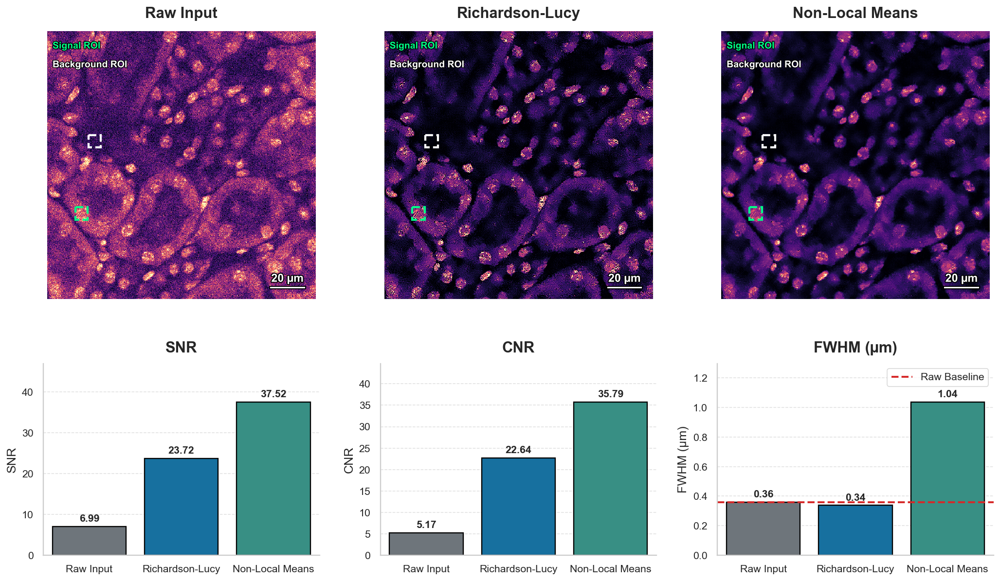


Benchmark completed successfully.


In [58]:
%matplotlib inline

import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import matplotlib.patheffects as pe
import seaborn as sns

from scipy.interpolate import UnivariateSpline
from scipy.special import j0

import tifffile as tiff

from skimage import io, img_as_float, restoration
from skimage.morphology import white_tophat, disk
from skimage.filters import unsharp_mask

import warnings

# Hide warnings for clean output
warnings.filterwarnings('ignore')

# =============================================================================
# 0. SEABORN + MATPLOTLIB PROFESSIONAL STYLE
# =============================================================================
sns.set_theme(
    style="whitegrid",
    context="paper",
    palette="deep",
    font="DejaVu Sans"
)

plt.rcParams.update({
    "figure.dpi": 140,
    "savefig.dpi": 400,
    "axes.titlesize": 16,
    "axes.labelsize": 13,
    "axes.titleweight": "bold",
    "axes.linewidth": 1.2,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "grid.alpha": 0.25,
    "grid.linestyle": "--",
    "font.family": "sans-serif",
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

# =============================================================================
# 1. PHYSICAL FUNCTIONS AND METRICS
# =============================================================================

# --- DATI DI CALIBRAZIONE DA IMAGEJ ---
DIST_PX = 109.0046
DIST_UM = 31.94
PX_SIZE_UM = DIST_UM / DIST_PX       # ~0.293015 µm/px
SCALE_PX_PER_UM = DIST_PX / DIST_UM  # ~3.4133 px/µm

def _born_wolf_psf(NA, wavelength, ni, pixel_size, size=51, n_samples=256):
    k   = 2 * np.pi * ni / wavelength
    ax  = (np.arange(size) - size // 2) * pixel_size
    rho = np.linspace(0, 1, n_samples)

    psf = np.zeros((size, size))

    for i, x in enumerate(ax):
        for j, y in enumerate(ax):
            r = np.sqrt(x**2 + y**2)

            integrand = j0(k * NA * r * rho / ni) * rho
            val = np.trapz(integrand, rho)

            psf[i, j] = val ** 2

    return psf / psf.sum()


def calculate_local_fwhm(img, y, x, window=40):
    """
    Compute local FWHM around selected nucleus.
    Restituisce il valore in PIXEL. La conversione in µm avviene a valle.
    """
    start = max(0, x - window)
    end   = min(img.shape[1], x + window)

    profile = img[y, start:end]
    profile = profile - np.min(profile)

    p_max = np.max(profile)

    if p_max == 0:
        return np.nan

    x_axis = np.arange(len(profile))

    spline = UnivariateSpline(
        x_axis,
        profile - (p_max / 2.0),
        s=0
    )

    roots = spline.roots()

    if len(roots) >= 2:
        center = window
        idx = np.argsort(np.abs(roots - center))

        return np.abs(roots[idx[1]] - roots[idx[0]])

    return np.nan


# =============================================================================
# 2. LOAD DATA AND PARAMETERS
# =============================================================================
_PATH = "/Users/francesco/Repositories /CNR_SNR_3channels/zstack_150mic_50piani_10ripetizioni_50mW_512px_770nm_Ch1.tif"

raw = img_as_float(io.imread(_PATH)[11])

PARAMS = dict(
    nlm_h=0.80,
    tophat_r=40,
    rl_iters=15,
    unsharp_r=1.5,
    unsharp_a=0.25
)

footprint = disk(PARAMS['tophat_r'])

# Output directory
SAVE_DIR = "/Users/francesco/Repositories /noise_images/immagini_rel"
os.makedirs(SAVE_DIR, exist_ok=True)

# =============================================================================
# 3. CROSS-FILTERED PROCESSING
# =============================================================================
print("Running symmetric processing pipelines...")

# -------------------------------------------------------------------------
# COMMON: FIRST DENOISING (Anscombe + NLM)
# -------------------------------------------------------------------------
img_ansc = 2.0 * np.sqrt(np.maximum(raw, 0) + 3.0 / 8.0)

sigma_est = float(np.mean(
    restoration.estimate_sigma(img_ansc)
))

img_den_ans = restoration.denoise_nl_means(
    img_ansc,
    h=PARAMS['nlm_h'] * sigma_est,
    fast_mode=True,
    patch_size=5,
    patch_distance=6
)

img_denoised = np.maximum(
    (img_den_ans / 2.0) ** 2 - 3.0 / 8.0,
    0
)

# -------------------------------------------------------------------------
# [A] FINAL NON-LOCAL MEANS
# -------------------------------------------------------------------------
img_nlm = white_tophat(
    img_denoised,
    footprint
)

# -------------------------------------------------------------------------
# [B] FINAL RICHARDSON-LUCY
# -------------------------------------------------------------------------
img_bg_removed = white_tophat(
    img_denoised,
    footprint
)

psf = _born_wolf_psf(
    NA=0.8,
    wavelength=0.770,
    ni=1.000,
    pixel_size=PX_SIZE_UM, # INIETTATA LA SCALA FISICA REALE
    size=51
)

img_deconv = restoration.richardson_lucy(
    np.clip(img_bg_removed, 0, None),
    psf,
    num_iter=PARAMS['rl_iters']
)

img_rl = unsharp_mask(
    img_deconv,
    radius=PARAMS['unsharp_r'],
    amount=PARAMS['unsharp_a']
)

images = {
    'Raw Input': raw,
    'Richardson-Lucy': img_rl,
    'Non-Local Means': img_nlm
}

# =============================================================================
# 4. QUANTITATIVE ANALYSIS
# =============================================================================
y_sig, x_sig = 348, 65
y_bg, x_bg   = 210, 90

HALF_ROI = 12

metrics = {
    'SNR': [],
    'CNR': [],
    'FWHM (µm)': [] # Modificato per riflettere le grandezze fisiche
}

labels = list(images.keys())

for title, img in images.items():

    mu_s = np.mean(
        img[
            y_sig-HALF_ROI:y_sig+HALF_ROI,
            x_sig-HALF_ROI:x_sig+HALF_ROI
        ]
    )

    mu_b = np.mean(
        img[
            y_bg-HALF_ROI:y_bg+HALF_ROI,
            x_bg-HALF_ROI:x_bg+HALF_ROI
        ]
    )

    std_b = np.std(
        img[
            y_bg-HALF_ROI:y_bg+HALF_ROI,
            x_bg-HALF_ROI:x_bg+HALF_ROI
        ]
    ) + 1e-6

    metrics['SNR'].append(mu_s / std_b)

    metrics['CNR'].append(
        np.abs(mu_s - mu_b) / std_b
    )

    # Convertiamo i pixel misurati in micrometri
    fwhm_px = calculate_local_fwhm(img, y_sig, x_sig)
    metrics['FWHM (µm)'].append(fwhm_px * PX_SIZE_UM)

# =============================================================================
# 5. ULTRA-PROFESSIONAL SCIENTIFIC FIGURE
# =============================================================================
fig = plt.figure(figsize=(18, 10))

gs = fig.add_gridspec(
    2,
    3,
    height_ratios=[1.4, 1],
    hspace=0.28,
    wspace=0.22
)

colors = [
    "#6C757D",
    "#0077B6",
    "#2A9D8F"
]

vmax_vis = np.percentile(raw, 99.5)

# -------------------------------------------------------------------------
# TOP ROW: IMAGES
# -------------------------------------------------------------------------
# Parametri per la scale bar
scalebar_um = 20
scalebar_px = scalebar_um * SCALE_PX_PER_UM
margin = 20

for i, (title, img) in enumerate(images.items()):

    ax = fig.add_subplot(gs[0, i])

    im = ax.imshow(
        img,
        cmap='magma',
        vmin=0,
        vmax=vmax_vis
    )

    ax.set_title(title, pad=14)
    ax.axis('off')

    img_h, img_w = img.shape

    # Disegna la Scale Bar (Rettangolo + Testo)
    rect_scale = patches.Rectangle(
        (img_w - margin - scalebar_px, img_h - margin - 5),
        scalebar_px, 5,
        linewidth=1,
        edgecolor='black',
        facecolor='white',
        zorder=3
    )
    ax.add_patch(rect_scale)
    
    ax.text(
        img_w - margin - (scalebar_px / 2),
        img_h - margin - 10,
        f"{scalebar_um} µm",
        color='white',
        fontsize=12,
        ha='center',
        va='bottom',
        weight='bold',
        path_effects=[pe.withStroke(linewidth=2, foreground="black")],
        zorder=4
    )

    # Signal ROI
    rect_signal = patches.Rectangle(
        (x_sig-HALF_ROI, y_sig-HALF_ROI),
        2*HALF_ROI,
        2*HALF_ROI,
        linewidth=2.2,
        edgecolor="#00FF88",
        linestyle='--',
        fill=False
    )

    # Background ROI
    rect_bg = patches.Rectangle(
        (x_bg-HALF_ROI, y_bg-HALF_ROI),
        2*HALF_ROI,
        2*HALF_ROI,
        linewidth=2.2,
        edgecolor="white",
        linestyle='--',
        fill=False
    )

    ax.add_patch(rect_signal)
    ax.add_patch(rect_bg)

    # Small annotation
    ax.text(
        0.02, 0.96, "Signal ROI", transform=ax.transAxes,
        fontsize=10, color="#00FF88", va='top', weight='bold',
        path_effects=[pe.withStroke(linewidth=1.5, foreground="black")]
    )

    ax.text(
        0.02, 0.89, "Background ROI", transform=ax.transAxes,
        fontsize=10, color="white", va='top', weight='bold',
        path_effects=[pe.withStroke(linewidth=1.5, foreground="black")]
    )

# -------------------------------------------------------------------------
# BOTTOM ROW: METRICS
# -------------------------------------------------------------------------
for i, (m_name, m_vals) in enumerate(metrics.items()):

    ax_bar = fig.add_subplot(gs[1, i])

    bars = sns.barplot(
        x=labels,
        y=m_vals,
        palette=colors,
        ax=ax_bar,
        edgecolor='black',
        linewidth=1.2
    )
    
    # Adatta i limiti delle Y per non sovrapporre il testo ai bordi
    ax_bar.set_ylim(0, max(m_vals) * 1.25)
    
    # Aggiungi griglia di sfondo esteticamente piacevole
    ax_bar.yaxis.grid(True, linestyle='--', alpha=0.6)
    ax_bar.set_axisbelow(True)

    # Add values above bars
    for j, val in enumerate(m_vals):
        ax_bar.text(
            j,
            val + (0.02 * max(m_vals)),
            f"{val:.2f}",
            ha='center',
            va='bottom',
            fontsize=11,
            fontweight='bold'
        )

    ax_bar.set_title(m_name, pad=12)
    ax_bar.set_xlabel("")
    ax_bar.set_ylabel(m_name)

    sns.despine(ax=ax_bar)

    # Baseline for FWHM (Ora rapportata in µm)
    if 'FWHM' in m_name:
        ax_bar.axhline(
            m_vals[0],
            color='#D62828',
            linestyle='--',
            linewidth=2,
            label='Raw Baseline'
        )
        ax_bar.legend(frameon=True)

# -------------------------------------------------------------------------
# GLOBAL TITLE
# -------------------------------------------------------------------------


# =============================================================================
# 6. SAVE HIGH-QUALITY PDF
# =============================================================================
pdf_path = os.path.join(
    SAVE_DIR,
    "benchmark_denoising_pipeline.pdf"
)



plt.savefig(
    pdf_path,
    bbox_inches='tight',
    facecolor='white'
)



print(f"\nPDF saved to:\n{pdf_path}")


plt.show()

print("\nBenchmark completed successfully.")